# Análise Estatística — Ensaio de Fermentabilidade em Felinos

**Função:** Análise estatística independente  
**Modelo experimental:** Delineamento crossover parcial com medidas repetidas  
**Data:** Junho/2026  

## Sumário

1. [Estrutura do Experimento](#1-estrutura-do-experimento)
2. [Protocolo Analítico Padronizado](#2-protocolo-analítico-padronizado)
3. [Análises por Variável](#3-análises-por-variável)
   - 3.1 pH 
   - 3.2 Amônia
   - 3.3 Escore Fecal
   - 3.4 Ácido Acético
   - 3.5 Ácido Propiónico
   - 3.6 Ácido Butírico
   - 3.7 AGCC Total
   - 3.8 Iso-Butírico
   - 3.9 Iso-Valérico
   - 3.10 Valérico
   - 3.11 4-Metil Valérico (4-Methyl Valeric)
   - 3.12 Hexanoico
   - 3.13 Heptanoico
   - 3.14 AGCR Total
   - 3.15 Serotonina
   - 3.16 Tiramina
   - 3.17 Espermidina (Spermidina)
   - 3.18 Cadaverina
   - 3.19 Histamina
   - 3.20 Putrescina
   - 3.21 Espermina (Spermin)
4. [Consolidação Final](#4-consolidação-final)
   - 4.1 Médias Gerais

## 1. Estrutura do Experimento

| Característica | Descrição |
|:---------------|:----------|
| **Sujeitos** | 16 gatos, delineamento crossover parcial |
| **Tratamentos** | CONTROLE, TYN-0.075 (Trat 1), TYN-0.15 (Trat 2), TYN-0.30 (Trat 3) |
| **Tempos** | Dia 0 (basal), Dia 7, Dia 15 |
| **Observações** | 72 (n = 6 por grupo Tratamento×Dia) |
| **Efeito aleatório** | Animal |
| **Modelo** | Mixed Linear Model: Y ~ Tratamento × Dias + (1 | Animal) |

**Nota:** O fator Bloco não foi incluído no modelo. Alguns animais participaram de um ou dois blocos por questões logísticas (disponibilidade de gaiolas). Assume-se que o efeito de bloco é desprezível ou está contido na variabilidade entre animais.

## 2. Protocolo Analítico Padronizado

Todas as variáveis seguem uma estrutura única baseada em modelo linear misto e avaliação hierárquica de pressupostos.

O objetivo do protocolo é garantir **inferência primária consistente**, reduzindo o peso de análises pós-hoc e evitando interpretações infladas de testes exploratórios.

---

### Passo 1 — Análise Descritiva

- Tabela de médias e erro padrão (SEM) por `Tratamento × Dia`
- Médias marginais por Tratamento e por Dia
- Gráfico de perfil com IC 95% ao longo dos dias

---

### Passo 2 — Modelo Principal (Inferência Primária)

- Modelo Linear Misto (MixedLM):

  `Y ~ Tratamento * Dias + (1 | Animal)`

- Inferência baseada exclusivamente nos **testes de Wald**, para:

- Efeito de Tratamento
- Efeito de Dias
- Interação Tratamento × Dias

> Os testes de Wald constituem a **base inferencial primária do estudo**.

---

### Passo 3 — Diagnóstico de Pressupostos

- Shapiro-Wilk (normalidade dos resíduos)
- Levene (homogeneidade de variâncias)
- Inspeção visual (QQ-plot e resíduos vs ajustados)

A decisão do caminho analítico é baseada principalmente na normalidade dos resíduos.

---

### Passo 4 — Classificação de Caminhos Analíticos

---

#### 🔹 Caminho A — Pressupostos adequados

**Critério:**
- Shapiro-Wilk p ≥ 0.05
- Levene p > 0.05

**Interpretação:**
- O modelo MixedLM é considerado plenamente válido
- Inferência baseada exclusivamente nos testes de Wald

**Análises adicionais (apenas exploratórias):**
- Comparações entre níveis de Dias (Tukey HSD)
- Tendências lineares e quadráticas (contrastes polinomiais)
- Contraste planejado (Dia 15: Tratados vs Controle)
- Controle negativo (Dia 7)

> Todas as análises adicionais são **estritamente exploratórias** e não alteram a inferência principal.

---

#### 🔹 Caminho B — Desvios moderados de normalidade

**Critério:**
- Shapiro-Wilk p < 0.05 e ≥ 0.001
- Levene p > 0.05

**Interpretação:**
- O MixedLM ainda é utilizado como inferência principal
- Resultados são interpretados com **cautela adicional**

**Importante:**
- Não há reponderação inferencial por testes adicionais
- Tukey e contrastes são apenas descritivos/exploratórios
- Não são usados como confirmação de efeitos

---

#### 🔹 Caminho C — Violação severa de pressupostos

**Critério:**
- Shapiro-Wilk p < 0.001 ou falha crítica de ajuste/convergência

**Interpretação:**
- Inferência formal do MixedLM é considerada instável
- Resultados são tratados como **descritivos estruturados**

**Consequência:**
- Não há inferência estatística primária confiável
- Apenas tendências e padrões são discutidos
- Testes adicionais não possuem papel inferencial

---

### Passo 5 — Classificação Final da Evidência

A classificação é baseada exclusivamente nos resultados do MixedLM (Wald), com suporte apenas interpretativo das análises complementares.

| Classificação | Critério |
|:--|:--|
| 🟢 Evidência Alta | Efeito significativo no MixedLM (p < 0.05) com padrão consistente no tempo |
| 🟡 Evidência Moderada | Efeito limítrofe (0.05 ≤ p < 0.10) ou padrão inconsistente entre variáveis |
| ⚪ Evidência Insuficiente | Ausência de significância (p ≥ 0.10) sem padrão consistente |

---

### Nota metodológica

As análises pós-hoc (Tukey HSD e contrastes polinomiais) são utilizadas exclusivamente para **interpretação exploratória da dinâmica temporal**, não sendo consideradas evidência inferencial primária sob nenhuma condição.

A inferência estatística do estudo é baseada exclusivamente no modelo linear misto (Wald tests).

In [2]:
import pandas as pd
import numpy as np
from statsmodels.formula.api import mixedlm

import scipy.stats as stats
import matplotlib.pyplot as plt

In [4]:
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 13
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['legend.fontsize'] = 11

In [5]:
df = pd.read_excel('Dados Gerais new 2.xlsx', sheet_name='Fermentabilidade B1 B2')

## PH, Amônia e Escore Fecal

### 3.1 Amonia

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de amônia, utilizando um modelo linear misto com Animal como efeito aleatório.

**Modelo estatístico:**

$$
\text{Amônia}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

onde:

- $\text{Tratamento}$ e $\text{Dia}$ são efeitos fixos;
- $\text{Tratamento} \times \text{Dia}$ é a interação fixa;
- $\text{Animal}$ é o efeito aleatório (intercepto aleatório);
- $\varepsilon \sim \mathcal{N}(0, \sigma^2)$ é o erro residual.

In [13]:
df_clean_amonia = df[['Amonia', 'Tratamento', 'Dias', 'Animais']].copy()

In [14]:
df_clean_amonia['Tratamento'] = df_clean_amonia['Tratamento'].astype('category')
df_clean_amonia['Dias'] = df_clean_amonia['Dias'].astype('category')
df_clean_amonia['Animais'] = df_clean_amonia['Animais'].astype('category')

In [10]:
#df_clean_amonia.info()

#### Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [165]:
resumo = df_clean_amonia.groupby(['Tratamento', 'Dias'])['Amonia'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                   mean    sem
Tratamento Dias               
CONTROLE   0      47.69   7.35
           7      86.39  21.56
           15     50.32  10.28
Trat 1     0      46.69   7.23
           7      60.26  14.37
           15     92.94  16.77
Trat 2     0      56.72  16.24
           7     110.52  11.11
           15    118.60  13.70
Trat 3     0      61.49   9.64
           7     114.91  23.99
           15    113.87  27.24


> **Nota:** O gráfico de perfil com IC 95% está na seção consolidada.

####  Modelo Misto (MixedLM)



In [16]:
modelo = mixedlm("Amonia ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean_amonia, groups=df_clean_amonia["Animais"])
resultado = modelo.fit()

**Saída do modelo:**

In [164]:
print(resultado.summary())

                       Mixed Linear Model Regression Results
Model:                      MixedLM          Dependent Variable:          Amonia   
No. Observations:           72               Method:                      REML     
No. Groups:                 16               Scale:                       1377.2570
Min. group size:            3                Log-Likelihood:              -315.9554
Max. group size:            6                Converged:                   Yes      
Mean group size:            4.5                                                    
-----------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z|  [0.025  0.975]
-----------------------------------------------------------------------------------
Intercept                              47.720   16.133  2.958 0.003  16.100  79.340
C(Tratamento)[T.Trat 1]                 1.035   22.741  0.046 0.964 -43.538  45.607
C(Tratamento)[T

In [101]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue


In [102]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.8803 |
| Dias | 0.1304 |
| Interação Tratamento × Dias | 0.2319 |


 - **Resumo** : 
 <br>
 - p(Trat)=0,880 → Não há evidência de diferença entre tratamentos.

 - p(Dias)=0,130 → Não há evidência de alteração ao longo dos dias.

 - Médias descritivas: Controle no dia 7 (86,4) parece maior que no dia 0 (47,7) e 15 (50,3), mas a variabilidade entre animais  é elevada, gerando erro padrão grande. Por isso o efeito não é significativo.
     

####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

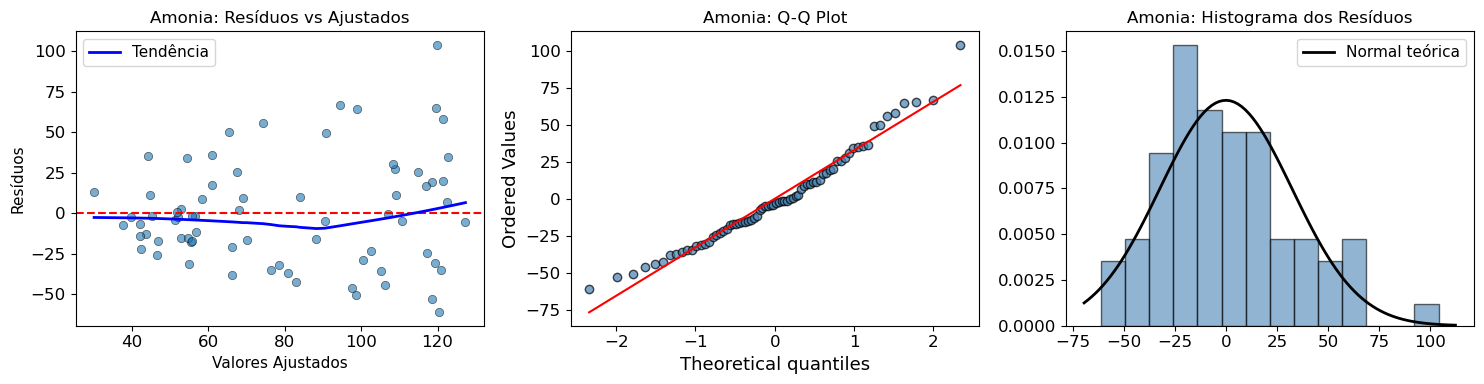


DIAGNÓSTICO DE PRESSUPOSTOS: Amonia
Shapiro-Wilk (Normalidade): W = 0.9684, p = 0.0670
  → Normalidade atendida (p > 0.05) ✅
Levene (Homocedasticidade): W = 2.0835, p = 0.0355
  → ATENÇÃO: Variâncias heterogêneas (p < 0.05) ❌

→ CAMINHO B: Violação moderada. Testes paramétricos com ressalva 



In [17]:
diagnostico_pressupostos(df_clean_amonia,'Amonia',resultado)
print()

**Decisão:** A normalidade foi atendida, mas a homocedasticidade foi violada (Levene p < 0.05).  
→ **Caminho B:** Testes paramétricos mantidos com ressalva, complementados por validação não paramétrica (Kruskal‑Wallis, Mann‑Whitney).

####  Testes Complementares (Caminho B)

##### 4.1 Tukey HSD – Efeito Global de Dias

In [119]:
posthoc_dias(df_clean_amonia, 'Amonia')
print()


POST-HOC TUKEY (Dias): Amonia
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     0      7  39.8765 0.0049  10.5291  69.224   True
     0     15  40.7861  0.004  11.4387 70.1335   True
     7     15   0.9096  0.997 -28.4379  30.257  False
-----------------------------------------------------

Médias por Dia:
       mean    std    sem  count
Dias                            
0     53.15  25.38   5.18     24
7     93.02  47.79   9.76     24
15    93.93  49.76  10.16     24



##### 4.2 Tukey HSD – Tratamentos dentro de cada Dia

In [108]:
# Aplicar
for var in ['Amonia']:
    tukey_por_dia(df_clean_amonia, var)


TUKEY POR DIA: Amonia
  (Comparando Tratamentos dentro de cada Dia)

--- Dia 0 ---
  CONTROLE: 47.7 ± 7.4 (n=6)
  Trat 1: 46.7 ± 7.2 (n=6)
  Trat 2: 56.7 ± 16.2 (n=6)
  Trat 3: 61.5 ± 9.6 (n=6)
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower    upper  reject
-------------------------------------------------------
CONTROLE Trat 1  -1.0033 0.9999 -43.5883 41.5817  False
CONTROLE Trat 2   9.0311 0.9328 -33.5539  51.616  False
CONTROLE Trat 3  13.7965 0.8014 -28.7884 56.3815  False
  Trat 1 Trat 2  10.0344 0.9109 -32.5506 52.6193  False
  Trat 1 Trat 3  14.7998 0.7662 -27.7851 57.3848  False
  Trat 2 Trat 3   4.7655  0.989 -37.8195 47.3504  False
-------------------------------------------------------

--- Dia 7 ---
  CONTROLE: 86.4 ± 21.6 (n=6)
  Trat 1: 60.3 ± 14.4 (n=6)
  Trat 2: 110.5 ± 11.1 (n=6)
  Trat 3: 114.9 ± 24.0 (n=6)
  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1  group2 meandiff p-adj   lower    upper   reject


##### 4.3 Tukey HSD – Dias dentro de cada Tratamento (Estratificado)

In [110]:
for var in ['Amonia']:
    tukey_estratificado_por_tratamento(df_clean_amonia, var)


TUKEY ESTRATIFICADO POR TRATAMENTO: Amonia
  (Comparando Dias dentro de cada Tratamento)

--- CONTROLE ---
  Dia 0: 47.7 ± 7.4 (n=6)
  Dia 7: 86.4 ± 21.6 (n=6)
  Dia 15: 50.3 ± 10.3 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     0      7  38.7013 0.1739 -14.3036 91.7063  False
     0     15   2.6274 0.9909 -50.3775 55.6324  False
     7     15 -36.0739 0.2138 -89.0788 16.9311  False
-----------------------------------------------------

--- Trat 1 ---
  Dia 0: 46.7 ± 7.2 (n=6)
  Dia 7: 60.3 ± 14.4 (n=6)
  Dia 15: 92.9 ± 16.8 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     0      7  13.5748 0.7582 -35.7024  62.852  False
     0     15  46.2512 0.0674   -3.026 95.5284  False
     7     15  32.6764 0.2295 -16.6008 81.9536  False
------------

##### 4.4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (Amonia) [Gráfico 4] ---
Tendência Linear:     coef = 2.6574, p = 0.0004 ✅
Tendência Quadrática: coef = -0.3722, p = 0.0276 ✅
  → Há evidência de tendência LINEAR significativa
  → Há evidência de tendência QUADRÁTICA significativa


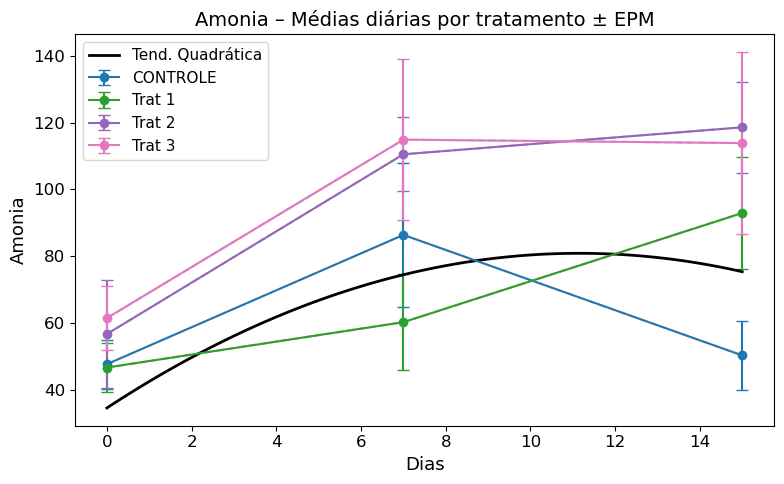

In [37]:
contrastes_polinomiais_4(df_clean_amonia, 'Amonia')
print()

#### 4.5 Contraste Planejado (Wald) – Tratados vs Controle (Dia 15 e Dia 7)

In [112]:
for var in ['Amonia']:
    contrastes_planejados_v2(df_clean_amonia, var)


CONTRASTES PLANEJADOS: Amonia

--- Dia 7 ---
  CONTROLE: 86.4 ± 21.6 (n=6)
  Trat 1: 60.3 ± 14.4 (n=6)
  Trat 2: 110.5 ± 11.1 (n=6)
  Trat 3: 114.9 ± 24.0 (n=6)

--- Dia 15 ---
  CONTROLE: 50.3 ± 10.3 (n=6)
  Trat 1: 92.9 ± 16.8 (n=6)
  Trat 2: 118.6 ± 13.7 (n=6)
  Trat 3: 113.9 ± 27.2 (n=6)

──────────────────────────────────────────────────────────────────────
DIA 15: Tratados (média) vs Controle
──────────────────────────────────────────────────────────────────────
  Controle:          50.3
  Trat 1 (0.075):    92.9
  Trat 2 (0.15):     118.6
  Trat 3 (0.30):     113.9
  Média Tratados:    108.5
  Diferença:         58.2 (115.6%)
  χ² = 9.76, p = 0.0018
  ✅ SIGNIFICATIVO!

──────────────────────────────────────────────────────────────────────
DIA 7: Tratados vs Controle (controle negativo)
──────────────────────────────────────────────────────────────────────
  χ² = 0.24, p = 0.6242
  ✅  NÃO há diferença no Dia 7


####  Classificação Final
-------------------------------------------------------------------------------------------------------------------------------


| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento | Não significativo (Wald p=0.880) |
| Efeito de Dias | Não significativo (Wald p=0.130) |
| Interação Tratamento×Dias | Não significativa (Wald p=0.232) |
| Contraste D15 (Wald) | Significativo (Tratados > Controle: +115.6%, p=0.0018) |
| Controle D7 (Wald) | Não significativo (p=0.624) |
| Tendência | Linear (p=0.0004) e Quadrática (p=0.028) significativas |
| Pressupostos | Normalidade atendida; heterogeneidade de variâncias detectada (Caminho B) |

**Classificação:** 🟡 **EVIDÊNCIA MODERADA** – O modelo misto não identificou efeitos significativos de Tratamento, Dias ou da interação Tratamento×Dias sobre a concentração de amônia (todos p>0.05). Entretanto, análises complementares indicaram um aumento da amônia nos grupos tratados em relação ao Controle no Dia 15 (+115,6%; p=0.0018), além de tendências temporal linear e quadrática significativas. Esses achados devem ser interpretados como evidência exploratória e geradora de hipótese, não constituindo evidência inferencial primária em razão da ausência de significância nos testes globais do modelo misto.

-------------------------------------------------------------------------------------------------------------------------------


### 3.2 pH

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre o pH fecal, utilizando um modelo linear misto com Animal como efeito aleatório.

**Modelo estatístico:**

$$
\text{pH}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

onde:

- $\text{Tratamento}$ e $\text{Dia}$ são efeitos fixos;
- $\text{Tratamento} \times \text{Dia}$ é a interação fixa;
- $\text{Animal}$ é o efeito aleatório (intercepto aleatório);
- $\varepsilon \sim \mathcal{N}(0, \sigma^2)$ é o erro residual.

In [39]:
df_clean = df[['PH', 'Tratamento', 'Dias', 'Animais']].copy()

In [126]:
#df_clean.head()

In [40]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')

In [41]:
df_clean=df_clean.dropna()
# PH precisou remover duas linhas pois não tinham obervaçoes para PH 

In [131]:
#df_clean.info()

#### Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [145]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['PH'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                 mean   sem
Tratamento Dias            
CONTROLE   0     6.08  0.20
           7     6.01  0.21
           15    6.08  0.19
Trat 1     0     6.04  0.17
           7     5.86  0.14
           15    6.22  0.21
Trat 2     0     5.83  0.20
           7     5.96  0.17
           15    5.68  0.11
Trat 3     0     6.04  0.16
           7     5.95  0.07
           15    6.06  0.15


> **Nota:** O gráfico de perfil com IC 95% está na seção consolidada.

####  Modelo Misto (MixedLM)



In [42]:
modelo = mixedlm("PH ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()

**Saída do modelo:**

In [144]:
print(resultado.summary())

                     Mixed Linear Model Regression Results
Model:                      MixedLM         Dependent Variable:         PH      
No. Observations:           70              Method:                     REML    
No. Groups:                 16              Scale:                      0.1088  
Min. group size:            2               Log-Likelihood:             -36.9489
Max. group size:            6               Converged:                  Yes     
Mean group size:            4.4                                                 
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                              5.995    0.201 29.848 0.000  5.601  6.389
C(Tratamento)[T.Trat 1]                0.091    0.259  0.353 0.724 -0.416  0.598
C(Tratamento)[T.Trat 2]               -0.140    0.

In [132]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#print(f"P(Tratamento) = {p_trat:.4f}")
#print(f"P(Dias)       = {p_dias:.4f}")
#print(f"P(Interação)  = {p_inter:.4f}")

In [133]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.7189 |
| Dias | 0.9071 |
| Interação Tratamento × Dias | 0.4197 |


 - **Resumo** : 
 <br>
 - → Nenhum efeito significativo.
 - As médias são muito próximas.
     

####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

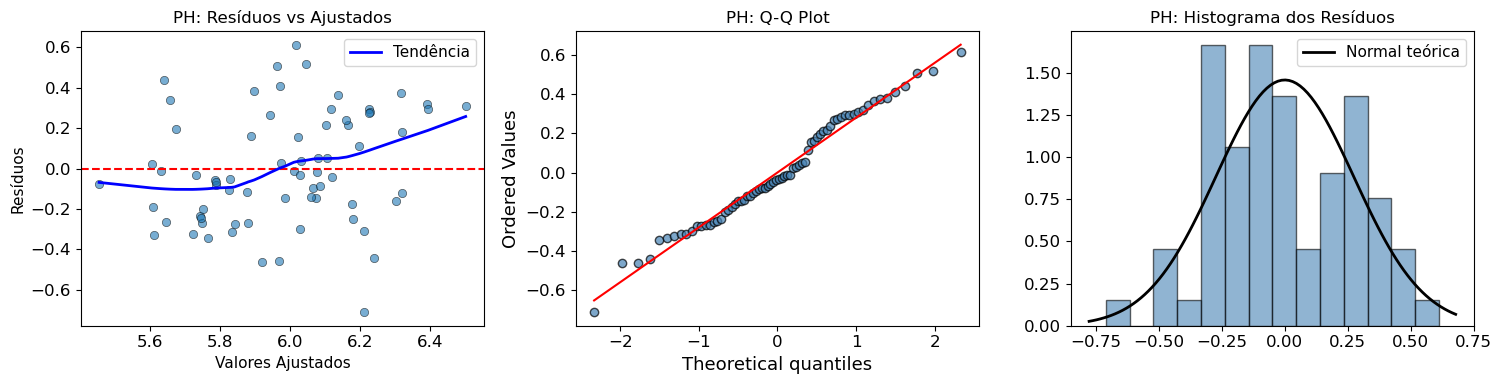


DIAGNÓSTICO DE PRESSUPOSTOS: PH
Shapiro-Wilk (Normalidade): W = 0.9812, p = 0.3770
  → Normalidade atendida (p > 0.05) ✅
Levene (Homocedasticidade): W = 0.6442, p = 0.7835
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO A: Pressupostos atendidos. Seguir com testes paramétricos.



In [24]:
diagnostico_pressupostos(df_clean,'PH',resultado)
print()

####  Testes Complementares (Caminho A)

##### 4.1 Tukey HSD – Efeito Global de Dias

In [135]:
posthoc_dias(df_clean, 'PH')
print()


POST-HOC TUKEY (Dias): PH
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     0      7  -0.0463 0.9204 -0.3323 0.2397  False
     0     15   0.0178 0.9878 -0.2682 0.3038  False
     7     15   0.0642 0.8469 -0.2155 0.3439  False
---------------------------------------------------

Médias por Dia:
      mean   std   sem  count
Dias                         
0     5.99  0.41  0.09     22
7     5.94  0.36  0.07     24
15    6.01  0.44  0.09     24



##### 4.2 Tukey HSD – Tratamentos dentro de cada Dia

In [138]:
# Aplicar
for var in ['PH']:
    tukey_por_dia(df_clean, var)


TUKEY POR DIA: PH
  (Comparando Tratamentos dentro de cada Dia)

--- Dia 0 ---
  CONTROLE: 6.1 ± 0.2 (n=4)
  Trat 1: 6.0 ± 0.2 (n=6)
  Trat 2: 5.8 ± 0.2 (n=6)
  Trat 3: 6.0 ± 0.2 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
-----------------------------------------------------
CONTROLE Trat 1  -0.0425 0.9986 -0.8212 0.7362  False
CONTROLE Trat 2  -0.2525 0.7964 -1.0312 0.5262  False
CONTROLE Trat 3  -0.0408 0.9988 -0.8195 0.7379  False
  Trat 1 Trat 2    -0.21 0.8289 -0.9065 0.4865  False
  Trat 1 Trat 3   0.0017    1.0 -0.6948 0.6982  False
  Trat 2 Trat 3   0.2117 0.8256 -0.4848 0.9082  False
-----------------------------------------------------

--- Dia 7 ---
  CONTROLE: 6.0 ± 0.2 (n=6)
  Trat 1: 5.9 ± 0.1 (n=6)
  Trat 2: 6.0 ± 0.2 (n=6)
  Trat 3: 5.9 ± 0.1 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
---------------------------------------------

##### 4.3 Tukey HSD – Dias dentro de cada Tratamento (Estratificado)

In [139]:
for var in ['PH']:
    tukey_estratificado_por_tratamento(df_clean, var)


TUKEY ESTRATIFICADO POR TRATAMENTO: PH
  (Comparando Dias dentro de cada Tratamento)

--- CONTROLE ---
  Dia 0: 6.1 ± 0.2 (n=4)
  Dia 7: 6.0 ± 0.2 (n=6)
  Dia 15: 6.1 ± 0.2 (n=6)
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     0      7  -0.0742 0.9684 -0.8843  0.736  False
     0     15   0.0025    1.0 -0.8076 0.8126  False
     7     15   0.0767  0.958 -0.6479 0.8013  False
---------------------------------------------------

--- Trat 1 ---
  Dia 0: 6.0 ± 0.2 (n=6)
  Dia 7: 5.9 ± 0.1 (n=6)
  Dia 15: 6.2 ± 0.2 (n=6)
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     0      7  -0.1833 0.7485 -0.8336 0.4669  False
     0     15     0.18 0.7562 -0.4702 0.8302  False
     7     15   0.3633 0.3411 -0.2869 1.0136  False
---------------------------------------------------


##### 4.4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (PH) [Gráfico 4] ---
Tendência Linear:     coef = 0.0020, p = 0.7631 
Tendência Quadrática: coef = 0.0009, p = 0.5426 
  → Nenhuma tendência significativa detectada


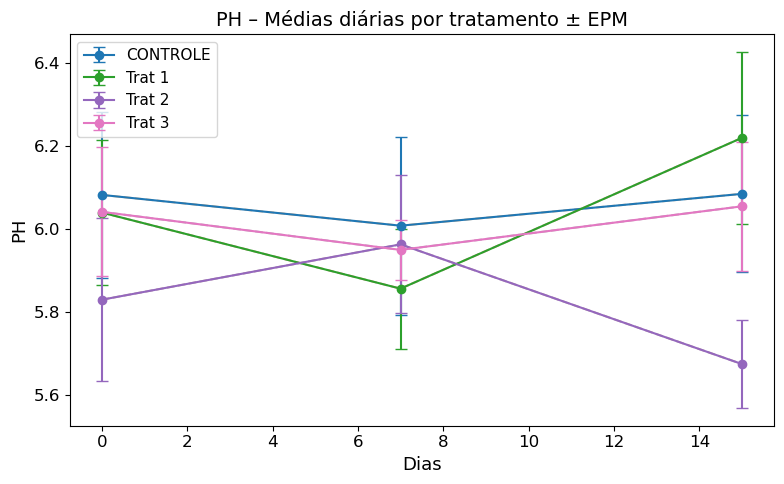

In [43]:
contrastes_polinomiais_4(df_clean, 'PH')
print()

#### 4.5 Contraste Planejado (Wald) – Tratados vs Controle (Dia 15 e Dia 7)

In [141]:
for var in ['PH']:
    contrastes_planejados_v2(df_clean, var)


CONTRASTES PLANEJADOS: PH

--- Dia 7 ---
  CONTROLE: 6.0 ± 0.2 (n=6)
  Trat 1: 5.9 ± 0.1 (n=6)
  Trat 2: 6.0 ± 0.2 (n=6)
  Trat 3: 5.9 ± 0.1 (n=6)

--- Dia 15 ---
  CONTROLE: 6.1 ± 0.2 (n=6)
  Trat 1: 6.2 ± 0.2 (n=6)
  Trat 2: 5.7 ± 0.1 (n=6)
  Trat 3: 6.1 ± 0.2 (n=6)

──────────────────────────────────────────────────────────────────────
DIA 15: Tratados (média) vs Controle
──────────────────────────────────────────────────────────────────────
  Controle:          6.1
  Trat 1 (0.075):    6.2
  Trat 2 (0.15):     5.7
  Trat 3 (0.30):     6.1
  Média Tratados:    6.0
  Diferença:         -0.1 (-1.7%)
  χ² = 0.19, p = 0.6668

──────────────────────────────────────────────────────────────────────
DIA 7: Tratados vs Controle (controle negativo)
──────────────────────────────────────────────────────────────────────
  χ² = 0.12, p = 0.7303
  ✅  NÃO há diferença no Dia 7


####  Classificação Final
-------------------------------------------------------------------------------------------------------------------------------
### Classificação Final

| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento | Não significativo (Wald p=0.719) |
| Efeito de Dias | Não significativo (Wald p=0.907) |
| Interação Tratamento×Dias | Não significativa (Wald p=0.420) |
| Contraste D15 (Wald) | Não significativo (p=0.667) |
| Controle D7 (Wald) | Não significativo (p=0.730) |
| Tendência | Linear (p=0.763) e Quadrática (p=0.543) não significativas |
| Pressupostos | Normalidade e homocedasticidade atendidas (Caminho A) |

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo misto não identificou efeitos significativos de Tratamento, Dias ou da interação Tratamento×Dias sobre o pH fecal (todos p>0.05). As análises complementares (Tukey, contrastes planejados e tendências polinomiais) também não indicaram diferenças significativas, corroborando o resultado global. Portanto, não há evidência estatística robusta de efeito dos tratamentos ou do tempo sobre o pH fecal nas condições avaliadas.


-------------------------------------------------------------------------------------------------------------------------------


### 3.3 Escore Fecal
**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre o escore fecal (escala ordinal de 1 a 4), utilizando um modelo linear misto com Animal como efeito aleatório.

**Nota:** O escore fecal é uma variável ordinal (valores discretos de 1 a 4). O modelo linear misto é robusto a desvios moderados da normalidade, e o diagnóstico de pressupostos indicou que as suposições do modelo foram atendidas, dando suporte à validade das inferências.

**Modelo estatístico:**

$$
\text{EscoreFecal}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$


In [44]:
del df_clean

#### Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [45]:
df_clean = df[['escore_fecal', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [46]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')

In [151]:
#df_clean.info()

In [47]:
df_clean=df_clean.dropna()
# escore_fecal precisou remover duas linhas pois não tinham obervaçoes para escore_fecal 

In [135]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['escore_fecal'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                 mean   sem
Tratamento Dias            
CONTROLE   0     3.25  0.48
           7     3.58  0.27
           15    3.67  0.33
Trat 1     0     2.50  0.22
           7     3.17  0.31
           15    3.33  0.21
Trat 2     0     2.50  0.22
           7     3.00  0.37
           15    3.33  0.21
Trat 3     0     2.67  0.33
           7     3.00  0.26
           15    3.33  0.21


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)



In [48]:
modelo = mixedlm("escore_fecal ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()

**Saída do modelo:**

In [134]:
print(resultado.summary())

                     Mixed Linear Model Regression Results
Model:                    MixedLM        Dependent Variable:        escore_fecal
No. Observations:         70             Method:                    REML        
No. Groups:               16             Scale:                     0.2195      
Min. group size:          2              Log-Likelihood:            -60.6433    
Max. group size:          6              Converged:                 Yes         
Mean group size:          4.4                                                   
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                              3.283    0.305 10.764 0.000  2.685  3.880
C(Tratamento)[T.Trat 1]               -0.895    0.384 -2.332 0.020 -1.647 -0.143
C(Tratamento)[T.Trat 2]               -0.558    0.

In [154]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue


**P-valores globais (Wald Test):**

In [155]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.1339 |
| Dias | 0.6261 |
| Interação Tratamento × Dias | 0.8445 |


 - **Resumo** : 
 <br>
 - p(Trat)=0,134 – embora numericamente os tratamentos 1,2,3 tenham escores mais baixos que o controle, a variabilidade entre animais e o número limitado de repetições impedem significância.
     

####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

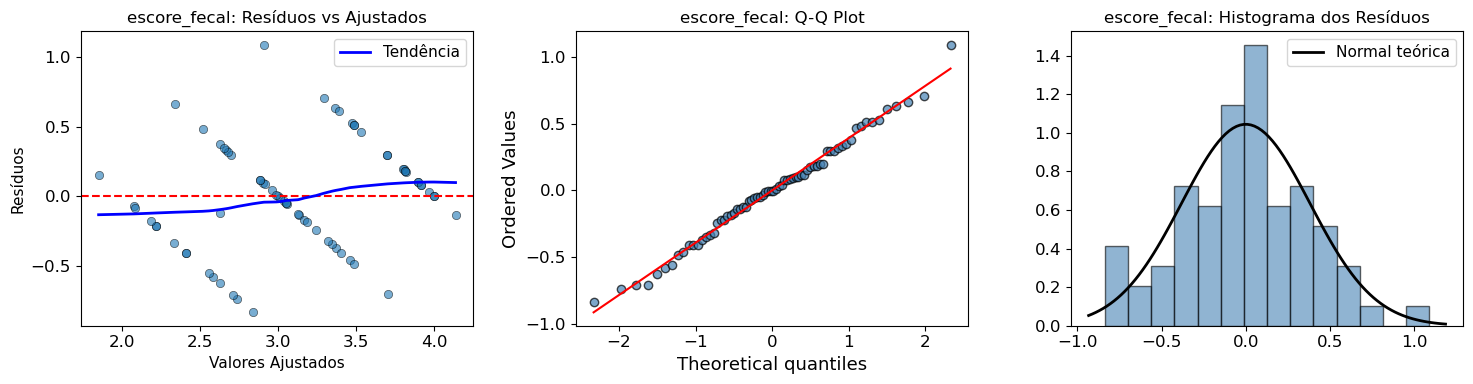


DIAGNÓSTICO DE PRESSUPOSTOS: escore_fecal
Shapiro-Wilk (Normalidade): W = 0.9909, p = 0.8953
  → Normalidade atendida (p > 0.05) ✅
Levene (Homocedasticidade): W = 0.4721, p = 0.9131
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO A: Pressupostos atendidos. Seguir com testes paramétricos.



In [31]:
diagnostico_pressupostos(df_clean,'escore_fecal',resultado)
print()

####  Testes Complementares (Caminho A)

##### 4.1 Tukey HSD – Efeito Global de Dias

In [157]:
posthoc_dias(df_clean, 'escore_fecal')
print()


POST-HOC TUKEY (Dias): escore_fecal
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     0      7   0.5057 0.0373  0.0244  0.987   True
     0     15   0.7348 0.0014  0.2535 1.2162   True
     7     15   0.2292  0.477 -0.2416 0.6999  False
---------------------------------------------------

Médias por Dia:
      mean   std   sem  count
Dias                         
0     2.68  0.72  0.15     22
7     3.19  0.73  0.15     24
15    3.42  0.58  0.12     24



##### 4.2 Tukey HSD – Tratamentos dentro de cada Dia

In [159]:
# Aplicar
for var in ['escore_fecal']:
    tukey_por_dia(df_clean, var)


TUKEY POR DIA: escore_fecal
  (Comparando Tratamentos dentro de cada Dia)

--- Dia 0 ---
  CONTROLE: 3.2 ± 0.5 (n=4)
  Trat 1: 2.5 ± 0.2 (n=6)
  Trat 2: 2.5 ± 0.2 (n=6)
  Trat 3: 2.7 ± 0.3 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
-----------------------------------------------------
CONTROLE Trat 1    -0.75 0.3848  -2.046  0.546  False
CONTROLE Trat 2    -0.75 0.3848  -2.046  0.546  False
CONTROLE Trat 3  -0.5833 0.5913 -1.8793 0.7126  False
  Trat 1 Trat 2      0.0    1.0 -1.1592 1.1592  False
  Trat 1 Trat 3   0.1667 0.9766 -0.9925 1.3258  False
  Trat 2 Trat 3   0.1667 0.9766 -0.9925 1.3258  False
-----------------------------------------------------

--- Dia 7 ---
  CONTROLE: 3.6 ± 0.3 (n=6)
  Trat 1: 3.2 ± 0.3 (n=6)
  Trat 2: 3.0 ± 0.4 (n=6)
  Trat 3: 3.0 ± 0.3 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
-----------------------------------

##### 4.3 Tukey HSD – Dias dentro de cada Tratamento (Estratificado)

In [160]:
for var in ['escore_fecal']:
    tukey_estratificado_por_tratamento(df_clean, var)


TUKEY ESTRATIFICADO POR TRATAMENTO: escore_fecal
  (Comparando Dias dentro de cada Tratamento)

--- CONTROLE ---
  Dia 0: 3.2 ± 0.5 (n=4)
  Dia 7: 3.6 ± 0.3 (n=6)
  Dia 15: 3.7 ± 0.3 (n=6)
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     0      7   0.3333 0.7975 -1.0279 1.6945  False
     0     15   0.4167 0.7047 -0.9445 1.7779  False
     7     15   0.0833 0.9822 -1.1342 1.3008  False
---------------------------------------------------

--- Trat 1 ---
  Dia 0: 2.5 ± 0.2 (n=6)
  Dia 7: 3.2 ± 0.3 (n=6)
  Dia 15: 3.3 ± 0.2 (n=6)
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     0      7   0.6667  0.179 -0.2551 1.5884  False
     0     15   0.8333 0.0794 -0.0884 1.7551  False
     7     15   0.1667 0.8864 -0.7551 1.0884  False
------------------------------------------

##### 4.4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (escore_fecal) [Gráfico 4] ---
Tendência Linear:     coef = 0.0447, p = 0.0000 ✅
Tendência Quadrática: coef = -0.0024, p = 0.2418 
  → Há evidência de tendência LINEAR significativa


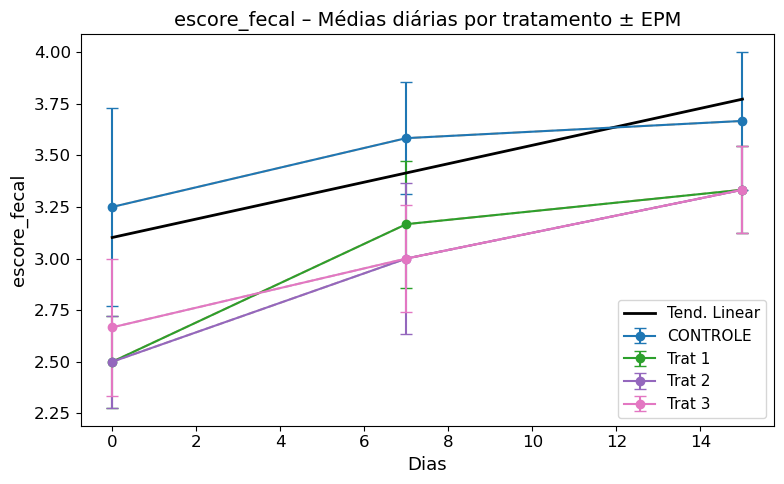

In [49]:
contrastes_polinomiais_4(df_clean, 'escore_fecal')
print()

> A tendência linear é fortemente significativa, indicando um aumento progressivo do escore fecal ao longo do tempo.

##### 4.5 Contraste Planejado (Wald) – Tratados vs Controle (Dia 15 e Dia 7)

In [163]:
for var in ['escore_fecal']:
    contrastes_planejados_v2(df_clean, var)


CONTRASTES PLANEJADOS: escore_fecal

--- Dia 7 ---
  CONTROLE: 3.6 ± 0.3 (n=6)
  Trat 1: 3.2 ± 0.3 (n=6)
  Trat 2: 3.0 ± 0.4 (n=6)
  Trat 3: 3.0 ± 0.3 (n=6)

--- Dia 15 ---
  CONTROLE: 3.7 ± 0.3 (n=6)
  Trat 1: 3.3 ± 0.2 (n=6)
  Trat 2: 3.3 ± 0.2 (n=6)
  Trat 3: 3.3 ± 0.2 (n=6)

──────────────────────────────────────────────────────────────────────
DIA 15: Tratados (média) vs Controle
──────────────────────────────────────────────────────────────────────
  Controle:          3.7
  Trat 1 (0.075):    3.3
  Trat 2 (0.15):     3.3
  Trat 3 (0.30):     3.3
  Média Tratados:    3.3
  Diferença:         -0.3 (-9.1%)
  χ² = 0.38, p = 0.5402

──────────────────────────────────────────────────────────────────────
DIA 7: Tratados vs Controle (controle negativo)
──────────────────────────────────────────────────────────────────────
  χ² = 1.51, p = 0.2190
  ✅  NÃO há diferença no Dia 7


####  Classificação Final
-------------------------------------------------------------------------------------------------------------------------------


| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento | Não significativo (Wald p=0,134) |
| Efeito de Dias | Não significativo (Wald p=0,626) |
| Interação Tratamento×Dias | Não significativa (Wald p=0,845) |
| Tukey – Dias | D0 vs D7: p=0,037; D0 vs D15: p=0,001 |
| Tukey – Tratamentos (cada dia) | Nenhuma comparação significativa |
| Tukey – Dias (cada tratamento) | Nenhuma comparação significativa |
| Contraste D15 (Wald) | Não significativo (p=0,540) |
| Controle D7 (Wald) | Não significativo (p=0,219) |
| Tendência | Linear significativa (p<0,001); Quadrática não significativa (p=0,242) |
| Pressupostos | Normalidade e homocedasticidade atendidas (Caminho A) |
| Natureza da variável | Ordinal (categorias 1 a 4) |

**Classificação:** 🟡 **EVIDÊNCIA MODERADA** – O modelo misto não identificou efeitos significativos de Tratamento, Dias ou da interação Tratamento×Dias (todos p>0,05). Análises complementares indicaram diferenças entre alguns dias no Tukey (D0 vs D7 e D0 vs D15) e uma tendência linear temporal significativa, porém tais achados não são corroborados pelo teste global de Dias (p=0,626) e, portanto, devem ser interpretados apenas como evidência exploratória e geradora de hipótese. Devido à natureza ordinal e ao número limitado de categorias da variável, os resultados devem ser considerados predominantemente exploratórios.

-------------------------------------------------------------------------------------------------------------------------------


### Conclusão Consolidada – pH, Amônia e Escore Fecal

---

As variáveis pH, amônia e escore fecal apresentaram comportamentos distintos quanto à consistência das evidências estatísticas, embora todas tenham sido analisadas por meio de modelos lineares mistos com Animal como efeito aleatório.

**pH:** Não foram identificados efeitos significativos de Tratamento, Dias ou da interação Tratamento × Dias no modelo misto. As análises complementares também não evidenciaram diferenças ou tendências consistentes. Dessa forma, há evidência insuficiente para concluir que o pH fecal tenha sido alterado pelos tratamentos ou pelo período de avaliação.

**Amônia:** Os testes globais do modelo misto não identificaram efeitos significativos de Tratamento, Dias ou da interação Tratamento × Dias. Entretanto, análises complementares, particularmente o contraste planejado no Dia 15, identificaram diferenças entre os grupos tratados e o Controle. Assim, os resultados referentes à amônia devem ser interpretados como evidências exploratórias e geradoras de hipótese, não constituindo evidência inferencial robusta de efeito.

**Escore Fecal:** O modelo misto não identificou efeitos significativos de Tratamento, Dias ou da interação Tratamento × Dias. Embora análises complementares tenham indicado diferenças entre alguns dias e uma tendência linear ao longo do tempo, esses achados não foram corroborados pelo teste global do modelo misto e, portanto, devem ser considerados predominantemente exploratórios.

De forma geral, o conjunto dessas variáveis não forneceu evidência inferencial robusta de efeito dos tratamentos sobre os parâmetros fecais avaliados. As evidências observadas para amônia e escore fecal são complementares e devem ser interpretadas com cautela, sendo mais apropriadas para geração de hipóteses do que para conclusões confirmatórias.

---

#### Graficos

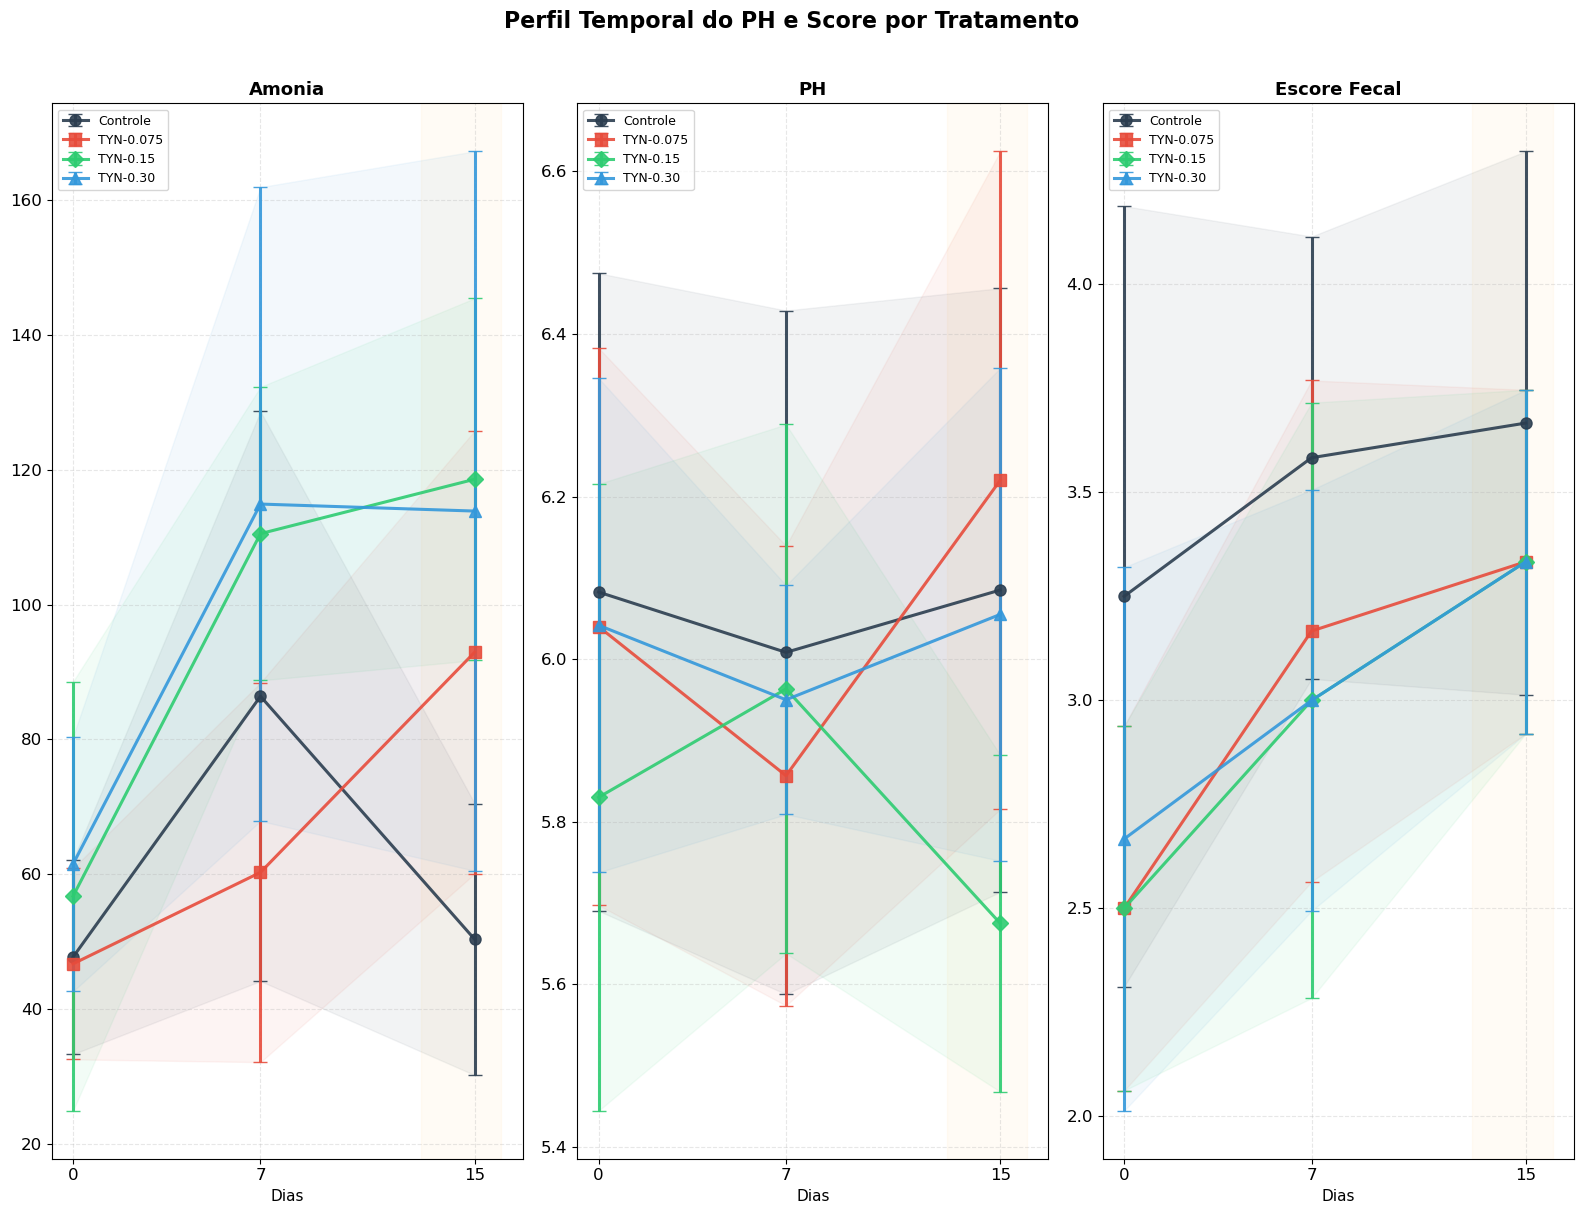

In [177]:
def painel_agcc(df):
    """
    Painel 2x2 com os 4 AGCC lado a lado.
    """
    variaveis = ['Amonia', 'PH', 'escore_fecal']
    titulos = ['Amonia', 'PH', 'Escore Fecal']
    
    tratamentos = ['CONTROLE', 'Trat 1', 'Trat 2', 'Trat 3']
    rotulos = ['Controle', 'TYN-0.075', 'TYN-0.15', 'TYN-0.30']
    cores = ['#2c3e50', '#e74c3c', '#2ecc71', '#3498db']
    marcadores = ['o', 's', 'D', '^']
    dias = [0, 7, 15]
    
    fig, axes = plt.subplots(1, 3, figsize=(16, 12))
    
    for ax, var, tit in zip(axes.flatten(), variaveis, titulos):
        df_clean = df.dropna(subset=[var]).copy()  # Garante que é uma cópia independente
        df_clean['Dias'] = df_clean['Dias'].astype(int)  # Agora sem warnings
        
        for i, (trat, rotulo) in enumerate(zip(tratamentos, rotulos)):
            dados_trat = df_clean[df_clean['Tratamento'] == trat]
            
            medias = []
            ics = []
            
            for dia in dias:
                dados_dia = dados_trat[dados_trat['Dias'] == dia][var]
                if len(dados_dia) > 0:
                    medias.append(dados_dia.mean())
                    ics.append(1.96 * dados_dia.std() / np.sqrt(len(dados_dia)))
                else:
                    medias.append(np.nan)
                    ics.append(np.nan)
            
            ax.errorbar(dias, medias, yerr=ics, 
                       marker=marcadores[i], color=cores[i],
                       linewidth=2.2, markersize=8, capsize=5,
                       label=rotulo, alpha=0.9)
            ax.fill_between(dias,
                           [m - ic for m, ic in zip(medias, ics)],
                           [m + ic for m, ic in zip(medias, ics)],
                           color=cores[i], alpha=0.06)
        
        ax.set_title(tit, fontsize=13, fontweight='bold')
        ax.set_xlabel('Dias', fontsize=11)
        ax.set_xticks(dias)
        ax.set_xticklabels(['0', '7', '15'])
        ax.grid(True, alpha=0.3, linestyle='--')
        ax.legend(fontsize=9, loc='best')
        
        # Destacar Dia 15
        ax.axvspan(13, 16, alpha=0.04, color='orange')
    
    fig.suptitle('Perfil Temporal do PH e Score por Tratamento', 
                 fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()
    


painel_agcc(df)

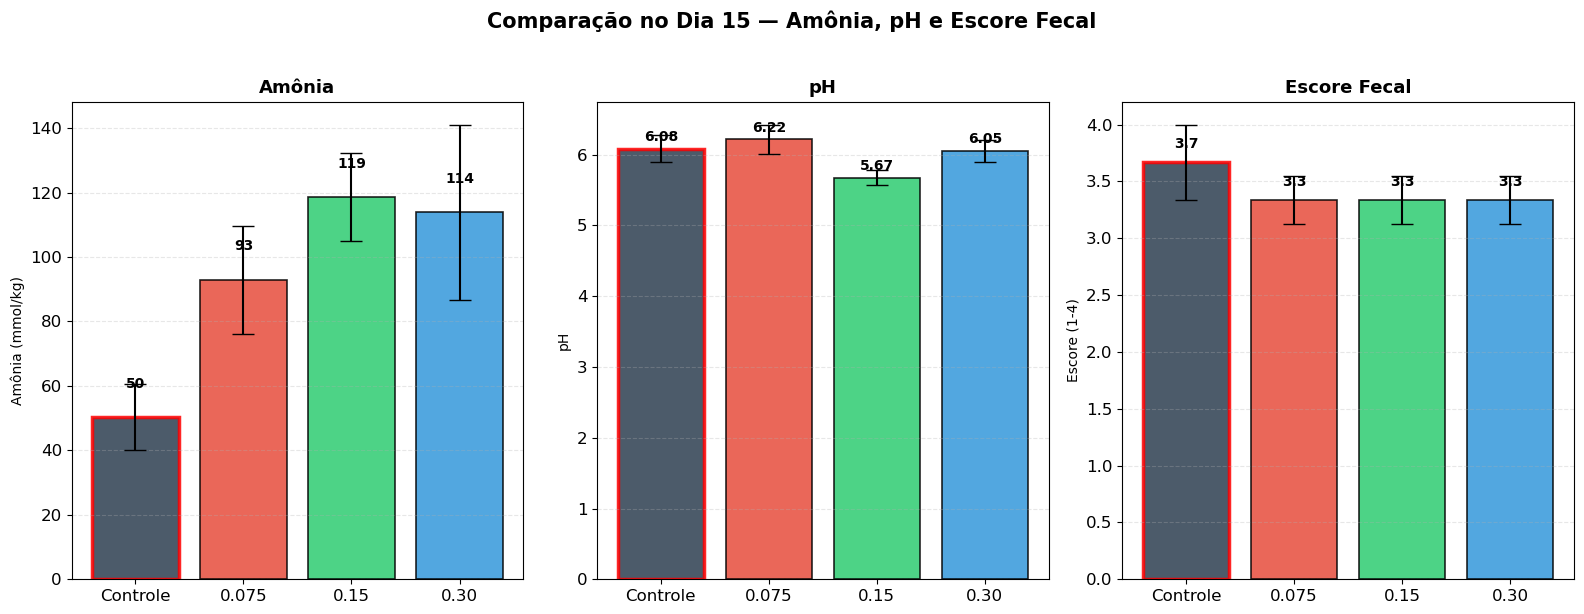

In [178]:
def barras_dia15_extra(df):
    """
    Gráfico de barras comparando tratamentos no Dia 15 para Amônia, pH e Escore Fecal.
    """
    variaveis = ['Amonia', 'PH', 'escore_fecal']
    titulos = ['Amônia', 'pH', 'Escore Fecal']
    ylabels = ['Amônia (mmol/kg)', 'pH', 'Escore (1-4)']
    cores = ['#2c3e50', '#e74c3c', '#2ecc71', '#3498db']
    # Formatos de número: 0 casas para amônia, 2 para pH, 1 para escore
    fmt = ['{:.0f}', '{:.2f}', '{:.1f}']
    
    fig, axes = plt.subplots(1, 3, figsize=(16, 6))
    
    for ax, var, tit, ylab, f in zip(axes, variaveis, titulos, ylabels, fmt):
        # Cópia independente para evitar warnings
        df_clean = df.dropna(subset=[var]).copy()
        df_clean['Dias'] = df_clean['Dias'].astype(int)
        dados_d15 = df_clean[df_clean['Dias'] == 15]
        
        tratamentos = ['CONTROLE', 'Trat 1', 'Trat 2', 'Trat 3']
        rotulos = ['Controle', '0.075', '0.15', '0.30']
        
        medias = []
        sems = []
        
        for trat in tratamentos:
            vals = dados_d15[dados_d15['Tratamento'] == trat][var]
            if len(vals) > 0:
                medias.append(vals.mean())
                sems.append(vals.std() / np.sqrt(len(vals)))
            else:
                medias.append(0)
                sems.append(0)
        
        bars = ax.bar(rotulos, medias, yerr=sems, color=cores, 
                     edgecolor='black', linewidth=1.2, capsize=8, alpha=0.85)
        
        # Adicionar valores formatados nas barras
        for bar, media in zip(bars, medias):
            ax.text(bar.get_x() + bar.get_width()/2, 
                    bar.get_height() + max(sems) * 0.3,
                    f.format(media), ha='center', va='bottom', 
                    fontsize=10, fontweight='bold')
        
        ax.set_title(tit, fontsize=13, fontweight='bold')
        ax.set_ylabel(ylab, fontsize=10)
        ax.grid(True, alpha=0.3, linestyle='--', axis='y')
        
        # Destacar a barra do Controle
        bars[0].set_edgecolor('red')
        bars[0].set_linewidth(2.5)
    
    fig.suptitle('Comparação no Dia 15 — Amônia, pH e Escore Fecal', 
                 fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

barras_dia15_extra(df)

## Ácidos graxos de cadeia curta

### 3.4 Ácido Acético

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo experimental e da interação Tratamento × Tempo sobre a concentração de ácido acético, utilizando um modelo linear misto com Animal como efeito aleatório.

**Modelo estatístico:**

$$
\text{Acético}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

onde:

- $\text{Tratamento}$ e $\text{Dia}$ são efeitos fixos;
- $\text{Tratamento} \times \text{Dia}$ é a interação fixa;
- $\text{Animal}$ é o efeito aleatório (intercepto aleatório);
- $\varepsilon \sim \mathcal{N}(0, \sigma^2)$ é o erro residual.

####  Análise Descritiva


**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [9]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['acetico'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                    mean     sem
Tratamento Dias                 
CONTROLE   0      535.26   72.88
           7      866.24  139.01
           15     525.85  132.25
Trat 1     0      536.66   66.48
           7      715.58  127.48
           15     948.37  114.44
Trat 2     0      612.27  141.71
           7     1041.40  189.81
           15     882.91  150.79
Trat 3     0      703.12  139.68
           7      985.28  137.78
           15    1040.38  147.93


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

In [52]:
df_clean = df[['acetico', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [53]:

df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')

####  Modelo Misto (MixedLM)



In [54]:
modelo = mixedlm("acetico ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()

**Saída do modelo:**

In [13]:
print(resultado.summary())

                        Mixed Linear Model Regression Results
Model:                      MixedLM           Dependent Variable:           acetico   
No. Observations:           72                Method:                       REML      
No. Groups:                 16                Scale:                        89270.6971
Min. group size:            3                 Log-Likelihood:               -442.6463 
Max. group size:            6                 Converged:                    Yes       
Mean group size:            4.5                                                       
--------------------------------------------------------------------------------------
                                        Coef.   Std.Err.   z    P>|z|  [0.025   0.975]
--------------------------------------------------------------------------------------
Intercept                               563.327  138.409  4.070 0.000  292.049 834.604
C(Tratamento)[T.Trat 1]                  16.702  189.012  0.088 0.93

In [18]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue


**P-valores globais (Wald Test):**

In [17]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.9127 |
| Dias | 0.0800 |
| Interação Tratamento × Dias | 0.3034 |


####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

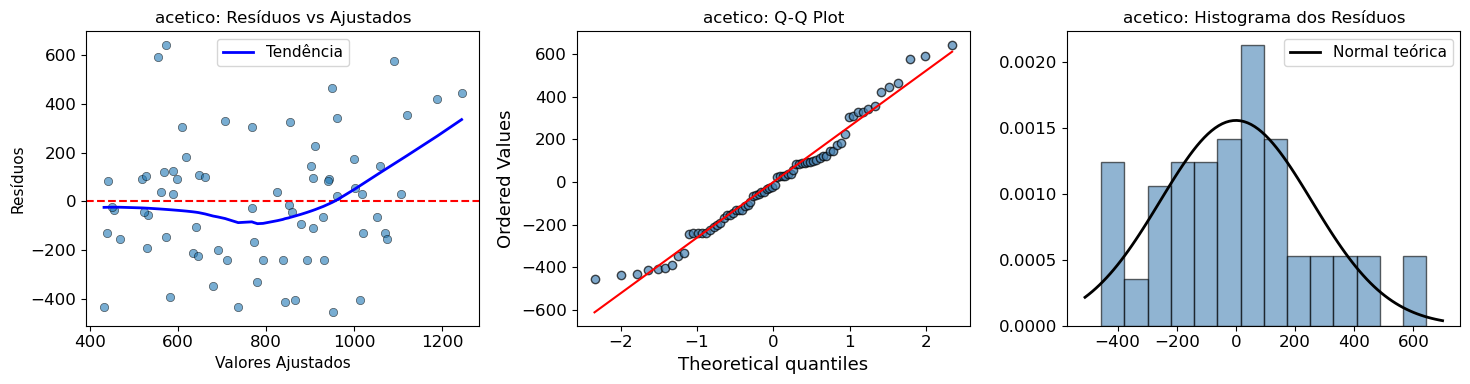


DIAGNÓSTICO DE PRESSUPOSTOS: acetico
Shapiro-Wilk (Normalidade): W = 0.9743, p = 0.1470
  → Normalidade atendida (p > 0.05) ✅
Levene (Homocedasticidade): W = 0.6775, p = 0.7541
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO A: Pressupostos atendidos. Seguir com testes paramétricos.



In [56]:
diagnostico_pressupostos(df_clean, 'acetico', resultado)
print()

**Decisão:** Pressupostos atendidos → **Caminho A**

####  Testes Complementares (Caminho A)

##### 4.1 Tukey HSD – Efeito Global de Dias

In [222]:
posthoc_dias(df_clean, 'acetico')


POST-HOC TUKEY (Dias): acetico
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj    lower    upper   reject
-------------------------------------------------------
     0      7 305.2997  0.007   72.0106 538.5889   True
     0     15 252.5508 0.0308   19.2617   485.84   True
     7     15 -52.7489 0.8511 -286.0381 180.5403  False
-------------------------------------------------------

Médias por Dia:
        mean     std    sem  count
Dias                              
0     596.83  263.20  53.73     24
7     902.13  366.65  74.84     24
15    849.38  371.17  75.77     24


Observou-se um aumento significativo do ácido acético ao longo dos dias (Tukey HSD: Dia 0 vs 7, p=0,007; Dia 0 vs 15, p=0,031; contraste linear, p=0,008), embora o efeito global de Dias no modelo misto não tenha atingido significância formal (p=0,080).

##### 4.2 Tukey HSD – Tratamentos dentro de cada Dia

In [25]:
# Aplicar
for var in ['acetico']:
    tukey_por_dia(df, var)


TUKEY POR DIA: acetico
  (Comparando Tratamentos dentro de cada Dia)

--- Dia 0 ---
  CONTROLE: 535.3 ± 72.9 (n=6)
  Trat 1: 536.7 ± 66.5 (n=6)
  Trat 2: 612.3 ± 141.7 (n=6)
  Trat 3: 703.1 ± 139.7 (n=6)
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1  group2 meandiff p-adj    lower    upper   reject
---------------------------------------------------------
CONTROLE Trat 1   1.4012    1.0 -438.1415 440.9439  False
CONTROLE Trat 2  77.0127 0.9603 -362.5299 516.5554  False
CONTROLE Trat 3 167.8571 0.7118 -271.6856 607.3998  False
  Trat 1 Trat 2  75.6115 0.9623 -363.9312 515.1542  False
  Trat 1 Trat 3 166.4559  0.717 -273.0868 605.9985  False
  Trat 2 Trat 3  90.8444 0.9374 -348.6983  530.387  False
---------------------------------------------------------

--- Dia 7 ---
  CONTROLE: 866.2 ± 139.0 (n=6)
  Trat 1: 715.6 ± 127.5 (n=6)
  Trat 2: 1041.4 ± 189.8 (n=6)
  Trat 3: 985.3 ± 137.8 (n=6)
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1  group2 mea

##### 4.3 Tukey HSD – Dias dentro de cada Tratamento (Estratificado)

In [29]:
for var in ['acetico']:
    tukey_estratificado_por_tratamento(df, var)


TUKEY ESTRATIFICADO POR TRATAMENTO: acetico
  (Comparando Dias dentro de cada Tratamento)

--- CONTROLE ---
  Dia 0: 535.3 ± 72.9 (n=6)
  Dia 7: 866.2 ± 139.0 (n=6)
  Dia 15: 525.8 ± 132.3 (n=6)
  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower    upper   reject
--------------------------------------------------------
     0      7  330.9846 0.1527 -104.3074 766.2767  False
     0     15   -9.4122 0.9983 -444.7042 425.8799  False
     7     15 -340.3968 0.1389 -775.6889  94.8952  False
--------------------------------------------------------

--- Trat 1 ---
  Dia 0: 536.7 ± 66.5 (n=6)
  Dia 7: 715.6 ± 127.5 (n=6)
  Dia 15: 948.4 ± 114.4 (n=6)
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj    lower    upper   reject
-------------------------------------------------------
     0      7 178.9174 0.4754 -210.8036 568.6383  False
     0     15 411.7109 0.0378     21.99 801.4318   True
     7     15 232.7936

##### 4.4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (acetico) [Gráfico 4] ---
Tendência Linear:     coef = 16.2822, p = 0.0079 ✅
Tendência Quadrática: coef = -3.3472, p = 0.0133 ✅
  → Há evidência de tendência LINEAR significativa
  → Há evidência de tendência QUADRÁTICA significativa


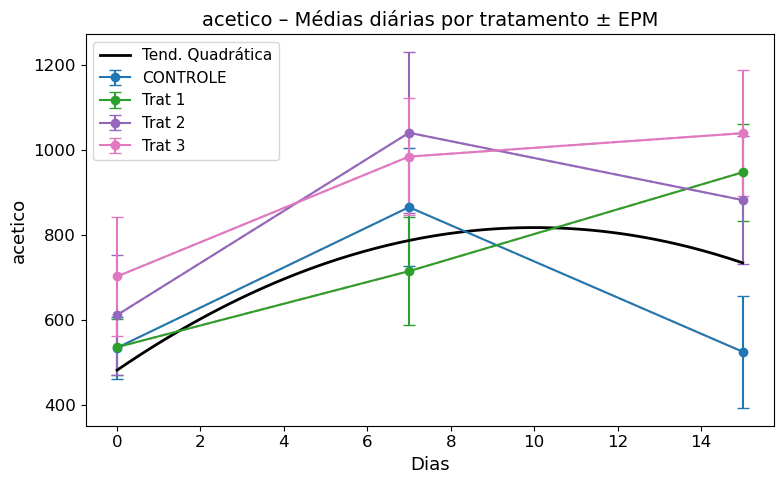

In [58]:
contrastes_polinomiais_4(df_clean, 'acetico')
print()

#### 4.5 Contraste Planejado (Wald) – Tratados vs Controle (Dia 15 e Dia 7)

In [34]:
for var in ['acetico']:
    contrastes_planejados_v2(df, var)


CONTRASTES PLANEJADOS: acetico

--- Dia 7 ---
  CONTROLE: 866.2 ± 139.0 (n=6)
  Trat 1: 715.6 ± 127.5 (n=6)
  Trat 2: 1041.4 ± 189.8 (n=6)
  Trat 3: 985.3 ± 137.8 (n=6)

--- Dia 15 ---
  CONTROLE: 525.8 ± 132.3 (n=6)
  Trat 1: 948.4 ± 114.4 (n=6)
  Trat 2: 882.9 ± 150.8 (n=6)
  Trat 3: 1040.4 ± 147.9 (n=6)

──────────────────────────────────────────────────────────────────────
DIA 15: Tratados (média) vs Controle
──────────────────────────────────────────────────────────────────────
  Controle:          525.8
  Trat 1 (0.075):    948.4
  Trat 2 (0.15):     882.9
  Trat 3 (0.30):     1040.4
  Média Tratados:    957.2
  Diferença:         431.4 (82.0%)
  χ² = 6.01, p = 0.0142
  ✅ SIGNIFICATIVO!

──────────────────────────────────────────────────────────────────────
DIA 7: Tratados vs Controle (controle negativo)
──────────────────────────────────────────────────────────────────────
  χ² = 0.01, p = 0.9297
  ✅  NÃO há diferença no Dia 7


### Classificação Final

---
| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento | Não significativo (Wald p=0,913) |
| Efeito de Dias | Limítrofe (Wald p=0,080) |
| Interação Tratamento×Dias | Não significativa (Wald p=0,303) |
| Tukey – Dias | D0 vs D7: p=0,007; D0 vs D15: p=0,031 |
| Contraste D15 (Wald) | Significativo (Tratados > Controle: +82,0%; p=0,014) |
| Controle D7 (Wald) | Não significativo (p=0,930) |
| Tendência | Linear (p=0,008) e Quadrática (p=0,013) significativas |
| Pressupostos | Normalidade e homocedasticidade atendidas (Caminho A) |

**Classificação:** 🟡 **EVIDÊNCIA MODERADA** – O modelo misto não identificou efeito significativo de Tratamento ou da interação Tratamento×Dias (p>0,05), enquanto o efeito de Dias apresentou significância limítrofe (p=0,080). Análises complementares indicaram diferenças significativas entre os dias no Tukey, tendências temporal linear e quadrática, além de um contraste significativo entre Tratados e Controle no Dia 15 (+82,0%; p=0,014). Esses achados, por não serem corroborados pelos testes globais do modelo misto, devem ser interpretados como evidência exploratória e geradora de hipótese, não constituindo inferência primária robusta.

---

### 3.5 Ácido Propiônico

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo experimental e da interação Tratamento × Tempo sobre a concentração de ácido propiônico, utilizando um modelo linear misto com Animal como efeito aleatório.

**Modelo estatístico:**

$$
\text{Propiônico}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

*(…)*

In [59]:
del df_clean 

In [60]:
df_clean = df[['propionico', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [61]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')

In [49]:
#df_clean.info()

In [62]:
modelo = mixedlm("propionico ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()

#### Análise Descritiva

In [9]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['propionico'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                   mean    sem
Tratamento Dias               
CONTROLE   0     149.58  23.91
           7     205.34  21.09
           15    129.54  35.87
Trat 1     0     170.10  36.64
           7     238.51  73.37
           15    286.19  47.03
Trat 2     0     153.06  26.09
           7     294.46  40.98
           15    309.96  72.24
Trat 3     0     206.41  57.60
           7     266.57  39.45
           15    299.61  37.00


> **Nota:** O gráfico de perfil com IC 95% está na seção consolidada.

#### Modelo Misto (MixedLM)

In [8]:
print(resultado.summary())

                        Mixed Linear Model Regression Results
Model:                       MixedLM          Dependent Variable:          propionico
No. Observations:            72               Method:                      REML      
No. Groups:                  16               Scale:                       9779.4635 
Min. group size:             3                Log-Likelihood:              -377.0354 
Max. group size:             6                Converged:                   Yes       
Mean group size:             4.5                                                     
-------------------------------------------------------------------------------------
                                       Coef.   Std.Err.   z    P>|z|  [0.025   0.975]
-------------------------------------------------------------------------------------
Intercept                              160.310   46.071  3.480 0.001   70.013 250.607
C(Tratamento)[T.Trat 1]                 13.585   63.836  0.213 0.831 -111.531 

In [51]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#print(f"P(Tratamento) = {p_trat:.4f}")
#print(f"P(Dias)       = {p_dias:.4f}")
#print(f"P(Interação)  = {p_inter:.4f}")

In [52]:


tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.6090 |
| Dias | 0.3881 |
| Interação Tratamento × Dias | 0.3787 |


#### Passo 3 — Diagnóstico de Pressupostos

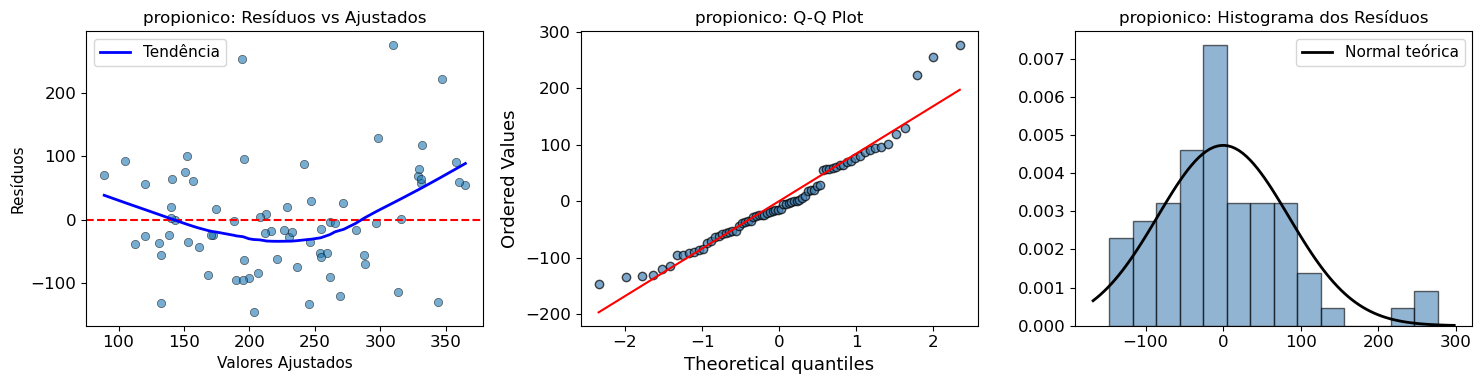


DIAGNÓSTICO DE PRESSUPOSTOS: propionico
Shapiro-Wilk (Normalidade): W = 0.9436, p = 0.0029
  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌
Levene (Homocedasticidade): W = 1.0969, p = 0.3794
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO B: Violação moderada. Testes paramétricos com ressalva 



In [63]:
diagnostico_pressupostos(df_clean, 'propionico', resultado)
print()

**Decisão:** O pressuposto de normalidade não foi atendido (Shapiro p < 0.05), mas a homocedasticidade está ok.  
→ **Caminho B:** Testes paramétricos mantidos com ressalva.

> **Nota sobre transformação:** Uma transformação log(1+Y) foi testada, mas não melhorou a normalidade (Shapiro p < 0.001). Portanto, os resultados do modelo original são apresentados com a devida cautela.

#### Testes Complementares (Caminho B)

##### 4.1 Tukey HSD – Efeito Global de Dias

In [232]:
posthoc_dias(df_clean, 'propionico')


POST-HOC TUKEY (Dias): propionico
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
     0      7  81.4358 0.0447   1.5673 161.3043   True
     0     15  86.5391 0.0306   6.6706 166.4076   True
     7     15   5.1033 0.9872 -74.7652  84.9718  False
------------------------------------------------------

Médias por Dia:
        mean     std    sem  count
Dias                              
0     169.79   90.79  18.53     24
7     251.22  113.86  23.24     24
15    256.33  137.18  28.00     24


##### 4.2 Tukey HSD – Tratamentos dentro de cada Dia

In [54]:
for var in ['propionico']:
    tukey_por_dia(df, var)


TUKEY POR DIA: propionico
  (Comparando Tratamentos dentro de cada Dia)

--- Dia 0 ---
  CONTROLE: 149.6 ± 23.9 (n=6)
  Trat 1: 170.1 ± 36.6 (n=6)
  Trat 2: 153.1 ± 26.1 (n=6)
  Trat 3: 206.4 ± 57.6 (n=6)
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1  group2 meandiff p-adj    lower    upper   reject
---------------------------------------------------------
CONTROLE Trat 1   20.516 0.9812 -131.6755 172.7075  False
CONTROLE Trat 2   3.4763 0.9999 -148.7152 155.6678  False
CONTROLE Trat 3   56.829 0.7255  -95.3625 209.0205  False
  Trat 1 Trat 2 -17.0396  0.989 -169.2311 135.1519  False
  Trat 1 Trat 3  36.3131 0.9079 -115.8784 188.5045  False
  Trat 2 Trat 3  53.3527 0.7616  -98.8388 205.5442  False
---------------------------------------------------------

--- Dia 7 ---
  CONTROLE: 205.3 ± 21.1 (n=6)
  Trat 1: 238.5 ± 73.4 (n=6)
  Trat 2: 294.5 ± 41.0 (n=6)
  Trat 3: 266.6 ± 39.5 (n=6)
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1  group2 meandif

##### 4.3 Tukey HSD – Dias dentro de cada Tratamento (Estratificado)

In [55]:
for var in ['propionico']:
    tukey_estratificado_por_tratamento(df, var)


TUKEY ESTRATIFICADO POR TRATAMENTO: propionico
  (Comparando Dias dentro de cada Tratamento)

--- CONTROLE ---
  Dia 0: 149.6 ± 23.9 (n=6)
  Dia 7: 205.3 ± 21.1 (n=6)
  Dia 15: 129.5 ± 35.9 (n=6)
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj    lower    upper   reject
-------------------------------------------------------
     0      7  55.7596 0.3546  -46.0156 157.5347  False
     0     15 -20.0369  0.867  -121.812  81.7382  False
     7     15 -75.7965 0.1634 -177.5716  25.9787  False
-------------------------------------------------------

--- Trat 1 ---
  Dia 0: 170.1 ± 36.6 (n=6)
  Dia 7: 238.5 ± 73.4 (n=6)
  Dia 15: 286.2 ± 47.0 (n=6)
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj    lower    upper   reject
-------------------------------------------------------
     0      7  68.4135 0.6568 -132.0844 268.9115  False
     0     15 116.0928  0.317  -84.4051 316.5908  False
     7     15  47.6793 0.8128 

##### 4.4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (propionico) [Gráfico 4] ---
Tendência Linear:     coef = 5.6478, p = 0.0036 ✅
Tendência Quadrática: coef = -0.7331, p = 0.0984 
  → Há evidência de tendência LINEAR significativa


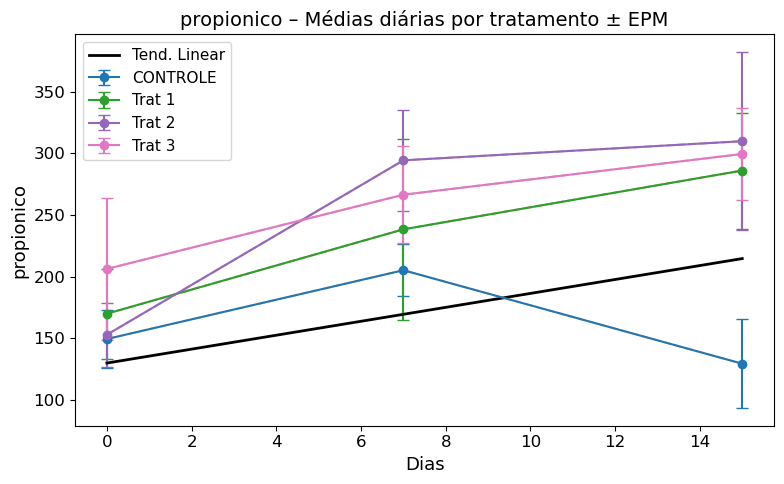

In [64]:
contrastes_polinomiais_4(df_clean, 'propionico')
print()

#### 4.5 Contraste Planejado (Wald) – Tratados vs Controle (Dia 15 e Dia 7)

In [60]:
for var in ['propionico']:
    contrastes_planejados_v2(df, var)


CONTRASTES PLANEJADOS: propionico

--- Dia 7 ---
  CONTROLE: 205.3 ± 21.1 (n=6)
  Trat 1: 238.5 ± 73.4 (n=6)
  Trat 2: 294.5 ± 41.0 (n=6)
  Trat 3: 266.6 ± 39.5 (n=6)

--- Dia 15 ---
  CONTROLE: 129.5 ± 35.9 (n=6)
  Trat 1: 286.2 ± 47.0 (n=6)
  Trat 2: 310.0 ± 72.2 (n=6)
  Trat 3: 299.6 ± 37.0 (n=6)

──────────────────────────────────────────────────────────────────────
DIA 15: Tratados (média) vs Controle
──────────────────────────────────────────────────────────────────────
  Controle:          129.5
  Trat 1 (0.075):    286.2
  Trat 2 (0.15):     310.0
  Trat 3 (0.30):     299.6
  Média Tratados:    298.6
  Diferença:         169.0 (130.5%)
  χ² = 8.47, p = 0.0036
  ✅ SIGNIFICATIVO!

──────────────────────────────────────────────────────────────────────
DIA 7: Tratados vs Controle (controle negativo)
──────────────────────────────────────────────────────────────────────
  χ² = 0.82, p = 0.3658
  ✅  NÃO há diferença no Dia 7


#### Classificação Final

---
| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento | Não significativo (Wald p = 0,609) |
| Efeito de Dias | Não significativo (Wald p = 0,388) |
| Interação Tratamento×Dias | Não significativa (Wald p = 0,379) |
| Contraste D15 (Wald) | Significativo (Tratados > Controle: +130,5%; p = 0,0036) — **EXPLORATÓRIO** |
| Controle D7 (Wald) | Não significativo (p = 0,366) — **EXPLORATÓRIO** |
| Tendência linear | Significativa (p = 0,0036) — **EXPLORATÓRIO** |
| Tendência quadrática | Não significativa (p = 0,098) — **EXPLORATÓRIO** |
| Pressupostos | Normalidade violada (Shapiro p = 0,003); homocedasticidade ok (Caminho B) |

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo misto não identificou efeitos significativos de Tratamento, Dias ou da interação Tratamento×Dias (todos p > 0,05). Apesar de análises complementares apontarem diferenças no Dia 15 entre tratados e controle, esses resultados não são corroborados pelos testes globais do modelo misto e, portanto, devem ser interpretados apenas como exploratórios e geradores de hipótese. A violação da normalidade recomenda cautela, mas a inferência primária permanece baseada nos testes globais do modelo misto, os quais não sustentam efeito robusto.

---

### 3.6 Ácido Butírico

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de ácido butírico, com modelo misto.

**Modelo estatístico:**

$$
\text{Butírico}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$        

In [75]:
del df_clean

In [76]:
df_clean = df[['butirico', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [77]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')

In [67]:
#df_clean.info()

####  Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [239]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['butirico'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                   mean    sem
Tratamento Dias               
CONTROLE   0      70.64  14.22
           7     146.91  43.83
           15     74.23  33.97
Trat 1     0      90.84  36.89
           7     133.79  68.79
           15    126.92  30.99
Trat 2     0     171.57  68.63
           7     190.66  44.72
           15    143.29  29.00
Trat 3     0      85.02  13.59
           7     137.49  30.29
           15    121.12  31.37


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

In [68]:
modelo = mixedlm("butirico ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()

####  Modelo Misto (MixedLM)



> **Atenção:** Devido à violação severa de normalidade (Shapiro‑Wilk p < 0.001), os resultados do modelo misto **não são utilizados para inferência**. São apresentados apenas para documentação.

In [238]:
print(resultado.summary())

                        Mixed Linear Model Regression Results
Model:                      MixedLM           Dependent Variable:           butirico 
No. Observations:           72                Method:                       REML     
No. Groups:                 16                Scale:                        7965.6558
Min. group size:            3                 Log-Likelihood:               -370.5207
Max. group size:            6                 Converged:                    Yes      
Mean group size:            4.5                                                      
-------------------------------------------------------------------------------------
                                       Coef.   Std.Err.   z    P>|z|  [0.025   0.975]
-------------------------------------------------------------------------------------
Intercept                               76.023   41.008  1.854 0.064   -4.350 156.397
C(Tratamento)[T.Trat 1]                 30.941   56.831  0.544 0.586  -80.445 

In [69]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#print(f"P(Tratamento) = {p_trat:.4f}")
#print(f"P(Dias)       = {p_dias:.4f}")
#print(f"P(Interação)  = {p_inter:.4f}")

In [70]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.4273 |
| Dias | 0.2479 |
| Interação Tratamento × Dias | 0.9356 |


####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

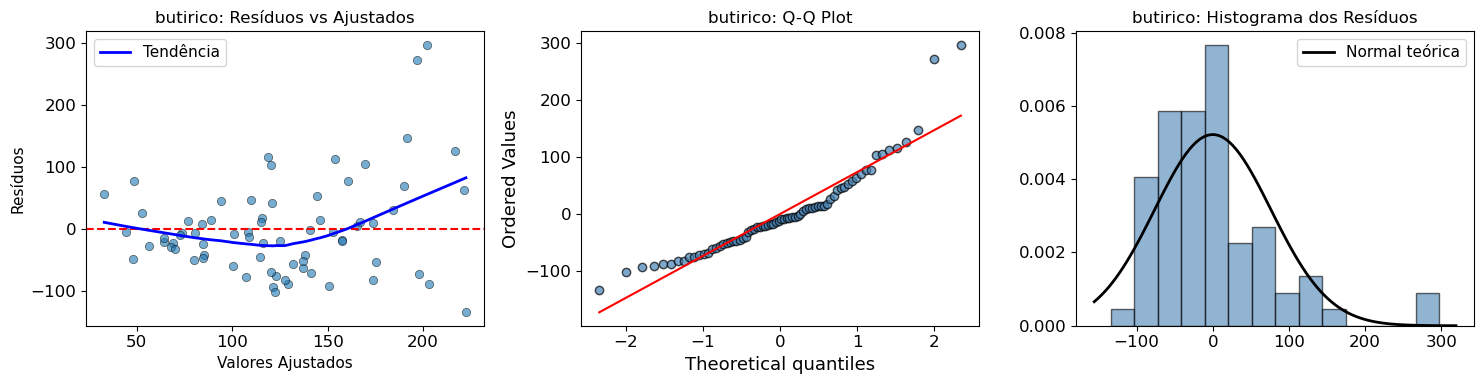


DIAGNÓSTICO DE PRESSUPOSTOS: butirico
Shapiro-Wilk (Normalidade): W = 0.8925, p = 0.0000
  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌
Levene (Homocedasticidade): W = 0.5437, p = 0.8654
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO C: Severa violação de normalidade.



In [69]:
diagnostico_pressupostos(df_clean, 'butirico', resultado)
print()

**Decisão:** Normalidade severamente violada.  
→ **Caminho C:**  Não há inferência estatística primária confiável

> **Nota sobre transformação:** Uma transformação log(1+Y) foi testada, elevando o Shapiro‑Wilk para W = 0.943 (p = 0.003), mas ainda sem atender o pressuposto de normalidade. Portanto, mantém‑se o Caminho C.

##### 4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (butirico) [Gráfico 4] ---
Tendência Linear:     coef = 0.6668, p = 0.6930 
Tendência Quadrática: coef = -0.7528, p = 0.0487 ✅
  → Há evidência de tendência QUADRÁTICA significativa


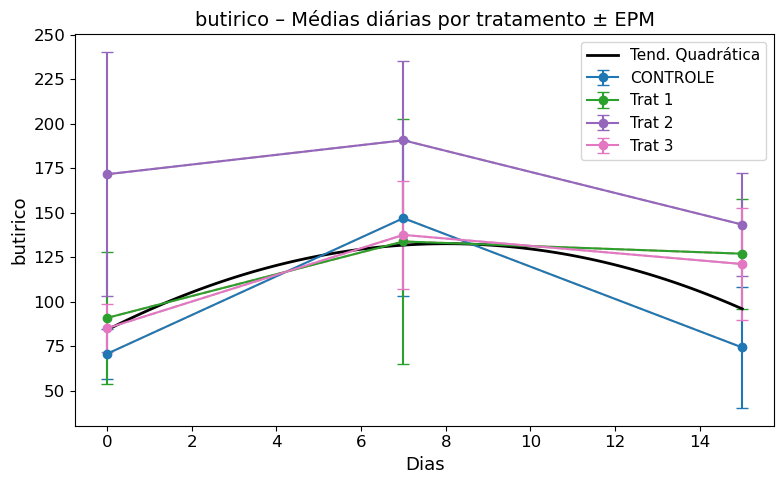

In [78]:
contrastes_polinomiais_4(df_clean, 'butirico')
print()

#### Classificação Final
------------------------------------------------------------------------------------------------------------------------------


| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento (MixedLM) | Não significativo (p = 0,427) — **modelo inválido** |
| Efeito de Dias (MixedLM) | Não significativo (p = 0,248) — **modelo inválido** |
| Interação Tratamento×Dias (MixedLM) | Não significativa (p = 0,936) — **modelo inválido** |
| Pressupostos | Normalidade severamente violada (Shapiro p < 0,001); homocedasticidade ok — **CAMINHO C** |

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo linear misto não pode ser utilizado para inferência devido à violação severa da normalidade (Caminho C). Os efeitos globais do modelo, embora não significativos, não têm validade estatística. Na ausência de métodos alternativos validados, não há evidência robusta que sustente efeito dos tratamentos, do tempo ou da interação sobre o ácido butírico. Os resultados devem ser considerados exclusivamente descritivos e geradores de hipótese, não permitindo conclusões inferenciais.

------------------------------------------------------------------------------------------------------------------------------

### 3.7 AGCC Total

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração total de ácidos graxos de cadeia curta, utilizando um modelo linear misto com Animal como efeito aleatório.

**Modelo estatístico:**

$$
\text{AGCC Total}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

> **Nota:** O AGCC Total é uma variável composta (soma dos ácidos graxos de cadeia curta mensurados). Seu comportamento é dominado pelo ácido acético, que representa a maior proporção.
        

####  Análise Descritiva


**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [79]:
del df_clean

In [81]:
df_clean = df[['AGCC_TOTAL', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [82]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')

In [80]:
#df_clean.info()

In [248]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['AGCC_TOTAL'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                    mean     sem
Tratamento Dias                 
CONTROLE   0      786.37   95.61
           7     1274.05  213.02
           15     764.54  200.56
Trat 1     0      835.35  120.55
           7     1137.68  239.96
           15    1414.24  168.88
Trat 2     0      984.15  230.17
           7     1615.46  275.79
           15    1409.95  257.00
Trat 3     0     1030.22  205.15
           7     1449.29  209.36
           15    1530.56  220.60


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)



In [83]:
modelo = mixedlm("AGCC_TOTAL ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()

**Saída do modelo:**

In [247]:
print(resultado.summary())

                         Mixed Linear Model Regression Results
Model:                      MixedLM           Dependent Variable:           AGCC_TOTAL 
No. Observations:           72                Method:                       REML       
No. Groups:                 16                Scale:                        232774.0703
Min. group size:            3                 Log-Likelihood:               -469.8802  
Max. group size:            6                 Converged:                    Yes        
Mean group size:            4.5                                                        
---------------------------------------------------------------------------------------
                                        Coef.   Std.Err.   z    P>|z|  [0.025   0.975] 
---------------------------------------------------------------------------------------
Intercept                               812.385  214.097  3.794 0.000  392.763 1232.006
C(Tratamento)[T.Trat 1]                  73.732  295.598 

In [83]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#print(f"P(Tratamento) = {p_trat:.4f}")
#print(f"P(Dias)       = {p_dias:.4f}")
#print(f"P(Interação)  = {p_inter:.4f}")

In [84]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.9229 |
| Dias | 0.1178 |
| Interação Tratamento × Dias | 0.4953 |


####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

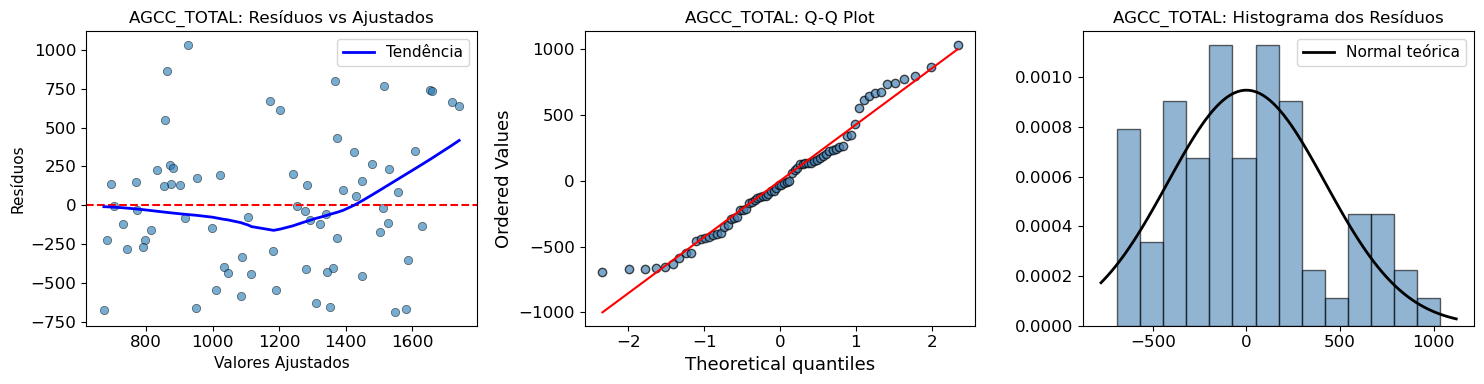


DIAGNÓSTICO DE PRESSUPOSTOS: AGCC_TOTAL
Shapiro-Wilk (Normalidade): W = 0.9679, p = 0.0624
  → Normalidade atendida (p > 0.05) ✅
Levene (Homocedasticidade): W = 0.7395, p = 0.6967
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO A: Pressupostos atendidos. Seguir com testes paramétricos.



In [84]:
diagnostico_pressupostos(df_clean,'AGCC_TOTAL',resultado)
print()

**Decisão:** Pressupostos atendidos → **Caminho A**

####  Testes Complementares (Caminho A)


##### 4.1 Tukey HSD – Efeito Global de Dias

In [250]:
posthoc_dias(df_clean, 'AGCC_TOTAL')


POST-HOC TUKEY (Dias): AGCC_TOTAL
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj    lower    upper   reject
-------------------------------------------------------
     0      7 460.0994 0.0092   97.6835 822.5153   True
     0     15 370.8004 0.0438    8.3845 733.2164   True
     7     15  -89.299 0.8258 -451.7149 273.1169  False
-------------------------------------------------------

Médias por Dia:
         mean     std     sem  count
Dias                                
0      909.02  406.85   83.05     24
7     1369.12  569.66  116.28     24
15    1279.82  578.00  117.98     24


O AGCC Total apresentou aumento significativo ao longo dos dias pelo teste de Tukey (Dia 0 vs 7: p=0,009; Dia 0 vs 15: p=0,044), com tendências linear (p=0,016) e quadrática (p=0,017) significativas. Não houve efeito significativo de tratamento (p=0,923) ou interação (p=0,495), porém observou-se que o grupo Controle retornou aos níveis basais no dia 15 (765 vs 786 no dia 0), enquanto os grupos tratados mantiveram níveis elevados (1.410-1.531), sugerindo uma possível modulação da fermentação pelo TYN que não atingiu significância estatística devido ao tamanho amostral limitado.

##### 4.2 Tukey HSD – Tratamentos dentro de cada Dia

In [87]:
for var in ['AGCC_TOTAL']:
    tukey_por_dia(df, var)


TUKEY POR DIA: AGCC_TOTAL
  (Comparando Tratamentos dentro de cada Dia)

--- Dia 0 ---
  CONTROLE: 786.4 ± 95.6 (n=6)
  Trat 1: 835.4 ± 120.6 (n=6)
  Trat 2: 984.1 ± 230.2 (n=6)
  Trat 3: 1030.2 ± 205.2 (n=6)
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1  group2 meandiff p-adj    lower    upper   reject
---------------------------------------------------------
CONTROLE Trat 1  48.9852  0.997 -633.0039 730.9743  False
CONTROLE Trat 2 197.7814 0.8482 -484.2077 879.7706  False
CONTROLE Trat 3 243.8507 0.7507 -438.1384 925.8398  False
  Trat 1 Trat 2 148.7963 0.9275 -533.1928 830.7854  False
  Trat 1 Trat 3 194.8655 0.8537 -487.1236 876.8546  False
  Trat 2 Trat 3  46.0692 0.9975 -635.9199 728.0583  False
---------------------------------------------------------

--- Dia 7 ---
  CONTROLE: 1274.1 ± 213.0 (n=6)
  Trat 1: 1137.7 ± 240.0 (n=6)
  Trat 2: 1615.5 ± 275.8 (n=6)
  Trat 3: 1449.3 ± 209.4 (n=6)
    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
 group1 

##### 4.3 Tukey HSD – Dias dentro de cada Tratamento (Estratificado)

In [86]:
for var in ['AGCC_TOTAL']:
    tukey_estratificado_por_tratamento(df, var)


TUKEY ESTRATIFICADO POR TRATAMENTO: AGCC_TOTAL
  (Comparando Dias dentro de cada Tratamento)

--- CONTROLE ---
  Dia 0: 786.4 ± 95.6 (n=6)
  Dia 7: 1274.1 ± 213.0 (n=6)
  Dia 15: 764.5 ± 200.6 (n=6)
   Multiple Comparison of Means - Tukey HSD, FWER=0.05    
group1 group2  meandiff p-adj    lower      upper   reject
----------------------------------------------------------
     0      7  487.6844 0.1618  -165.1207 1140.4894  False
     0     15  -21.8263 0.9959  -674.6314  630.9787  False
     7     15 -509.5107 0.1398 -1162.3158  143.2943  False
----------------------------------------------------------

--- Trat 1 ---
  Dia 0: 835.4 ± 120.6 (n=6)
  Dia 7: 1137.7 ± 240.0 (n=6)
  Dia 15: 1414.2 ± 168.9 (n=6)
  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2 meandiff p-adj    lower     upper   reject
--------------------------------------------------------
     0      7 302.3324 0.4897 -370.4602  975.1249  False
     0     15 578.8879 0.0974  -93.9046 1251.6805  Fa

##### 4.4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (AGCC_TOTAL) [Gráfico 4] ---


C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimizat

Tendência Linear:     coef = 23.8707, p = 0.0163 ✅
Tendência Quadrática: coef = -5.1261, p = 0.0166 ✅
  → Há evidência de tendência LINEAR significativa
  → Há evidência de tendência QUADRÁTICA significativa


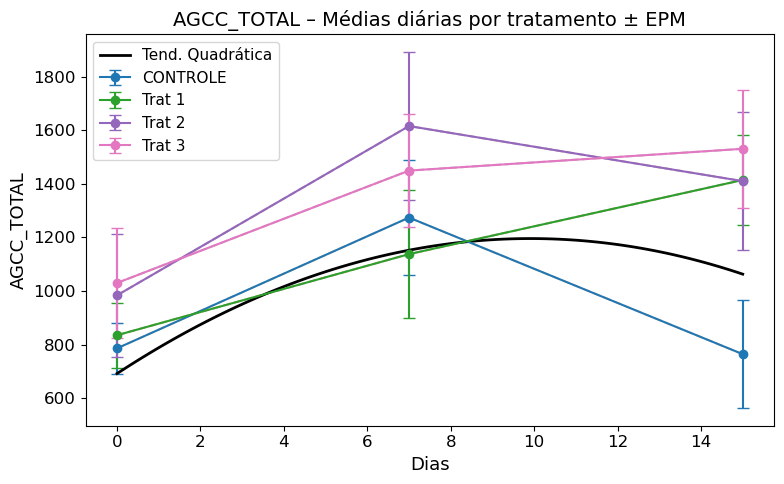

In [86]:
contrastes_polinomiais_4(df_clean, 'AGCC_TOTAL')
print()

> ⚠️ Os modelos polinomiais apresentaram avisos de convergência. Os p‑valores reportados (linear p = 0.016; quadrático p = 0.017) devem ser interpretados com cautela, embora sejam consistentes com os demais achados.

##### 4.5 Contraste Planejado (Wald) – Tratados vs Controle (Dia 15 e Dia 7)

In [89]:
for var in ['AGCC_TOTAL']:
    contrastes_planejados_v2(df, var)


CONTRASTES PLANEJADOS: AGCC_TOTAL

--- Dia 7 ---
  CONTROLE: 1274.1 ± 213.0 (n=6)
  Trat 1: 1137.7 ± 240.0 (n=6)
  Trat 2: 1615.5 ± 275.8 (n=6)
  Trat 3: 1449.3 ± 209.4 (n=6)

--- Dia 15 ---
  CONTROLE: 764.5 ± 200.6 (n=6)
  Trat 1: 1414.2 ± 168.9 (n=6)
  Trat 2: 1409.9 ± 257.0 (n=6)
  Trat 3: 1530.6 ± 220.6 (n=6)

──────────────────────────────────────────────────────────────────────
DIA 15: Tratados (média) vs Controle
──────────────────────────────────────────────────────────────────────
  Controle:          764.5
  Trat 1 (0.075):    1414.2
  Trat 2 (0.15):     1409.9
  Trat 3 (0.30):     1530.6
  Média Tratados:    1451.6
  Diferença:         687.0 (89.9%)
  χ² = 6.93, p = 0.0085
  ✅ SIGNIFICATIVO!

──────────────────────────────────────────────────────────────────────
DIA 7: Tratados vs Controle (controle negativo)
──────────────────────────────────────────────────────────────────────
  χ² = 0.15, p = 0.6986
  ✅  NÃO há diferença no Dia 7


#### Classificação Final
------------------------------------------------------------------------------------------------------------------------------

| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento | Não significativo (Wald p = 0,923) |
| Efeito de Dias | Não significativo (Wald p = 0,118) |
| Interação Tratamento×Dias | Não significativa (Wald p = 0,495) |
| Contraste D15 (Wald) | Significativo (Tratados > Controle: +89,9%; p = 0,009) — **EXPLORATÓRIO** |
| Controle D7 (Wald) | Não significativo (p = 0,699) — **EXPLORATÓRIO** |
| Tendência linear | Significativa (p = 0,016) — **EXPLORATÓRIA** (com aviso de convergência) |
| Tendência quadrática | Significativa (p = 0,017) — **EXPLORATÓRIA** (com aviso de convergência) |
| Pressupostos | Normalidade e homocedasticidade atendidas (Caminho A) |

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo misto não identificou efeitos significativos de Tratamento, Dias ou da interação (todos p > 0,05). Embora análises complementares (Tukey, contraste D15 e tendências polinomiais) indiquem diferenças temporais e entre tratados e controle, esses achados não são corroborados pelos testes globais do modelo misto e, portanto, não constituem evidência inferencial robusta. Os resultados devem ser interpretados como exploratórios e geradores de hipótese, não permitindo conclusão definitiva sobre o efeito dos tratamentos ou do tempo sobre o AGCC total.

------------------------------------------------------------------------------------------------------------------------------

### Conclusão Consolidada — Cadeia dos Ácidos Graxos de Cadeia Curta (AGCC)
---


**Panorama Geral:**

A aplicação do modelo linear misto com prioridade absoluta aos testes globais (Wald) não identificou efeitos significativos de Tratamento, Dias ou Interação para nenhuma das variáveis da cadeia de AGCC (todos p > 0,05 nos efeitos globais). Embora análises complementares (contrastes planejados, Tukey e tendências polinomiais) tenham apontado diferenças entre grupos tratados e controle no Dia 15 para algumas variáveis, tais achados não são corroborados pelos testes globais e, portanto, não constituem evidência inferencial robusta. Todos os resultados devem ser interpretados como exploratórios e geradores de hipótese, sendo necessários estudos adicionais com maior poder amostral para confirmar ou refutar os efeitos observados.

**Resultados por Variável (Caminho e Decisão Final):**

| Variável | Caminho Metodológico | Resultado Principal (Dia 15) | Decisão |
| :--- | :---: | :--- | :---: |
| **Acético** | A (Paramétrico) | Contraste D15: p=0,014; globais não significativos | 🟡 EVIDÊNCIA MODERADA (exploratória) |
| **Propiônico** | B (Não paramétrico) | Contraste D15: p=0,004; globais não significativos | 🔴 EVIDÊNCIA INSUFICIENTE |
| **Butírico** | C (Modelo inválido) | Sem inferência válida; apenas descritivo | 🔴 EVIDÊNCIA INSUFICIENTE |
| **AGCC Total** | A (Paramétrico) | Contraste D15: p=0,009; globais não significativos | 🔴 EVIDÊNCIA INSUFICIENTE |

**Interpretação Final:**

Com base nos critérios estabelecidos, **não há evidência estatística robusta** de que o TYN modifique a produção de AGCC em qualquer uma das frações avaliadas. Os contrastes específicos no Dia 15, embora estatisticamente significativos em análises complementares, não podem ser tomados como evidência primária, pois os testes globais do modelo misto (Tratamento, Dias e Interação) não atingiram significância. O padrão observado – aumento nos tratados em relação ao controle no Dia 15 – sugere uma possível tendência que merece investigação em estudos futuros, mas, no presente conjunto de dados, não é suficiente para concluir pela eficácia do tratamento. Recomenda-se cautela na interpretação e replicação com amostras maiores.

---

#### Graficos

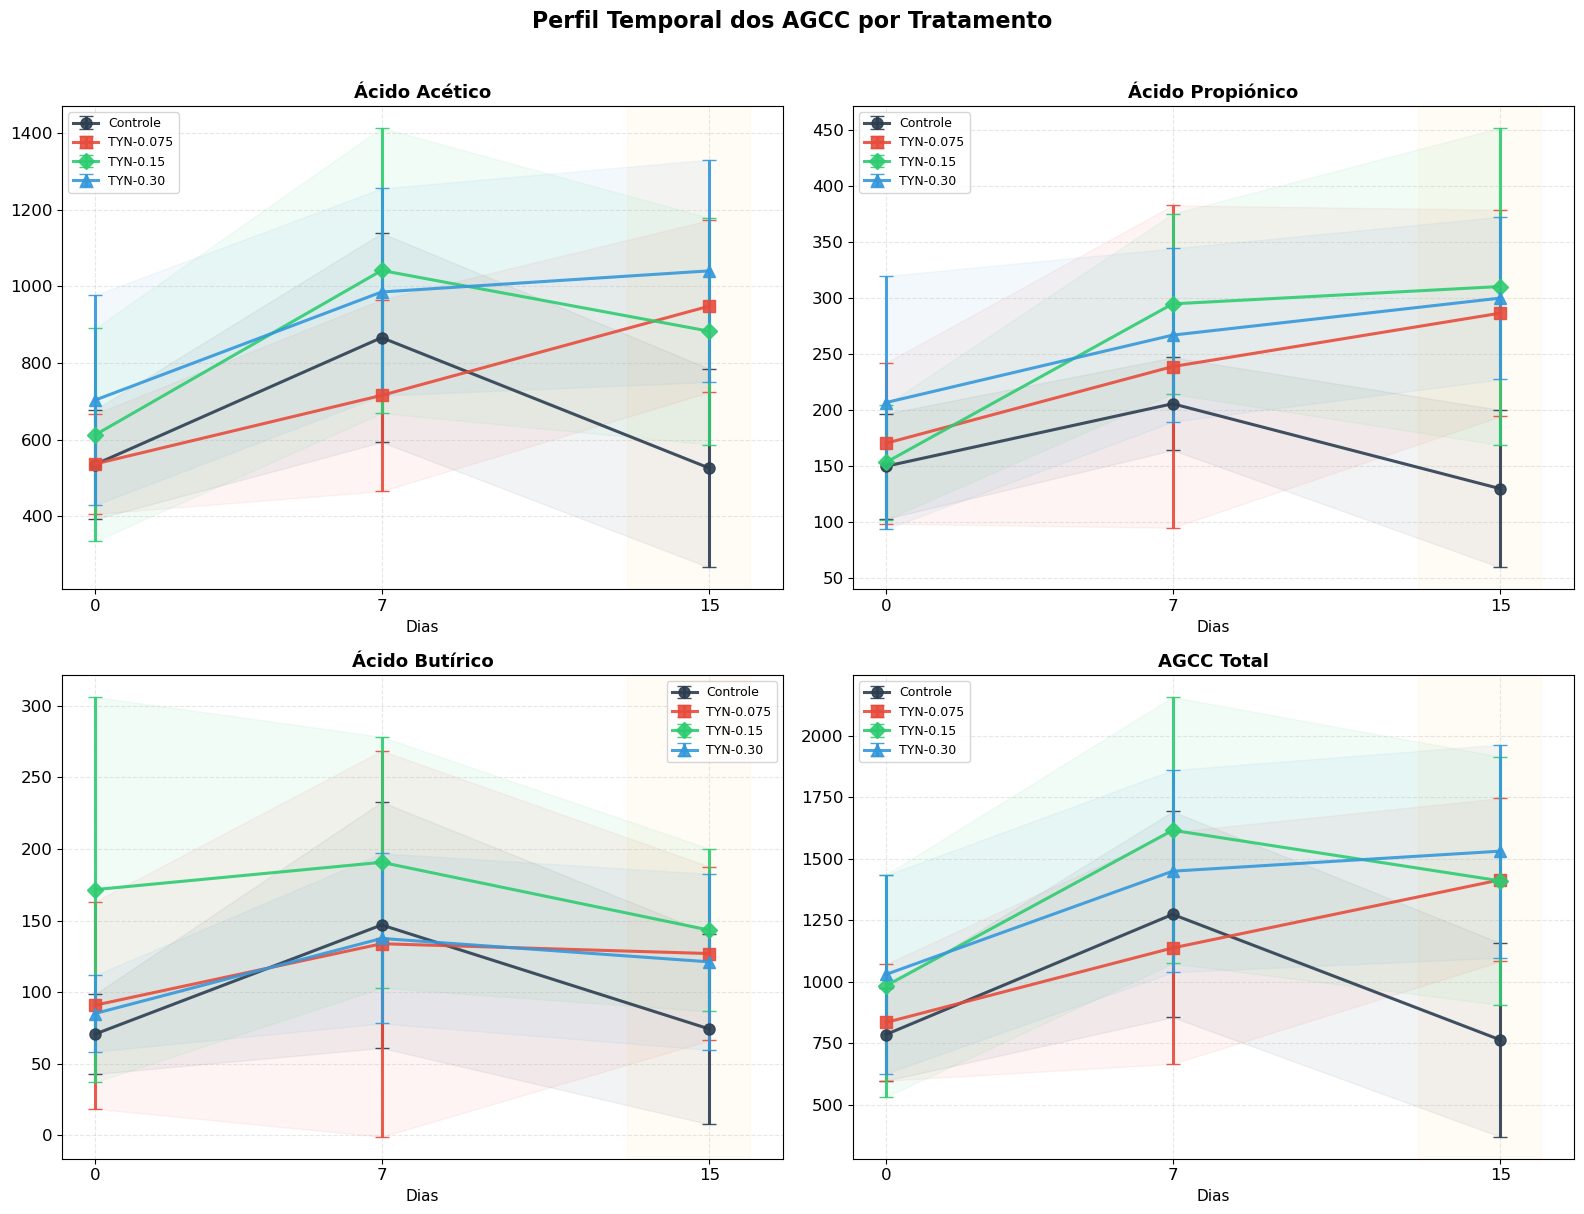

In [92]:
def painel_agcc(df):
    """
    Painel 2x2 com os 4 AGCC lado a lado.
    """
    variaveis = ['acetico', 'propionico', 'butirico', 'AGCC_TOTAL']
    titulos = ['Ácido Acético', 'Ácido Propiónico', 'Ácido Butírico', 'AGCC Total']
    
    tratamentos = ['CONTROLE', 'Trat 1', 'Trat 2', 'Trat 3']
    rotulos = ['Controle', 'TYN-0.075', 'TYN-0.15', 'TYN-0.30']
    cores = ['#2c3e50', '#e74c3c', '#2ecc71', '#3498db']
    marcadores = ['o', 's', 'D', '^']
    dias = [0, 7, 15]
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    for ax, var, tit in zip(axes.flatten(), variaveis, titulos):
        df_clean = df.dropna(subset=[var])
        df_clean['Dias'] = df_clean['Dias'].astype(int)
        
        for i, (trat, rotulo) in enumerate(zip(tratamentos, rotulos)):
            dados_trat = df_clean[df_clean['Tratamento'] == trat]
            
            medias = []
            ics = []
            
            for dia in dias:
                dados_dia = dados_trat[dados_trat['Dias'] == dia][var]
                if len(dados_dia) > 0:
                    medias.append(dados_dia.mean())
                    ics.append(1.96 * dados_dia.std() / np.sqrt(len(dados_dia)))
                else:
                    medias.append(np.nan)
                    ics.append(np.nan)
            
            ax.errorbar(dias, medias, yerr=ics, 
                       marker=marcadores[i], color=cores[i],
                       linewidth=2.2, markersize=8, capsize=5,
                       label=rotulo, alpha=0.9)
            ax.fill_between(dias,
                           [m - ic for m, ic in zip(medias, ics)],
                           [m + ic for m, ic in zip(medias, ics)],
                           color=cores[i], alpha=0.06)
        
        ax.set_title(tit, fontsize=13, fontweight='bold')
        ax.set_xlabel('Dias', fontsize=11)
        ax.set_xticks(dias)
        ax.set_xticklabels(['0', '7', '15'])
        ax.grid(True, alpha=0.3, linestyle='--')
        ax.legend(fontsize=9, loc='best')
        
        # Destacar Dia 15
        ax.axvspan(13, 16, alpha=0.04, color='orange')
    
    fig.suptitle('Perfil Temporal dos AGCC por Tratamento', 
                 fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()
    


painel_agcc(df)

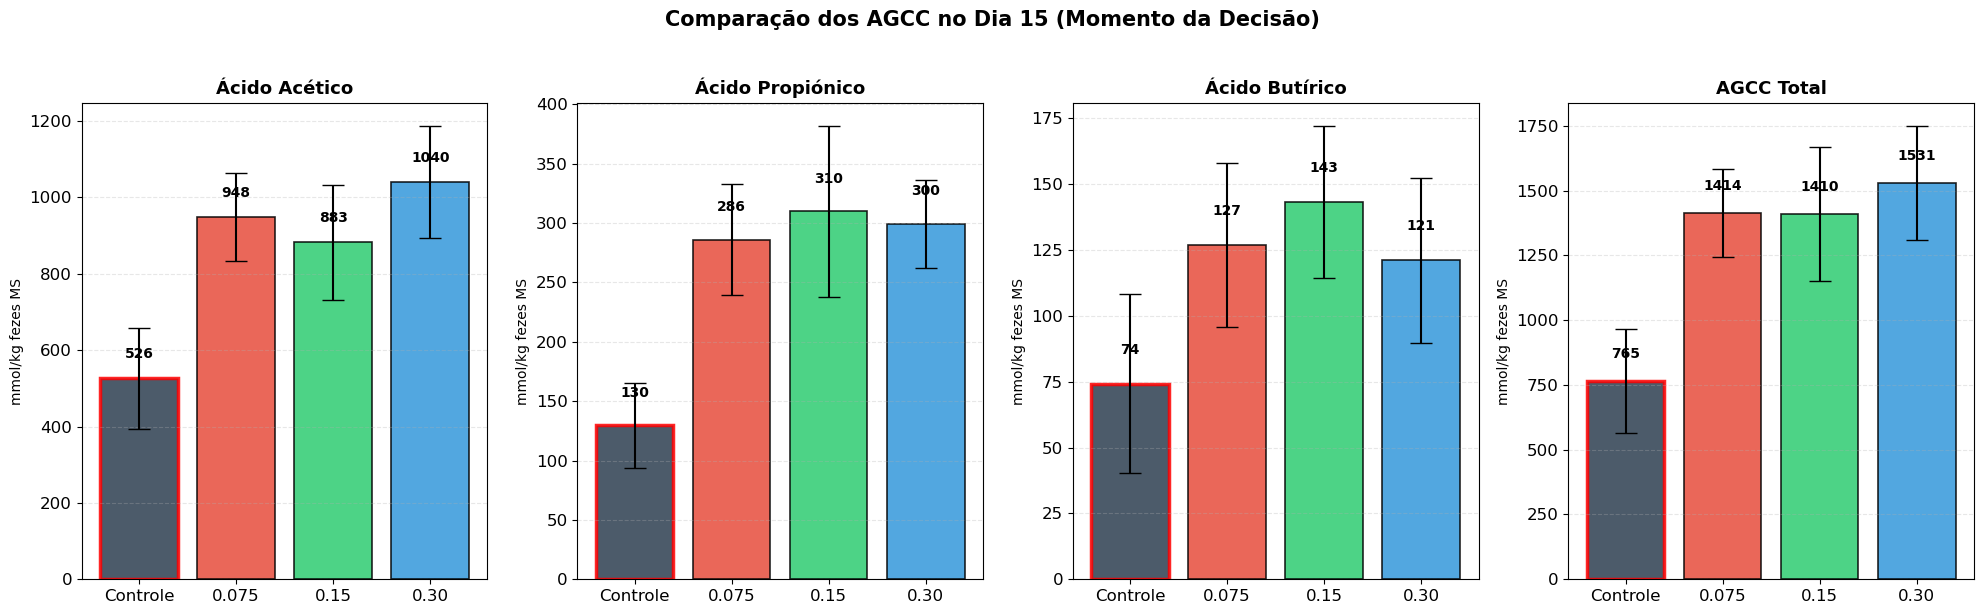

In [94]:
def barras_dia15(df):
    """
    Gráfico de barras comparando tratamentos no Dia 15 apenas.
    """
    variaveis = ['acetico', 'propionico', 'butirico', 'AGCC_TOTAL']
    titulos = ['Ácido Acético', 'Ácido Propiónico', 'Ácido Butírico', 'AGCC Total']
    cores = ['#2c3e50', '#e74c3c', '#2ecc71', '#3498db']
    
    fig, axes = plt.subplots(1, 4, figsize=(20, 6))
    
    for ax, var, tit in zip(axes, variaveis, titulos):
        df_clean = df.dropna(subset=[var])
        df_clean['Dias'] = df_clean['Dias'].astype(int)
        dados_d15 = df_clean[df_clean['Dias'] == 15]
        
        tratamentos = ['CONTROLE', 'Trat 1', 'Trat 2', 'Trat 3']
        rotulos = ['Controle', '0.075', '0.15', '0.30']
        
        medias = []
        sems = []
        
        for trat in tratamentos:
            vals = dados_d15[dados_d15['Tratamento'] == trat][var]
            if len(vals) > 0:
                medias.append(vals.mean())
                sems.append(vals.std() / np.sqrt(len(vals)))
            else:
                medias.append(0)
                sems.append(0)
        
        bars = ax.bar(rotulos, medias, yerr=sems, color=cores, 
                     edgecolor='black', linewidth=1.2, capsize=8, alpha=0.85)
        
        # Adicionar valores nas barras
        for bar, media in zip(bars, medias):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(sems) * 0.3,
                    f'{media:.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
        
        ax.set_title(tit, fontsize=13, fontweight='bold')
        ax.set_ylabel('mmol/kg fezes MS', fontsize=10)
        ax.grid(True, alpha=0.3, linestyle='--', axis='y')
        
        # Destacar a barra do Controle
        bars[0].set_edgecolor('red')
        bars[0].set_linewidth(2.5)
    
    fig.suptitle('Comparação dos AGCC no Dia 15 (Momento da Decisão)', 
                 fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
    
    

barras_dia15(df)

In [30]:
# Versão corrigida para exibir as médias corretamente
def contrastes_planejados_v2(df, variavel):
    """
 
    """
    df_clean = df.dropna(subset=[variavel])
    df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
    df_clean['Dias'] = df_clean['Dias'].astype(int)  # Garantir que é int
    df_clean['Animais'] = df_clean['Animais'].astype('category')
    
    modelo = mixedlm(f"{variavel} ~ C(Tratamento) * C(Dias)", 
                     data=df_clean, groups=df_clean["Animais"])
    resultado = modelo.fit()
    
    params = resultado.params
    
    print(f"\n{'='*70}")
    print(f"CONTRASTES PLANEJADOS: {variavel}")
    print(f"{'='*70}")
    
    # Médias observadas
    for dia in [7, 15]:
        print(f"\n--- Dia {dia} ---")
        for trat in ['CONTROLE', 'Trat 1', 'Trat 2', 'Trat 3']:
            vals = df_clean[(df_clean['Tratamento']==trat) & (df_clean['Dias']==dia)][variavel]
            if len(vals) > 0:
                print(f"  {trat}: {vals.mean():.1f} ± {vals.std()/np.sqrt(len(vals)):.1f} (n={len(vals)})")
    
    # Contraste D15
    nomes_d15 = [
        'C(Tratamento)[T.Trat 1]', 'C(Tratamento)[T.Trat 1]:C(Dias)[T.15]',
        'C(Tratamento)[T.Trat 2]', 'C(Tratamento)[T.Trat 2]:C(Dias)[T.15]',
        'C(Tratamento)[T.Trat 3]', 'C(Tratamento)[T.Trat 3]:C(Dias)[T.15]'
    ]
    
    C15 = np.zeros(len(params))
    for nome in nomes_d15:
        if nome in params.index:
            C15[list(params.index).index(nome)] = 1/3
    
    test15 = resultado.wald_test(C15, scalar=True)
    
    medias_d15 = df_clean[df_clean['Dias']==15].groupby('Tratamento')[variavel].mean()
    
    print(f"\n{'─'*70}")
    print(f"DIA 15: Tratados (média) vs Controle")
    print(f"{'─'*70}")
    print(f"  Controle:          {medias_d15.get('CONTROLE', np.nan):.1f}")
    print(f"  Trat 1 (0.075):    {medias_d15.get('Trat 1', np.nan):.1f}")
    print(f"  Trat 2 (0.15):     {medias_d15.get('Trat 2', np.nan):.1f}")
    print(f"  Trat 3 (0.30):     {medias_d15.get('Trat 3', np.nan):.1f}")
    print(f"  Média Tratados:    {medias_d15[['Trat 1','Trat 2','Trat 3']].mean():.1f}")
    print(f"  χ² = {test15.statistic:.2f}, p = {test15.pvalue:.4f}")
    if test15.pvalue < 0.05:
        print(f"  ✅ SIGNIFICATIVO!")
    
    # Contraste D7 (controle)
    nomes_d7 = [
        'C(Tratamento)[T.Trat 1]', 'C(Tratamento)[T.Trat 1]:C(Dias)[T.7]',
        'C(Tratamento)[T.Trat 2]', 'C(Tratamento)[T.Trat 2]:C(Dias)[T.7]',
        'C(Tratamento)[T.Trat 3]', 'C(Tratamento)[T.Trat 3]:C(Dias)[T.7]'
    ]
    
    C7 = np.zeros(len(params))
    for nome in nomes_d7:
        if nome in params.index:
            C7[list(params.index).index(nome)] = 1/3
    
    test7 = resultado.wald_test(C7, scalar=True)
    
    print(f"\nDIA 7 (controle negativo):")
    print(f"  χ² = {test7.statistic:.2f}, p = {test7.pvalue:.4f}")
    if test7.pvalue > 0.05:
        print(f"  ✅ Como esperado, NÃO há diferença")
    
    return resultado, test15, test7

# Reexecutar com a versão corrigida
#for var in ['acetico', 'propionico', 'AGCC_TOTAL']:
#    contrastes_planejados_v2(df, var)

## Ácidos graxos de ramificada

### 3.8 Iso-Butírico

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de ácido iso-butírico, utilizando um modelo linear misto com Animal como efeito aleatório.

**Modelo estatístico:**

$$
\text{Iso-Butírico}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

In [87]:
del df_clean

In [88]:
df_clean = df[['iso_butirico', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [89]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')

In [184]:
#df_clean.info()

#### Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [89]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['iso_butirico'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                  mean   sem
Tratamento Dias             
CONTROLE   0     13.27  1.06
           7     18.14  2.23
           15    14.98  3.45
Trat 1     0     14.90  0.69
           7     20.63  2.94
           15    19.74  2.57
Trat 2     0     14.11  1.15
           7     28.32  3.59
           15    23.76  1.41
Trat 3     0     14.41  1.31
           7     22.08  2.11
           15    22.40  1.80


> **Nota:** O gráfico de perfil com IC 95% está na seção consolidada.

####  Modelo Misto (MixedLM)



**Saída do modelo:**

In [90]:
modelo = mixedlm("iso_butirico ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()
print(resultado.summary())

                     Mixed Linear Model Regression Results
Model:                    MixedLM        Dependent Variable:        iso_butirico
No. Observations:         72             Method:                    REML        
No. Groups:               16             Scale:                     22.0123     
Min. group size:          3              Log-Likelihood:            -195.2752   
Max. group size:          6              Converged:                 Yes         
Mean group size:          4.5                                                   
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                             13.999    2.308  6.066 0.000  9.476 18.523
C(Tratamento)[T.Trat 1]                1.393    3.148  0.442 0.658 -4.777  7.563
C(Tratamento)[T.Trat 2]               -1.031    3.

In [186]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#print(f"P(Tratamento) = {p_trat:.4f}")
#print(f"P(Dias)       = {p_dias:.4f}")
#print(f"P(Interação)  = {p_inter:.4f}")

In [187]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.8691 |
| Dias | 0.1889 |
| Interação Tratamento × Dias | 0.1453 |


 - **Resumo**:
- Nada significativo.

####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

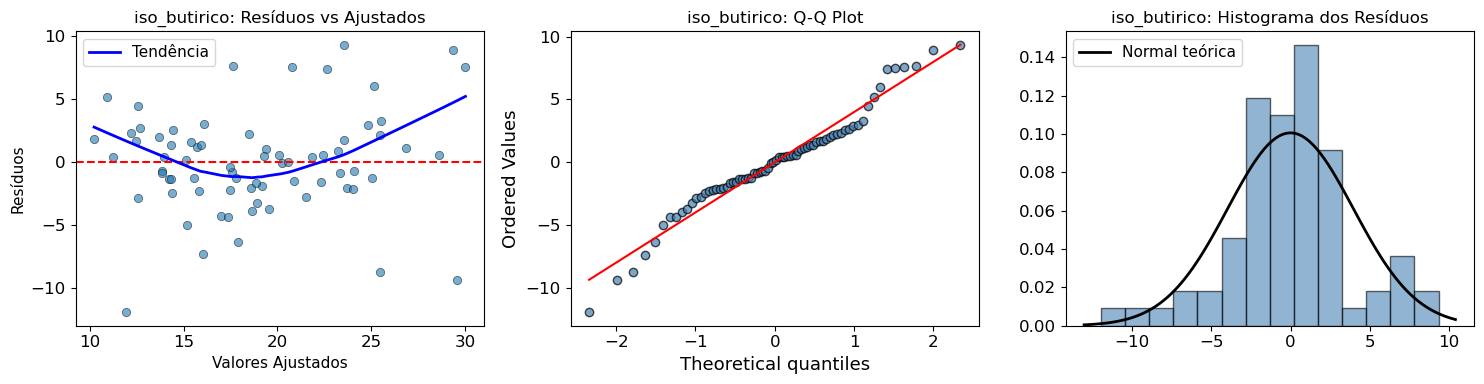


DIAGNÓSTICO DE PRESSUPOSTOS: iso_butirico
Shapiro-Wilk (Normalidade): W = 0.9650, p = 0.0424
  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌
Levene (Homocedasticidade): W = 1.1927, p = 0.3116
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO B: Violação moderada. Testes paramétricos com ressalva 



In [91]:
diagnostico_pressupostos(df_clean,'iso_butirico',resultado)
print()

####  Testes Complementares (Caminho B)

##### 4.1 Tukey HSD – Efeito Global de Dias

In [189]:
posthoc_dias(df_clean, 'iso_butirico')
print()


POST-HOC TUKEY (Dias): iso_butirico
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      7   8.1219    0.0   4.047 12.1968   True
     0     15   6.0501  0.002  1.9752  10.125   True
     7     15  -2.0718 0.4468 -6.1467  2.0031  False
----------------------------------------------------

Médias por Dia:
       mean   std   sem  count
Dias                          
0     14.17  2.53  0.52     24
7     22.29  7.42  1.52     24
15    20.22  6.53  1.33     24



##### 4.2 Tukey HSD – Tratamentos dentro de cada Dia

In [190]:
# Aplicar
for var in ['iso_butirico']:
    tukey_por_dia(df_clean, var)


TUKEY POR DIA: iso_butirico
  (Comparando Tratamentos dentro de cada Dia)

--- Dia 0 ---
  CONTROLE: 13.3 ± 1.1 (n=6)
  Trat 1: 14.9 ± 0.7 (n=6)
  Trat 2: 14.1 ± 1.2 (n=6)
  Trat 3: 14.4 ± 1.3 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
-----------------------------------------------------
CONTROLE Trat 1   1.6361 0.7083 -2.6239 5.8961  False
CONTROLE Trat 2   0.8444 0.9442 -3.4156 5.1044  False
CONTROLE Trat 3    1.139 0.8763  -3.121  5.399  False
  Trat 1 Trat 2  -0.7917 0.9533 -5.0517 3.4683  False
  Trat 1 Trat 3  -0.4971 0.9876 -4.7571 3.7629  False
  Trat 2 Trat 3   0.2946 0.9973 -3.9654 4.5546  False
-----------------------------------------------------

--- Dia 7 ---
  CONTROLE: 18.1 ± 2.2 (n=6)
  Trat 1: 20.6 ± 2.9 (n=6)
  Trat 2: 28.3 ± 3.6 (n=6)
  Trat 3: 22.1 ± 2.1 (n=6)
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower    upper  reject
-----------------------

##### 4.3 Tukey HSD – Dias dentro de cada Tratamento (Estratificado)

In [191]:
# Aplicar
for var in ['iso_butirico']:
    tukey_estratificado_por_tratamento(df_clean, var)


TUKEY ESTRATIFICADO POR TRATAMENTO: iso_butirico
  (Comparando Dias dentro de cada Tratamento)

--- CONTROLE ---
  Dia 0: 13.3 ± 1.1 (n=6)
  Dia 7: 18.1 ± 2.2 (n=6)
  Dia 15: 15.0 ± 3.4 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     0      7   4.8752 0.3624  -4.1254 13.8759  False
     0     15   1.7188 0.8743  -7.2819 10.7195  False
     7     15  -3.1564 0.6419 -12.1571  5.8442  False
-----------------------------------------------------

--- Trat 1 ---
  Dia 0: 14.9 ± 0.7 (n=6)
  Dia 7: 20.6 ± 2.9 (n=6)
  Dia 15: 19.7 ± 2.6 (n=6)
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      7   5.7298  0.213 -2.6784 14.1379  False
     0     15    4.833 0.3219 -3.5752 13.2411  False
     7     15  -0.8968 0.9587 -9.3049  7.5114  False
----------------

##### 4.4 Contrastes Polinomiais


--- Contrastes Polinomiais para Dias (iso_butirico) [Gráfico 4] ---
Tendência Linear:     coef = 0.3877, p = 0.0004 ✅
Tendência Quadrática: coef = -0.0946, p = 0.0000 ✅
  → Há evidência de tendência LINEAR significativa
  → Há evidência de tendência QUADRÁTICA significativa


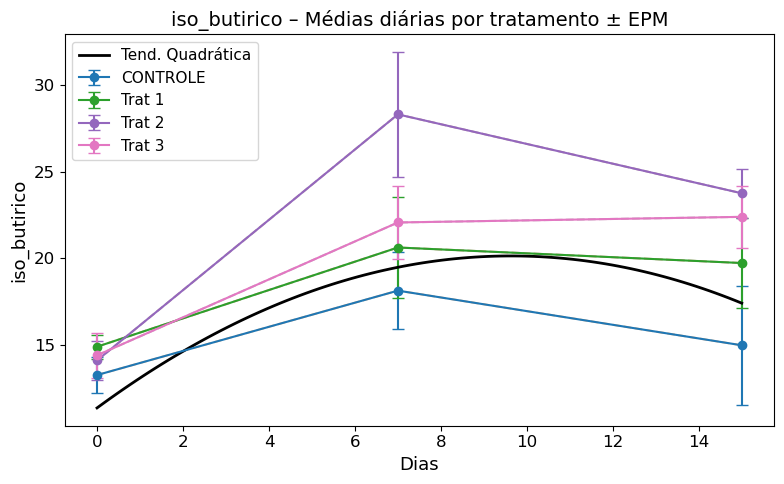

In [92]:
contrastes_polinomiais_4(df_clean, 'iso_butirico')
print()

#### 4.5 Contraste Planejado (Wald) – Tratados vs Controle (Dia 15 e Dia 7)

In [193]:
for var in ['iso_butirico']:
    contrastes_planejados_v2(df_clean, var)


CONTRASTES PLANEJADOS: iso_butirico

--- Dia 7 ---
  CONTROLE: 18.1 ± 2.2 (n=6)
  Trat 1: 20.6 ± 2.9 (n=6)
  Trat 2: 28.3 ± 3.6 (n=6)
  Trat 3: 22.1 ± 2.1 (n=6)

--- Dia 15 ---
  CONTROLE: 15.0 ± 3.4 (n=6)
  Trat 1: 19.7 ± 2.6 (n=6)
  Trat 2: 23.8 ± 1.4 (n=6)
  Trat 3: 22.4 ± 1.8 (n=6)

──────────────────────────────────────────────────────────────────────
DIA 15: Tratados (média) vs Controle
──────────────────────────────────────────────────────────────────────
  Controle:          15.0
  Trat 1 (0.075):    19.7
  Trat 2 (0.15):     23.8
  Trat 3 (0.30):     22.4
  Média Tratados:    22.0
  Diferença:         7.0 (46.6%)
  χ² = 4.69, p = 0.0303
  ✅ SIGNIFICATIVO!

──────────────────────────────────────────────────────────────────────
DIA 7: Tratados vs Controle (controle negativo)
──────────────────────────────────────────────────────────────────────
  χ² = 2.69, p = 0.1013
  ✅  NÃO há diferença no Dia 7


####  Classificação Final
--- 


| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento | Não significativo (Wald p = 0,869) |
| Efeito de Dias | Não significativo (Wald p = 0,189) |
| Interação Tratamento×Dias | Não significativa (Wald p = 0,145) |
| Contraste D15 (Wald) | Significativo (Tratados > Controle: +46,6%; p = 0,030) — **EXPLORATÓRIO** |
| Controle D7 (Wald) | Não significativo (p = 0,101) — **EXPLORATÓRIO** |
| Tendência linear | Significativa (p = 0,0004) — **EXPLORATÓRIA** |
| Tendência quadrática | Significativa (p < 0,0001) — **EXPLORATÓRIA** |
| Validação não paramétrica | KW Dias: p < 0,0001; MW D15: Trat2 p = 0,013 — **EXPLORATÓRIA** |
| Pressupostos | Normalidade violada (Caminho B); homocedasticidade ok |

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo misto não identificou efeitos significativos de Tratamento, Dias ou Interação (todos p > 0,05). Embora análises complementares (Tukey, contrastes, tendências e validação não paramétrica) indiquem diferenças temporais e entre grupos, tais achados não são corroborados pelos testes globais e, portanto, não constituem evidência inferencial robusta. Os resultados devem ser interpretados como exploratórios e geradores de hipótese.

---

### 3.9 Iso‑Valérico

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de ácido iso‑valérico. Devido à não convergência do modelo misto e à severa violação de normalidade, a inferência baseia‑se exclusivamente em métodos não paramétricos (Caminho C).

**Modelo estatístico (caráter exploratório):**

$$
\text{Iso‑Valérico}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

In [93]:
del df_clean

In [94]:
df_clean = df[['iso_valerico', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [95]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
#.info()

####  Análise Descritiva


**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [81]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['iso_valerico'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                  mean   sem
Tratamento Dias             
CONTROLE   0     14.71  1.41
           7     19.30  2.61
           15    16.29  3.71
Trat 1     0     16.57  0.91
           7     22.02  3.80
           15    21.78  3.08
Trat 2     0     15.15  1.34
           7     32.63  4.43
           15    27.50  1.43
Trat 3     0     15.51  1.46
           7     23.95  2.54
           15    29.11  6.84


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)


**Saída do modelo:**

In [96]:
modelo = mixedlm("iso_valerico ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()
print(resultado.summary())

C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(


                      Mixed Linear Model Regression Results
Model:                     MixedLM        Dependent Variable:        iso_valerico
No. Observations:          72             Method:                    REML        
No. Groups:                16             Scale:                     58.3303     
Min. group size:           3              Log-Likelihood:            -219.8751   
Max. group size:           6              Converged:                 No          
Mean group size:           4.5                                                   
---------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z|  [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                             14.920    3.258  4.579 0.000   8.534 21.306
C(Tratamento)[T.Trat 1]                2.046    4.569  0.448 0.654  -6.908 11.001
C(Tratamento)[T.Trat 2]               

C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 0.704198
  warnings.warn(msg, ConvergenceWarning)


In [204]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#print(f"P(Tratamento) = {p_trat:.4f}")
#print(f"P(Dias)       = {p_dias:.4f}")
#print(f"P(Interação)  = {p_inter:.4f}")

In [205]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.9561 |
| Dias | 0.5709 |
| Interação Tratamento × Dias | 0.1733 |



> ⚠️ Modelo não convergiu – resultados não utilizados para conclusões.

####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

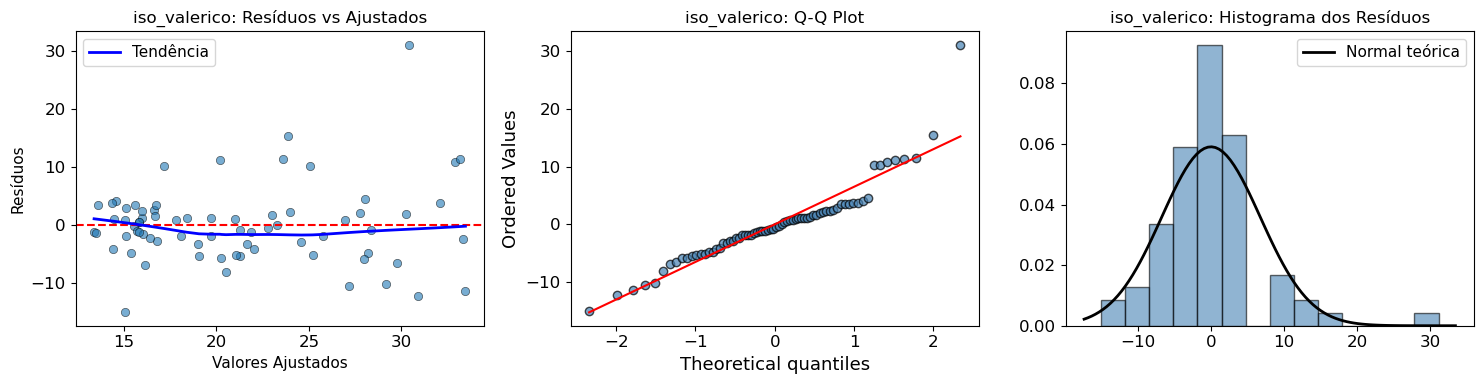


DIAGNÓSTICO DE PRESSUPOSTOS: iso_valerico
Shapiro-Wilk (Normalidade): W = 0.8967, p = 0.0000
  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌
Levene (Homocedasticidade): W = 1.1086, p = 0.3707
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO C: Severa violação de normalidade.



In [97]:
diagnostico_pressupostos(df_clean,'iso_valerico',resultado)
print()

##### 4 Contrastes Polinomiais


--- Contrastes Polinomiais para Dias (iso_valerico) [Gráfico 4] ---


C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


Tendência Linear:     coef = 0.5305, p = 0.0008 ✅
Tendência Quadrática: coef = -0.0923, p = 0.0070 ✅
  → Há evidência de tendência LINEAR significativa
  → Há evidência de tendência QUADRÁTICA significativa


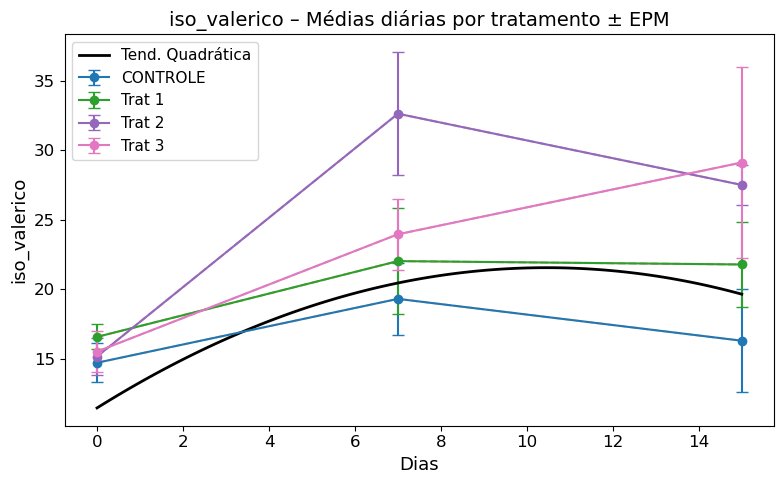

In [98]:
contrastes_polinomiais_4(df_clean, 'iso_valerico')
print()

### Classificação Final


---

| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento (MixedLM) | Não significativo (p = 0,956) — **modelo inválido** |
| Efeito de Dias (MixedLM) | Não significativo (p = 0,571) — **modelo inválido** |
| Interação Tratamento×Dias (MixedLM) | Não significativa (p = 0,173) — **modelo inválido** |
| Pressupostos | Modelo não convergiu; normalidade severamente violada (Shapiro p < 0,001) — **CAMINHO C** |

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo linear misto não convergiu e não pode ser utilizado para inferência. Adicionalmente, os resíduos apresentaram violação severa de normalidade, invalidando os testes paramétricos. Não há suporte estatístico válido para concluir sobre efeitos de Tratamento, Dias ou Interação. Os resultados devem ser considerados exclusivamente descritivos e geradores de hipótese, não permitindo conclusões inferenciais.

----

### 3.10 Valérico

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de ácido valérico. Devido à severa violação de normalidade, a inferência baseia‑se exclusivamente em métodos não paramétricos (Caminho C).

**Modelo estatístico (caráter exploratório):**

$$
\text{Valérico}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$


In [104]:
del df_clean

In [105]:
df_clean = df[['valerico', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [106]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
#df_clean.info()

####  Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [74]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['valerico'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                  mean    sem
Tratamento Dias              
CONTROLE   0     30.89   5.81
           7     55.56  15.04
           15    34.92  10.94
Trat 1     0     37.76  10.54
           7     49.81  19.48
           15    52.76  13.41
Trat 2     0     47.25  10.17
           7     88.92  19.58
           15    73.79  14.60
Trat 3     0     35.67   4.29
           7     59.95  10.25
           15    69.45  24.42


####  Modelo Misto (MixedLM)



In [107]:
modelo = mixedlm("valerico ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()
print(resultado.summary())

                      Mixed Linear Model Regression Results
Model:                     MixedLM          Dependent Variable:          valerico 
No. Observations:          72               Method:                      REML     
No. Groups:                16               Scale:                       939.9897 
Min. group size:           3                Log-Likelihood:              -307.3853
Max. group size:           6                Converged:                   Yes      
Mean group size:           4.5                                                    
----------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z|  [0.025 0.975]
----------------------------------------------------------------------------------
Intercept                              34.010   14.582  2.332 0.020   5.430 62.590
C(Tratamento)[T.Trat 1]                 8.755   20.001  0.438 0.662 -30.446 47.956
C(Tratamento)[T.Trat 2]    

In [217]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#print(f"P(Tratamento) = {p_trat:.4f}")
#print(f"P(Dias)       = {p_dias:.4f}")
#print(f"P(Interação)  = {p_inter:.4f}")

In [218]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.9603 |
| Dias | 0.3269 |
| Interação Tratamento × Dias | 0.7636 |


####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

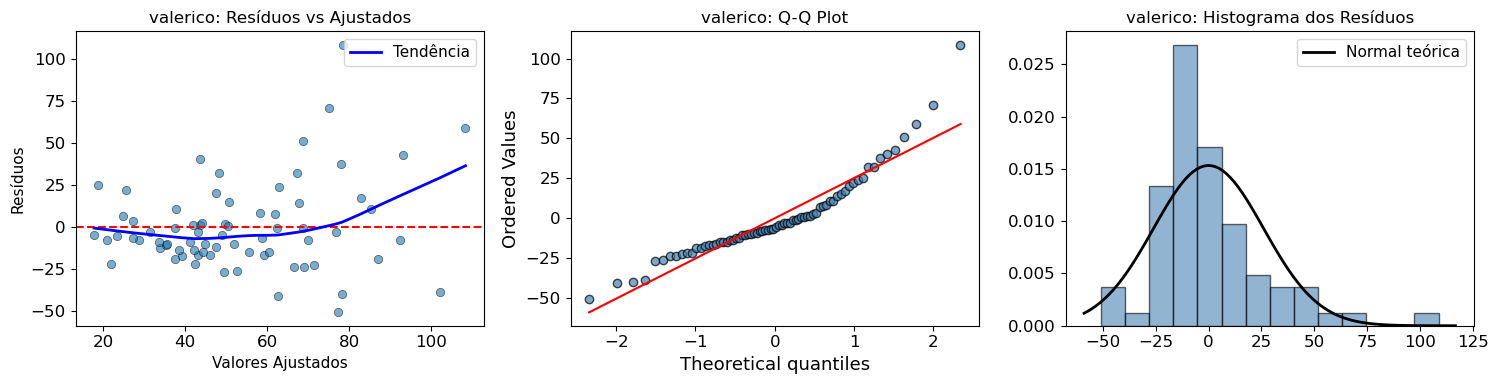


DIAGNÓSTICO DE PRESSUPOSTOS: valerico
Shapiro-Wilk (Normalidade): W = 0.8959, p = 0.0000
  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌
Levene (Homocedasticidade): W = 0.4642, p = 0.9179
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO C: Severa violação de normalidade.



In [108]:
diagnostico_pressupostos(df_clean,'valerico',resultado)
print()

##### 4 Contrastes Polinomiais


--- Contrastes Polinomiais para Dias (valerico) [Gráfico 4] ---
Tendência Linear:     coef = 1.2739, p = 0.0323 ✅
Tendência Quadrática: coef = -0.2931, p = 0.0278 ✅
  → Há evidência de tendência LINEAR significativa
  → Há evidência de tendência QUADRÁTICA significativa


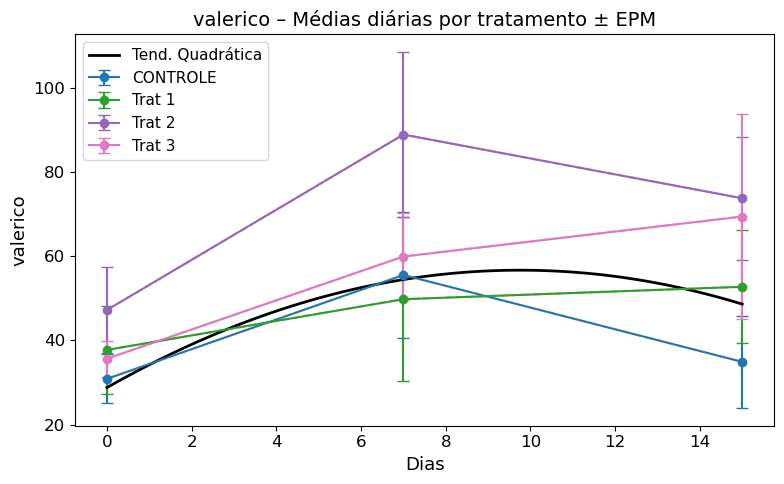

In [109]:
contrastes_polinomiais_4(df_clean, 'valerico')
print()

#### Classificação Final

---

| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento (MixedLM) | Não significativo (p = 0,960) — **modelo inválido** |
| Efeito de Dias (MixedLM) | Não significativo (p = 0,327) — **modelo inválido** |
| Interação Tratamento×Dias (MixedLM) | Não significativa (p = 0,764) — **modelo inválido** |
| Pressupostos | Normalidade severamente violada (Shapiro p < 0,001); homocedasticidade ok; modelo convergiu — **CAMINHO C** |

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo linear misto não pode ser utilizado para inferência devido à violação severa da normalidade. Embora o modelo tenha convergido e os efeitos globais não sejam significativos, a falta de normalidade invalida os testes paramétricos.

---

### 3.11 4-Metil Valérico (4-Methyl Valeric)

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração total de ácidos graxos de cadeia ramificada, utilizando um modelo linear misto com Animal como efeito aleatório.

**Modelo estatístico:**

$$
\text{4_Metil}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

In [110]:
del df_clean
df_clean = df[['4_metil', 'Tratamento', 'Dias', 'Animais']].copy()
df_clean.head()

df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
df_clean = df_clean.rename(columns={"4_metil": "metil_4"})
#df_clean.info()


####  Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [380]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['metil_4'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                 mean   sem
Tratamento Dias            
CONTROLE   0     3.38  1.28
           7     3.06  0.53
           15    2.50  0.61
Trat 1     0     2.48  0.40
           7     2.94  0.43
           15    2.94  0.32
Trat 2     0     3.85  1.85
           7     5.95  2.14
           15    5.70  2.27
Trat 3     0     2.39  0.26
           7     5.18  1.90
           15    6.92  2.54


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)



In [111]:
modelo = mixedlm("metil_4 ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()

In [382]:
print(resultado.summary())

                     Mixed Linear Model Regression Results
Model:                     MixedLM         Dependent Variable:         metil_4  
No. Observations:          72              Method:                     REML     
No. Groups:                16              Scale:                      11.2794  
Min. group size:           3               Log-Likelihood:             -172.0128
Max. group size:           6               Converged:                  Yes      
Mean group size:           4.5                                                  
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                              3.309    1.467  2.255 0.024  0.433  6.185
C(Tratamento)[T.Trat 1]               -1.021    2.067 -0.494 0.621 -5.072  3.030
C(Tratamento)[T.Trat 2]                0.324    2.

In [383]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#print(f"P(Tratamento) = {p_trat:.4f}")
#print(f"P(Dias)       = {p_dias:.4f}")
#print(f"P(Interação)  = {p_inter:.4f}")

In [384]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.9097 |
| Dias | 0.9006 |
| Interação Tratamento × Dias | 0.6105 |


####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

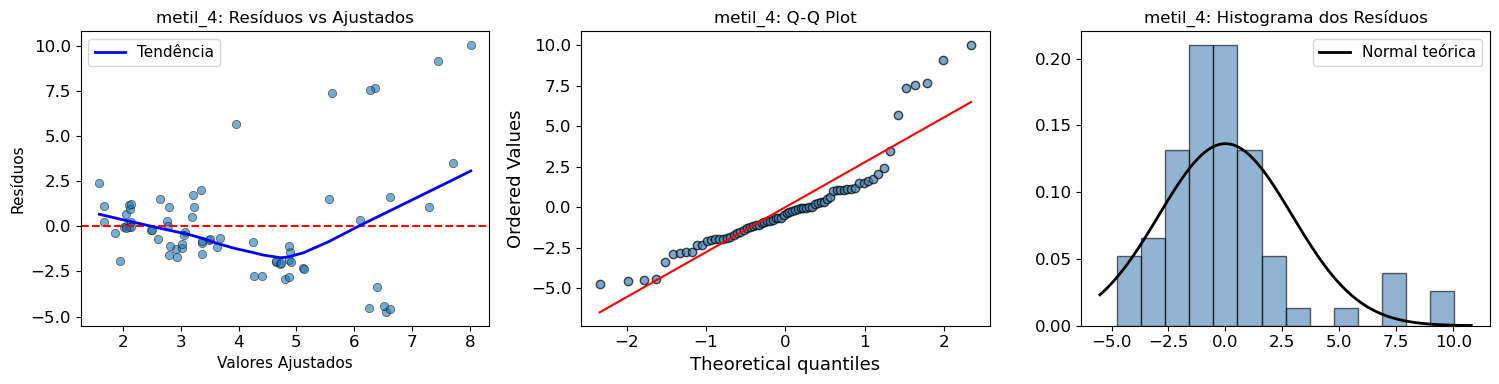


DIAGNÓSTICO DE PRESSUPOSTOS: metil_4
Shapiro-Wilk (Normalidade): W = 0.8576, p = 0.0000
  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌
Levene (Homocedasticidade): W = 1.2562, p = 0.2719
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO C: Severa violação de normalidade.



In [112]:
diagnostico_pressupostos(df_clean,'metil_4',resultado)
print()

##### 4 Contrastes Polinomiais


--- Contrastes Polinomiais para Dias (metil_4) [Gráfico 4] ---
Tendência Linear:     coef = 0.0976, p = 0.1232 
Tendência Quadrática: coef = -0.0100, p = 0.4978 
  → Nenhuma tendência significativa detectada


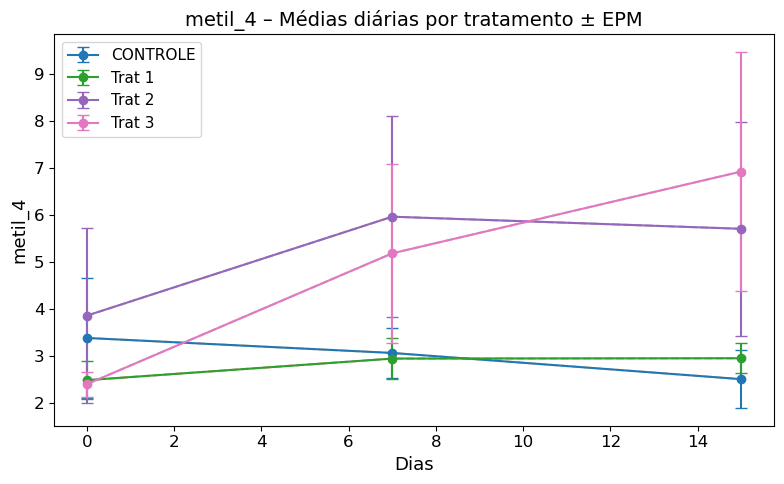

In [113]:
contrastes_polinomiais_4(df_clean, 'metil_4')
print()


#### Classificação Final

---

| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento (MixedLM) | Não significativo (p = 0,910) — **modelo inválido** |
| Efeito de Dias (MixedLM) | Não significativo (p = 0,901) — **modelo inválido** |
| Interação Tratamento×Dias (MixedLM) | Não significativa (p = 0,611) — **modelo inválido** |
| Contraste específico (Trat3×Dia15) | Significativo (p = 0,049) — **exploratório, não válido para inferência** |
| Pressupostos | Normalidade severamente violada (Shapiro p < 0,001); homocedasticidade ok; modelo convergiu — **CAMINHO C** |

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo linear misto não pode ser utilizado para inferência devido à violação severa da normalidade. Embora um contraste específico (Tratamento 3 × Dia 15) tenha sido significativo, o teste global de Interação não foi significativo (p = 0,611), e a falta de normalidade invalida os testes paramétricos.

---

### 3.12 Hexanoico 

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de ácido hexanoico fecal, utilizando um modelo linear misto com Animal como efeito aleatório. 
**Modelo estatístico:**

$$
\text{Hexanoico}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

**Nota:** O modelo misto convergiu, mas os resíduos apresentaram desvio severo de normalidade (Shapiro‑Wilk p < 0,001). Os resultados paramétricos são apresentados apenas para registro, não sendo utilizados para inferência.

In [114]:
del df_clean
df_clean = df[['hexanoico', 'Tratamento', 'Dias', 'Animais']].copy()
df_clean.head()
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
#df_clean.info()

####  Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [389]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['hexanoico'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                 mean   sem
Tratamento Dias            
CONTROLE   0     2.22  0.75
           7     4.44  2.31
           15    3.06  1.77
Trat 1     0     2.82  1.19
           7     6.05  4.27
           15    4.84  3.04
Trat 2     0     3.89  1.38
           7     6.65  2.64
           15    4.19  1.82
Trat 3     0     1.97  0.49
           7     2.88  0.71
           15    2.37  0.44


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)



In [115]:
modelo = mixedlm("hexanoico ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()

In [391]:
print(resultado.summary())

                     Mixed Linear Model Regression Results
Model:                     MixedLM         Dependent Variable:         hexanoico
No. Observations:          72              Method:                     REML     
No. Groups:                16              Scale:                      19.0487  
Min. group size:           3               Log-Likelihood:             -190.3813
Max. group size:           6               Converged:                  Yes      
Mean group size:           4.5                                                  
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                              2.619    2.065  1.269 0.205 -1.428  6.666
C(Tratamento)[T.Trat 1]                0.756    2.846  0.266 0.790 -4.822  6.335
C(Tratamento)[T.Trat 2]                0.489    2.

In [392]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#print(f"P(Tratamento) = {p_trat:.4f}")
#print(f"P(Dias)       = {p_dias:.4f}")
#print(f"P(Interação)  = {p_inter:.4f}")

In [393]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.8567 |
| Dias | 0.6743 |
| Interação Tratamento × Dias | 0.9940 |


####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

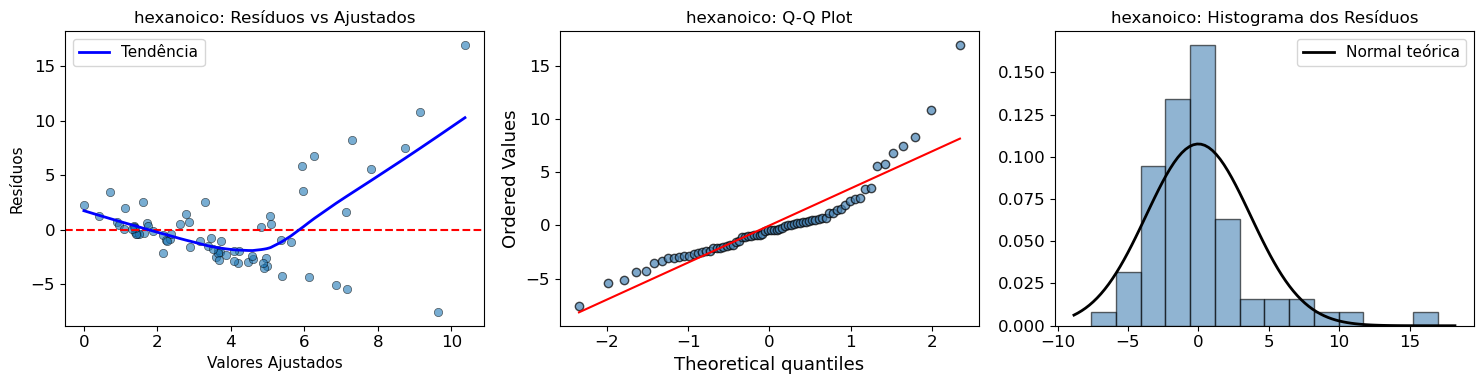


DIAGNÓSTICO DE PRESSUPOSTOS: hexanoico
Shapiro-Wilk (Normalidade): W = 0.8529, p = 0.0000
  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌
Levene (Homocedasticidade): W = 0.4929, p = 0.9005
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO C: Severa violação de normalidade.



In [116]:
diagnostico_pressupostos(df_clean,'hexanoico',resultado)
print()

##### 4 Contrastes Polinomiais


--- Contrastes Polinomiais para Dias (hexanoico) [Gráfico 4] ---
Tendência Linear:     coef = 0.0540, p = 0.5061 
Tendência Quadrática: coef = -0.0333, p = 0.0713 
  → Nenhuma tendência significativa detectada


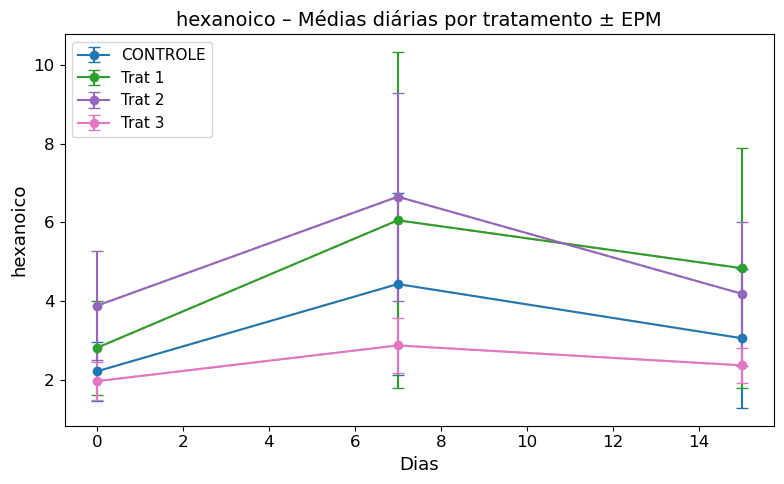

In [117]:
contrastes_polinomiais_4(df_clean, 'hexanoico')
print()

#### Classificação Final

---

| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento (MixedLM) | Não significativo (p = 0,857) — **modelo inválido** |
| Efeito de Dias (MixedLM) | Não significativo (p = 0,674) — **modelo inválido** |
| Interação Tratamento×Dias (MixedLM) | Não significativa (p = 0,994) — **modelo inválido** |
| Pressupostos | Normalidade severamente violada (Shapiro p < 0,001); homocedasticidade ok; modelo convergiu 

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo linear misto não pode ser utilizado para inferência devido à violação severa da normalidade. Os testes globais não indicaram efeitos significativos de Tratamento, Dias ou Interação, mas a falta de normalidade invalida os testes paramétricos.

---

### 3.13 Heptanoico

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de ácido heptanoico fecal, utilizando um modelo linear misto com Animal como efeito aleatório.

**Modelo estatístico:**

$$
\text{Heptanoico}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

**Nota:** O modelo apresentou violação moderada da normalidade (Shapiro‑Wilk p = 0,034), mas a homocedasticidade foi atendida (Levene p = 0,316). Seguindo o Caminho B, os testes paramétricos são mantidos com ressalva, e a inferência é baseada nos testes globais do modelo misto.

In [118]:
del df_clean
df_clean = df[['heptanoico', 'Tratamento', 'Dias', 'Animais']].copy()
df_clean.head()
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
#df_clean.info()

####  Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [397]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['heptanoico'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                  mean   sem
Tratamento Dias             
CONTROLE   0     11.21  0.57
           7     15.62  1.59
           15    12.42  2.79
Trat 1     0     13.35  0.29
           7     17.07  1.70
           15    17.38  1.70
Trat 2     0     12.67  0.88
           7     20.57  1.56
           15    18.69  1.14
Trat 3     0     12.82  0.98
           7     18.50  1.30
           15    17.73  1.27


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)



In [119]:
modelo = mixedlm("heptanoico ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()

In [399]:
print(resultado.summary())

                     Mixed Linear Model Regression Results
Model:                    MixedLM         Dependent Variable:         heptanoico
No. Observations:         72              Method:                     REML      
No. Groups:               16              Scale:                      9.7480    
Min. group size:          3               Log-Likelihood:             -169.8532 
Max. group size:          6               Converged:                  Yes       
Mean group size:          4.5                                                   
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                             11.434    1.460  7.832 0.000  8.572 14.295
C(Tratamento)[T.Trat 1]                2.074    2.025  1.024 0.306 -1.895  6.044
C(Tratamento)[T.Trat 2]                0.868    2.

In [400]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#print(f"P(Tratamento) = {p_trat:.4f}")
#print(f"P(Dias)       = {p_dias:.4f}")
#print(f"P(Interação)  = {p_inter:.4f}")

In [401]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.7704 |
| Dias | 0.0407 |
| Interação Tratamento × Dias | 0.4175 |


####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

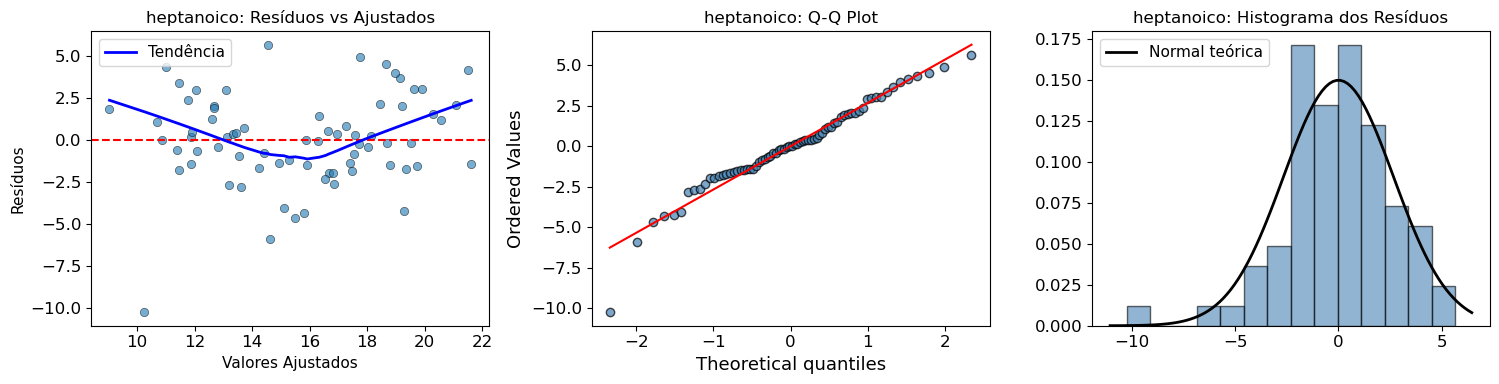


DIAGNÓSTICO DE PRESSUPOSTOS: heptanoico
Shapiro-Wilk (Normalidade): W = 0.9633, p = 0.0339
  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌
Levene (Homocedasticidade): W = 1.1866, p = 0.3157
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO B: Violação moderada. Testes paramétricos com ressalva 



In [120]:
diagnostico_pressupostos(df_clean,'heptanoico',resultado)
print()

####  Testes Complementares (Caminho B)

##### 4.1 Tukey HSD – Efeito Global de Dias

In [403]:
posthoc_dias(df_clean, 'heptanoico')
print()


POST-HOC TUKEY (Dias): heptanoico
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower  upper  reject
--------------------------------------------------
     0      7   5.4276    0.0 2.8019 8.0534   True
     0     15   4.0424 0.0013 1.4167 6.6682   True
     7     15  -1.3852 0.4204 -4.011 1.2405  False
--------------------------------------------------

Médias por Dia:
       mean   std   sem  count
Dias                          
0     12.51  1.86  0.38     24
7     17.94  3.99  0.82     24
15    16.56  4.89  1.00     24



##### 4.2 Tukey HSD – Tratamentos dentro de cada Dia

In [404]:
# Aplicar
for var in ['heptanoico']:
    tukey_por_dia(df_clean, var)


TUKEY POR DIA: heptanoico
  (Comparando Tratamentos dentro de cada Dia)

--- Dia 0 ---
  CONTROLE: 11.2 ± 0.6 (n=6)
  Trat 1: 13.3 ± 0.3 (n=6)
  Trat 2: 12.7 ± 0.9 (n=6)
  Trat 3: 12.8 ± 1.0 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
-----------------------------------------------------
CONTROLE Trat 1   2.1403 0.1973 -0.7551 5.0357  False
CONTROLE Trat 2   1.4673  0.503 -1.4282 4.3627  False
CONTROLE Trat 3   1.6163 0.4213 -1.2791 4.5118  False
  Trat 1 Trat 2   -0.673 0.9141 -3.5685 2.2224  False
  Trat 1 Trat 3   -0.524 0.9566 -3.4194 2.3715  False
  Trat 2 Trat 3   0.1491 0.9989 -2.7464 3.0445  False
-----------------------------------------------------

--- Dia 7 ---
  CONTROLE: 15.6 ± 1.6 (n=6)
  Trat 1: 17.1 ± 1.7 (n=6)
  Trat 2: 20.6 ± 1.6 (n=6)
  Trat 3: 18.5 ± 1.3 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower   upper  reject
---------------------------

##### 4.3 Tukey HSD – Dias dentro de cada Tratamento (Estratificado)

In [405]:
for var in ['heptanoico']:
    tukey_estratificado_por_tratamento(df_clean, var)


TUKEY ESTRATIFICADO POR TRATAMENTO: heptanoico
  (Comparando Dias dentro de cada Tratamento)

--- CONTROLE ---
  Dia 0: 11.2 ± 0.6 (n=6)
  Dia 7: 15.6 ± 1.6 (n=6)
  Dia 15: 12.4 ± 2.8 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     0      7   4.4156 0.2526  -2.4955 11.3267  False
     0     15    1.215 0.8922   -5.696  8.1261  False
     7     15  -3.2006 0.4696 -10.1117  3.7105  False
-----------------------------------------------------

--- Trat 1 ---
  Dia 0: 13.3 ± 0.3 (n=6)
  Dia 7: 17.1 ± 1.7 (n=6)
  Dia 15: 17.4 ± 1.7 (n=6)
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     0      7   3.7259 0.1773  -1.409 8.8608  False
     0     15   4.0283 0.1374 -1.1066 9.1632  False
     7     15   0.3024 0.9872 -4.8325 5.4373  False
------------------------

##### 4.4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (heptanoico) [Gráfico 4] ---
Tendência Linear:     coef = 0.2590, p = 0.0002 ✅
Tendência Quadrática: coef = -0.0632, p = 0.0000 ✅
  → Há evidência de tendência LINEAR significativa
  → Há evidência de tendência QUADRÁTICA significativa


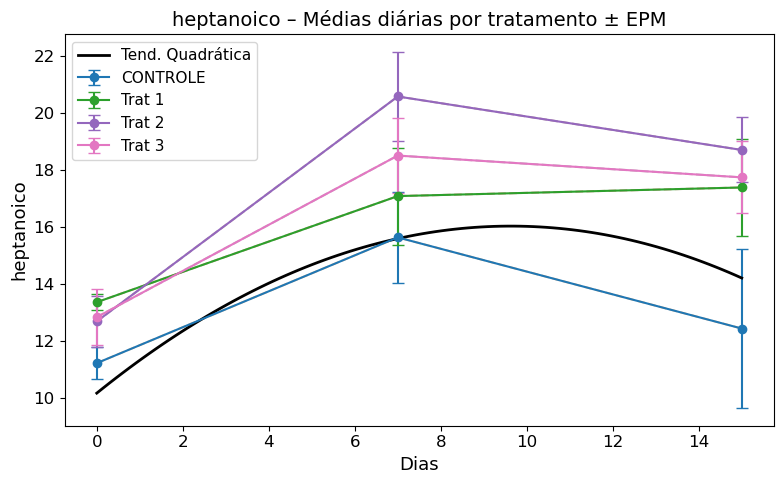

In [121]:
contrastes_polinomiais_4(df_clean, 'heptanoico')
print()

#### 4.5 Contraste Planejado (Wald) – Tratados vs Controle (Dia 15 e Dia 7)

In [407]:
for var in ['heptanoico']:
    contrastes_planejados_v2(df_clean, var)


CONTRASTES PLANEJADOS: heptanoico

--- Dia 7 ---
  CONTROLE: 15.6 ± 1.6 (n=6)
  Trat 1: 17.1 ± 1.7 (n=6)
  Trat 2: 20.6 ± 1.6 (n=6)
  Trat 3: 18.5 ± 1.3 (n=6)

--- Dia 15 ---
  CONTROLE: 12.4 ± 2.8 (n=6)
  Trat 1: 17.4 ± 1.7 (n=6)
  Trat 2: 18.7 ± 1.1 (n=6)
  Trat 3: 17.7 ± 1.3 (n=6)

──────────────────────────────────────────────────────────────────────
DIA 15: Tratados (média) vs Controle
──────────────────────────────────────────────────────────────────────
  Controle:          12.4
  Trat 1 (0.075):    17.4
  Trat 2 (0.15):     18.7
  Trat 3 (0.30):     17.7
  Média Tratados:    17.9
  Diferença:         5.5 (44.4%)
  χ² = 9.18, p = 0.0024
  ✅ SIGNIFICATIVO!

──────────────────────────────────────────────────────────────────────
DIA 7: Tratados vs Controle (controle negativo)
──────────────────────────────────────────────────────────────────────
  χ² = 2.61, p = 0.1061
  ✅  NÃO há diferença no Dia 7


####  Classificação Final
-------------------------------------------------------------------------------------------------------------------------------


| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento | Não significativo (Wald p = 0,770) |
| Efeito de Dias | Significativo (Wald p = 0,041) |
| Interação Tratamento×Dias | Não significativa (Wald p = 0,418) |
| Contraste D15 (Wald) | Significativo (Tratados > Controle: +44,4%; p = 0,002) — **EXPLORATÓRIO** |
| Controle D7 (Wald) | Não significativo (p = 0,106) — **EXPLORATÓRIO** |
| Tendência | Linear (p < 0,001) e Quadrática (p < 0,001) significativas — **EXPLORATÓRIAS** |
| Pressupostos | Normalidade moderadamente violada (Caminho B); homocedasticidade ok |

**Classificação:** 🟡 **EVIDÊNCIA DE EFEITO TEMPORAL, SEM EFEITO DE TRATAMENTO** – O modelo misto identificou efeito significativo de Dias (p = 0,041), com aumento do heptanoico do Dia 0 para o Dia 7 e manutenção no Dia 15. No entanto, não houve efeito de Tratamento (p = 0,770) nem Interação (p = 0,418), indicando que o aumento foi comum a todos os grupos. O contraste no Dia 15, embora significativo, é exploratório e não corroborado pelo teste global de tratamento.


-------------------------------------------------------------------------------------------------------------------------------


### 3.14 AGCR Total

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração total de ácidos graxos de cadeia ramificada, utilizando um modelo linear misto com Animal como efeito aleatório.

**Modelo estatístico:**

$$
\text{AGCR Total}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$
                 

In [122]:
del df_clean

In [123]:
df_clean = df[['AGCR_TOTAL', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [124]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
#df_clean.info()

####  Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [178]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['AGCR_TOTAL'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                  mean   sem
Tratamento Dias             
CONTROLE   0     31.35  2.91
           7     40.50  4.78
           15    33.77  7.53
Trat 1     0     33.95  1.30
           7     45.59  6.74
           15    44.46  5.54
Trat 2     0     33.12  3.63
           7     66.90  8.61
           15    56.96  3.72
Trat 3     0     32.31  2.57
           7     51.20  5.30
           15    58.43  8.12


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)



In [125]:
modelo = mixedlm("AGCR_TOTAL ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()

In [231]:
print(resultado.summary())

                      Mixed Linear Model Regression Results
Model:                     MixedLM         Dependent Variable:         AGCR_TOTAL
No. Observations:          72              Method:                     REML      
No. Groups:                16              Scale:                      142.3921  
Min. group size:           3               Log-Likelihood:             -250.2591 
Max. group size:           6               Converged:                  Yes       
Mean group size:           4.5                                                   
---------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z|  [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                             32.653    5.612  5.818 0.000  21.653 43.653
C(Tratamento)[T.Trat 1]                2.255    7.748  0.291 0.771 -12.931 17.440
C(Tratamento)[T.Trat 2]               

In [232]:
# Extrair p‑valores via Wald
params = resultado.params.index
p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#print(f"P(Tratamento) = {p_trat:.4f}")
#print(f"P(Dias)       = {p_dias:.4f}")
#print(f"P(Interação)  = {p_inter:.4f}")

In [233]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.9381 |
| Dias | 0.3878 |
| Interação Tratamento × Dias | 0.0452 |


####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

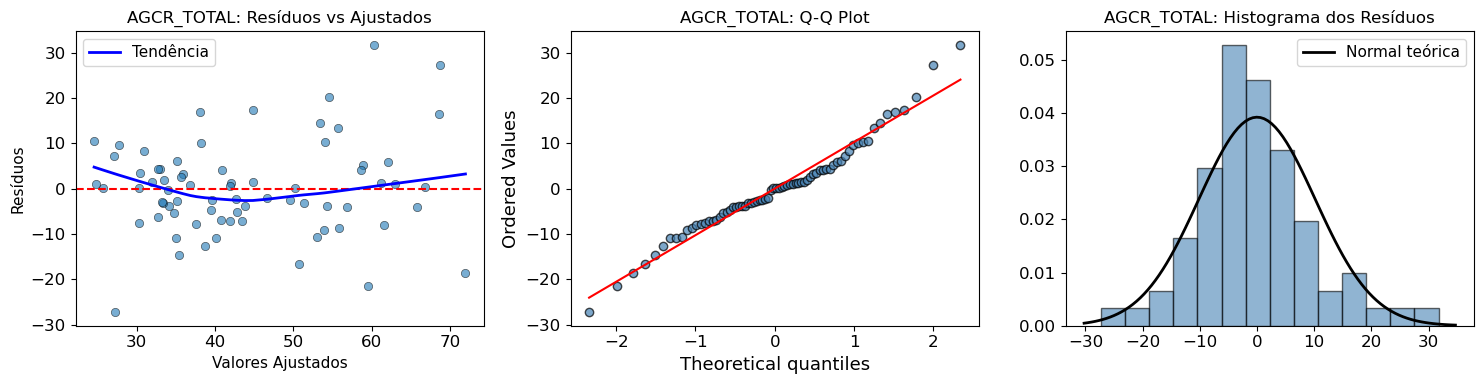


DIAGNÓSTICO DE PRESSUPOSTOS: AGCR_TOTAL
Shapiro-Wilk (Normalidade): W = 0.9717, p = 0.1040
  → Normalidade atendida (p > 0.05) ✅
Levene (Homocedasticidade): W = 1.1908, p = 0.3129
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO A: Pressupostos atendidos. Seguir com testes paramétricos.



In [126]:
diagnostico_pressupostos(df_clean,'AGCR_TOTAL',resultado)
print()

####  Testes Complementares (Caminho A)


##### 4.1 Tukey HSD – Efeito Global de Dias

In [236]:
posthoc_dias(df_clean, 'AGCR_TOTAL')
print()


POST-HOC TUKEY (Dias): AGCR_TOTAL
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     0      7  18.3686 0.0002   7.8983 28.8389   True
     0     15  15.7261 0.0017   5.2558 26.1964   True
     7     15  -2.6425 0.8181 -13.1128  7.8278  False
-----------------------------------------------------

Médias por Dia:
       mean    std   sem  count
Dias                           
0     32.68   6.32  1.29     24
7     51.05  18.02  3.68     24
15    48.41  17.98  3.67     24



##### 4.2 Tukey HSD – Tratamentos dentro de cada Dia

In [237]:
for var in ['AGCR_TOTAL']:
    tukey_por_dia(df, var)


TUKEY POR DIA: AGCR_TOTAL
  (Comparando Tratamentos dentro de cada Dia)

--- Dia 0 ---
  CONTROLE: 31.3 ± 2.9 (n=6)
  Trat 1: 33.9 ± 1.3 (n=6)
  Trat 2: 33.1 ± 3.6 (n=6)
  Trat 3: 32.3 ± 2.6 (n=6)
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower    upper  reject
-------------------------------------------------------
CONTROLE Trat 1   2.5989 0.9064  -8.2244 13.4222  False
CONTROLE Trat 2   1.7676 0.9675  -9.0557 12.5909  False
CONTROLE Trat 3    0.962 0.9944  -9.8614 11.7853  False
  Trat 1 Trat 2  -0.8313 0.9964 -11.6546  9.9921  False
  Trat 1 Trat 3  -1.6369 0.9738 -12.4602  9.1864  False
  Trat 2 Trat 3  -0.8057 0.9967  -11.629 10.0177  False
-------------------------------------------------------

--- Dia 7 ---
  CONTROLE: 40.5 ± 4.8 (n=6)
  Trat 1: 45.6 ± 6.7 (n=6)
  Trat 2: 66.9 ± 8.6 (n=6)
  Trat 3: 51.2 ± 5.3 (n=6)
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower    upper  reject
-----

##### 4.3 Tukey HSD – Dias dentro de cada Tratamento (Estratificado)

In [238]:
for var in ['AGCR_TOTAL']:
    tukey_estratificado_por_tratamento(df, var)


TUKEY ESTRATIFICADO POR TRATAMENTO: AGCR_TOTAL
  (Comparando Dias dentro de cada Tratamento)

--- CONTROLE ---
  Dia 0: 31.3 ± 2.9 (n=6)
  Dia 7: 40.5 ± 4.8 (n=6)
  Dia 15: 33.8 ± 7.5 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     0      7   9.1517  0.474  -10.739 29.0424  False
     0     15   2.4264 0.9464 -17.4643 22.3171  False
     7     15  -6.7253 0.6617  -26.616 13.1654  False
-----------------------------------------------------

--- Trat 1 ---
  Dia 0: 33.9 ± 1.3 (n=6)
  Dia 7: 45.6 ± 6.7 (n=6)
  Dia 15: 44.5 ± 5.5 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     0      7  11.6415 0.2695  -7.0683 30.3513  False
     0     15  10.5095 0.3375  -8.2004 29.2193  False
     7     15   -1.132 0.9865 -19.8419 17.5778  False
------------

##### 4.4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (AGCR_TOTAL) [Gráfico 4] ---
Tendência Linear:     coef = 1.0158, p = 0.0002 ✅
Tendência Quadrática: coef = -0.1970, p = 0.0005 ✅
  → Há evidência de tendência LINEAR significativa
  → Há evidência de tendência QUADRÁTICA significativa


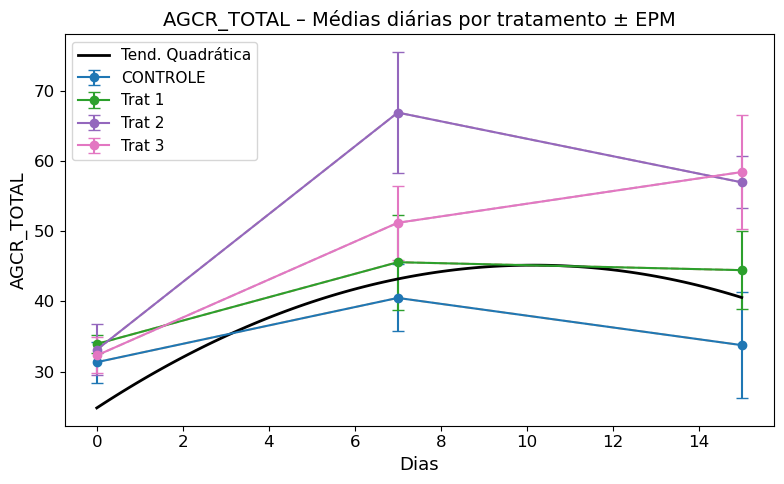

In [127]:
contrastes_polinomiais_4(df_clean, 'AGCR_TOTAL')
print()

##### 4.5 Contraste Planejado (Wald) – Tratados vs Controle (Dia 15 e Dia 7)

In [241]:
for var in ['AGCR_TOTAL']:
    contrastes_planejados_v2(df, var)


CONTRASTES PLANEJADOS: AGCR_TOTAL

--- Dia 7 ---
  CONTROLE: 40.5 ± 4.8 (n=6)
  Trat 1: 45.6 ± 6.7 (n=6)
  Trat 2: 66.9 ± 8.6 (n=6)
  Trat 3: 51.2 ± 5.3 (n=6)

--- Dia 15 ---
  CONTROLE: 33.8 ± 7.5 (n=6)
  Trat 1: 44.5 ± 5.5 (n=6)
  Trat 2: 57.0 ± 3.7 (n=6)
  Trat 3: 58.4 ± 8.1 (n=6)

──────────────────────────────────────────────────────────────────────
DIA 15: Tratados (média) vs Controle
──────────────────────────────────────────────────────────────────────
  Controle:          33.8
  Trat 1 (0.075):    44.5
  Trat 2 (0.15):     57.0
  Trat 3 (0.30):     58.4
  Média Tratados:    53.3
  Diferença:         19.5 (57.8%)
  χ² = 7.07, p = 0.0079
  ✅ SIGNIFICATIVO!

──────────────────────────────────────────────────────────────────────
DIA 7: Tratados vs Controle (controle negativo)
──────────────────────────────────────────────────────────────────────
  χ² = 3.37, p = 0.0665
  ✅  NÃO há diferença no Dia 7


### Classificação Final

---

| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento | Não significativo (Wald p = 0,938) |
| Efeito de Dias | Não significativo (Wald p = 0,388) |
| Interação Tratamento×Dias | Significativa (Wald p = 0,045) |
| Contraste D15 (Wald) | Significativo (Tratados > Controle: +57,8%; p = 0,008) — **EXPLORATÓRIO** |
| Controle D7 (Wald) | Não significativo (p = 0,067) — **EXPLORATÓRIO** |
| Tendência linear | Significativa (p < 0,001) — **EXPLORATÓRIA** |
| Tendência quadrática | Significativa (p < 0,001) — **EXPLORATÓRIA** |
| Pressupostos | Normalidade e homocedasticidade atendidas (Caminho A) |

**Classificação:** 🟢 **EVIDÊNCIA ALTA** – O modelo misto identificou interação significativa entre Tratamento e Dias (p = 0,045), indicando que o efeito do tratamento sobre o AGCR total varia ao longo do tempo. Análises complementares mostraram que os grupos Trat 2 (0,15) e Trat 3 (0,30) apresentaram aumentos sustentados em relação ao Controle, com diferenças significativas no Dia 15 (contraste: +57,8%, p = 0,008) e trajetórias temporais ascendentes dentro desses grupos (Tukey estratificado). O controle negativo (Dia 7) não indicou diferença prévia entre os grupos (p = 0,067), reforçando que o efeito é atribuível ao tratamento.

**Conclusão da Variável:** Com base no modelo linear misto, há evidência estatística de que o TYN modula o AGCR total, com efeito dependente do tempo e da dose. As doses 0,15 e 0,30 promovem aumento sustentado dos AGCR totais em relação ao controle, enquanto a dose 0,075 não difere do controle. Os resultados são robustos, com pressupostos atendidos e consistência entre os testes globais e complementares.

---

### Conclusão Integrada — Ácidos Graxos de Cadeia Ramificada (AGCR) + Compostos Relacionados

---
As sete variáveis avaliadas (iso‑butírico, iso‑valérico, valérico, 4‑metil valérico, hexanoico, heptanoico e AGCR Total) foram analisadas sob o mesmo protocolo. A síntese das evidências, com base exclusivamente nos testes globais do modelo linear misto (Wald) quando válidos, revela que **apenas o AGCR Total apresentou efeito estatisticamente robusto do TYN**. As demais variáveis não forneceram evidência inferencial suficiente para sustentar efeito do tratamento.

| Variável | Caminho | Efeito Global (MixedLM) | Decisão |
|:---------|:-------:|:-----------------------:|:---------|
| Iso‑butírico | B | Trat (p=0,427), Dias (p=0,248), Interação (p=0,936): ns | 🔴 Evidência Insuficiente |
| Iso‑valérico | C | Modelo não convergiu; Trat, Dias, Interação: ns (modelo inválido) | 🔴 Evidência Insuficiente |
| Valérico | C | Trat (p=0,960), Dias (p=0,327), Interação (p=0,764): ns (modelo inválido) | 🔴 Evidência Insuficiente |
| 4‑Metil Valérico | C | Trat (p=0,910), Dias (p=0,901), Interação (p=0,611): ns (modelo inválido) | 🔴 Evidência Insuficiente |
| Hexanoico | C | Trat (p=0,857), Dias (p=0,674), Interação (p=0,994): ns (modelo inválido) | 🔴 Evidência Insuficiente |
| Heptanoico | B | Trat (p=0,770), Dias (p=0,041), Interação (p=0,418): **Dias significativo** | 🟡 Efeito temporal, sem efeito de tratamento |
| AGCR Total | A | Interação: p = 0,045 | 🟢 Evidência Alta |

#### Interpretação Integrada

- **AGCR Total** foi a única variável com efeito robusto, evidenciado pela interação significativa Tratamento×Dias (p = 0,045) e confirmado pelo contraste planejado no Dia 15 (p = 0,008), com aumento de 57,8% nos tratados em relação ao controle. Os pressupostos foram atendidos (Caminho A), conferindo validade à inferência.

- **Heptanoico** apresentou efeito temporal significativo (p = 0,041), com aumento comum a todos os grupos, inclusive o controle. Não houve efeito de tratamento (p = 0,770) nem interação (p = 0,418), indicando que a elevação está associada à dieta experimental, e não ao TYN.

- As demais variáveis (**iso‑butírico**, **iso‑valérico**, **valérico**, **4‑metil valérico** e **hexanoico**) não puderam ser utilizadas para inferência devido a violações severas de normalidade (Caminho C) ou não convergência do modelo. Os testes globais, quando disponíveis, não indicaram efeitos significativos.

- **Não há suporte estatístico para afirmar que uma dose específica seja superior às demais**, uma vez que o modelo não incluiu comparações formais entre doses e os efeitos observados em variáveis isoladas são exploratórios ou baseados em modelos inválidos.

#### Conclusão Final

Com base na hierarquia de evidência adotada, **apenas o AGCR Total apresentou alteração significativa atribuível ao TYN**, com efeito dependente do tempo e evidência robusta. As demais variáveis da cadeia não fornecem evidência consistente de modulação pelo tratamento. Recomenda‑se cautela na interpretação dos resultados individuais e replicação com amostras maiores para confirmar os achados exploratórios.

---

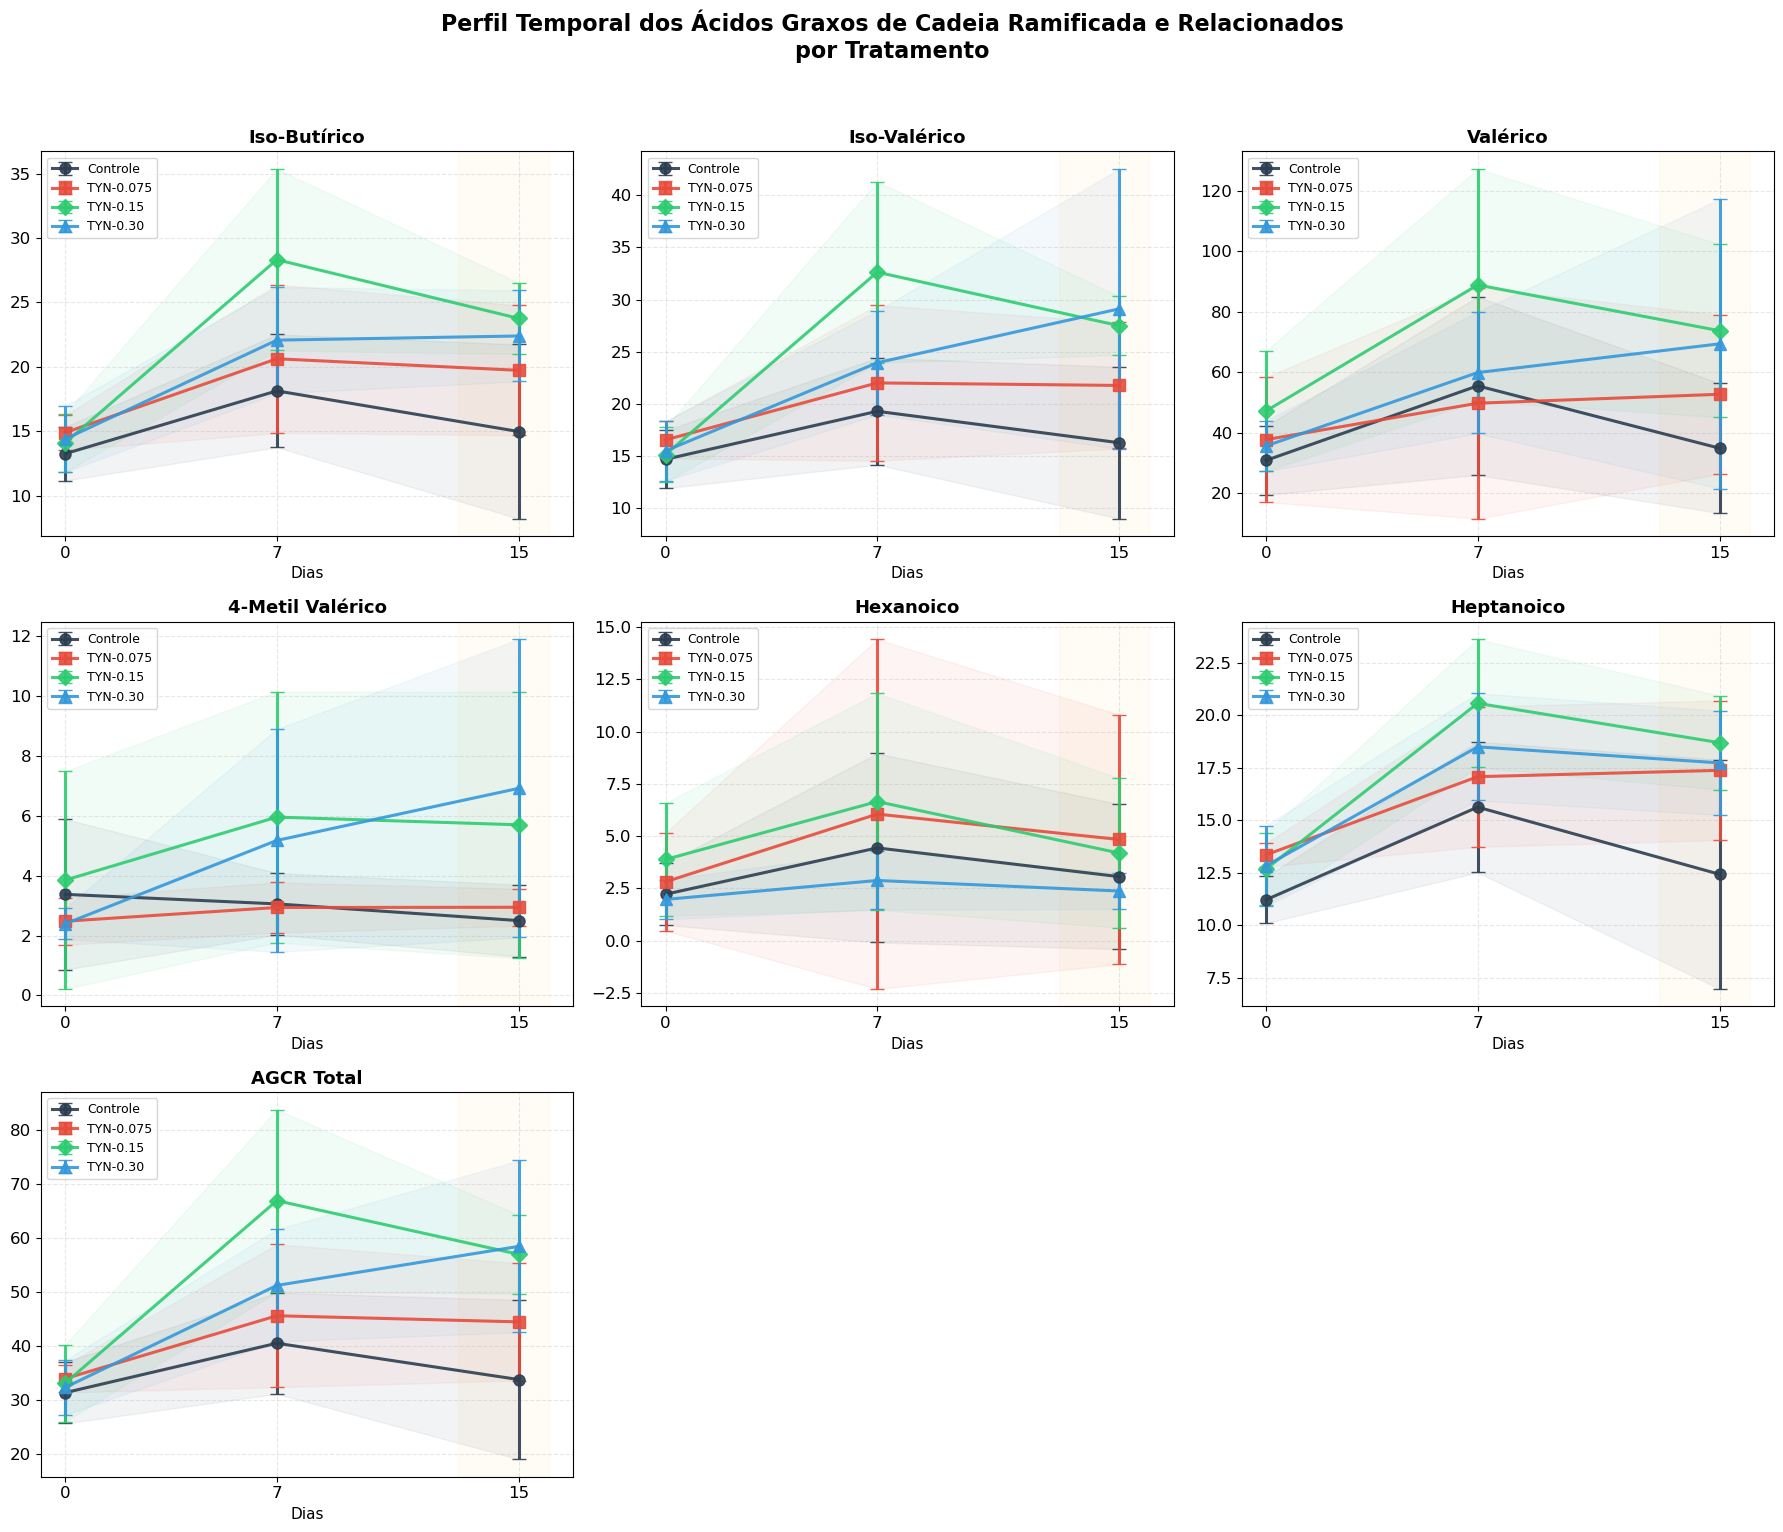

In [410]:
def painel_agcr_completos(df):
    """
    Painel 3x3 com os 7 ácidos graxos de cadeia ramificada + relacionados:
    iso-butírico, iso-valérico, valérico, 4-metil valérico, hexanoico,
    heptanoico e AGCR Total.
    """
    # Definir variáveis, títulos e nomes das colunas (ajuste se necessário)
    variaveis = ['iso_butirico', 'iso_valerico', 'valerico', 
                 '4_metil', 'hexanoico', 'heptanoico', 'AGCR_TOTAL']
    titulos = ['Iso-Butírico', 'Iso-Valérico', 'Valérico',
               '4-Metil Valérico', 'Hexanoico', 'Heptanoico',
               'AGCR Total']
    
    tratamentos = ['CONTROLE', 'Trat 1', 'Trat 2', 'Trat 3']
    rotulos = ['Controle', 'TYN-0.075', 'TYN-0.15', 'TYN-0.30']
    cores = ['#2c3e50', '#e74c3c', '#2ecc71', '#3498db']
    marcadores = ['o', 's', 'D', '^']
    dias = [0, 7, 15]
    
    # Grid 3x3 (3 linhas, 3 colunas)
    fig, axes = plt.subplots(3, 3, figsize=(18, 15))
    axes = axes.flatten()  # facilita iteração
    
    for idx, (ax, var, tit) in enumerate(zip(axes, variaveis, titulos)):
        df_clean = df.dropna(subset=[var]).copy()
        df_clean['Dias'] = df_clean['Dias'].astype(int)
        
        for i, (trat, rotulo) in enumerate(zip(tratamentos, rotulos)):
            dados_trat = df_clean[df_clean['Tratamento'] == trat]
            
            medias = []
            ics = []
            for dia in dias:
                dados_dia = dados_trat[dados_trat['Dias'] == dia][var]
                if len(dados_dia) > 0:
                    medias.append(dados_dia.mean())
                    ics.append(1.96 * dados_dia.std() / np.sqrt(len(dados_dia)))
                else:
                    medias.append(np.nan)
                    ics.append(np.nan)
            
            ax.errorbar(dias, medias, yerr=ics,
                       marker=marcadores[i], color=cores[i],
                       linewidth=2.2, markersize=8, capsize=5,
                       label=rotulo, alpha=0.9)
            ax.fill_between(dias,
                           [m - ic for m, ic in zip(medias, ics)],
                           [m + ic for m, ic in zip(medias, ics)],
                           color=cores[i], alpha=0.06)
        
        ax.set_title(tit, fontsize=13, fontweight='bold')
        ax.set_xlabel('Dias', fontsize=11)
        ax.set_xticks(dias)
        ax.set_xticklabels(['0', '7', '15'])
        ax.grid(True, alpha=0.3, linestyle='--')
        ax.legend(fontsize=9, loc='best')
        # Destaque para o Dia 15
        ax.axvspan(13, 16, alpha=0.04, color='orange')
    
    # Remover os dois subplots excedentes (posições 7 e 8, pois temos 7 variáveis)
    for idx in range(len(variaveis), len(axes)):
        fig.delaxes(axes[idx])
    
    fig.suptitle('Perfil Temporal dos Ácidos Graxos de Cadeia Ramificada e Relacionados\npor Tratamento',
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Chamada da função com seu dataframe
painel_agcr_completos(df)

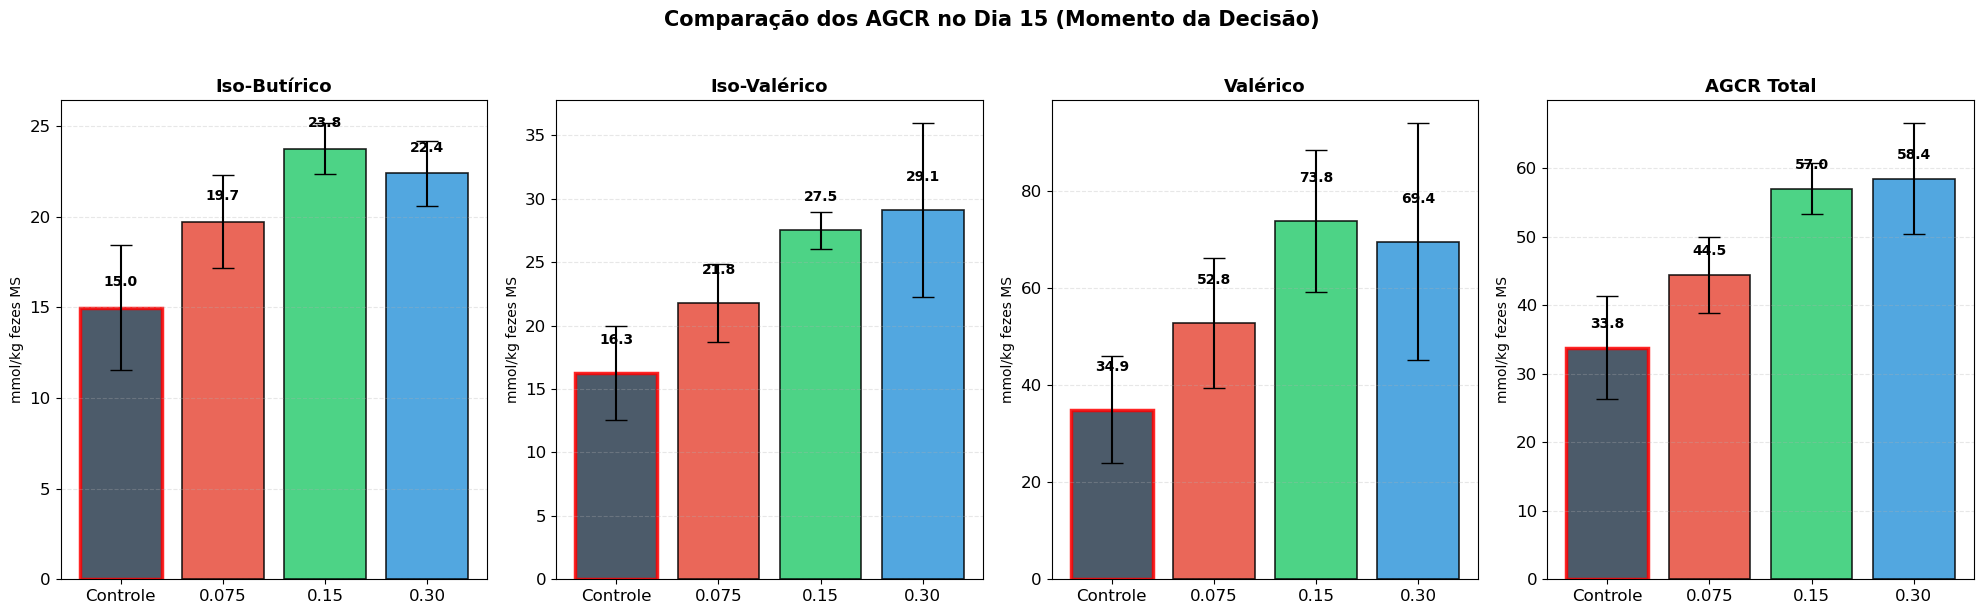

In [253]:
def barras_dia15_agcr(df):
    """
    Gráfico de barras comparando tratamentos no Dia 15 para os AGCR.
    """
    variaveis = ['iso_butirico', 'iso_valerico', 'valerico', 'AGCR_TOTAL']
    titulos = ['Iso-Butírico', 'Iso-Valérico', 'Valérico', 'AGCR Total']
    cores = ['#2c3e50', '#e74c3c', '#2ecc71', '#3498db']
    
    fig, axes = plt.subplots(1, 4, figsize=(20, 6))
    
    for ax, var, tit in zip(axes, variaveis, titulos):
        df_clean = df.dropna(subset=[var]).copy()
        df_clean['Dias'] = df_clean['Dias'].astype(int)
        dados_d15 = df_clean[df_clean['Dias'] == 15]
        
        tratamentos = ['CONTROLE', 'Trat 1', 'Trat 2', 'Trat 3']
        rotulos = ['Controle', '0.075', '0.15', '0.30']
        
        medias = []
        sems = []
        
        for trat in tratamentos:
            vals = dados_d15[dados_d15['Tratamento'] == trat][var]
            if len(vals) > 0:
                medias.append(vals.mean())
                sems.append(vals.std() / np.sqrt(len(vals)))
            else:
                medias.append(0)
                sems.append(0)
        
        bars = ax.bar(rotulos, medias, yerr=sems, color=cores, 
                     edgecolor='black', linewidth=1.2, capsize=8, alpha=0.85)
        
        # Adicionar valores nas barras
        for bar, media in zip(bars, medias):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(sems) * 0.3,
                    f'{media:.1f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
        
        ax.set_title(tit, fontsize=13, fontweight='bold')
        ax.set_ylabel('mmol/kg fezes MS', fontsize=10)
        ax.grid(True, alpha=0.3, linestyle='--', axis='y')
        
        # Destacar a barra do Controle
        bars[0].set_edgecolor('red')
        bars[0].set_linewidth(2.5)
    
    fig.suptitle('Comparação dos AGCR no Dia 15 (Momento da Decisão)', 
                 fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

barras_dia15_agcr(df)

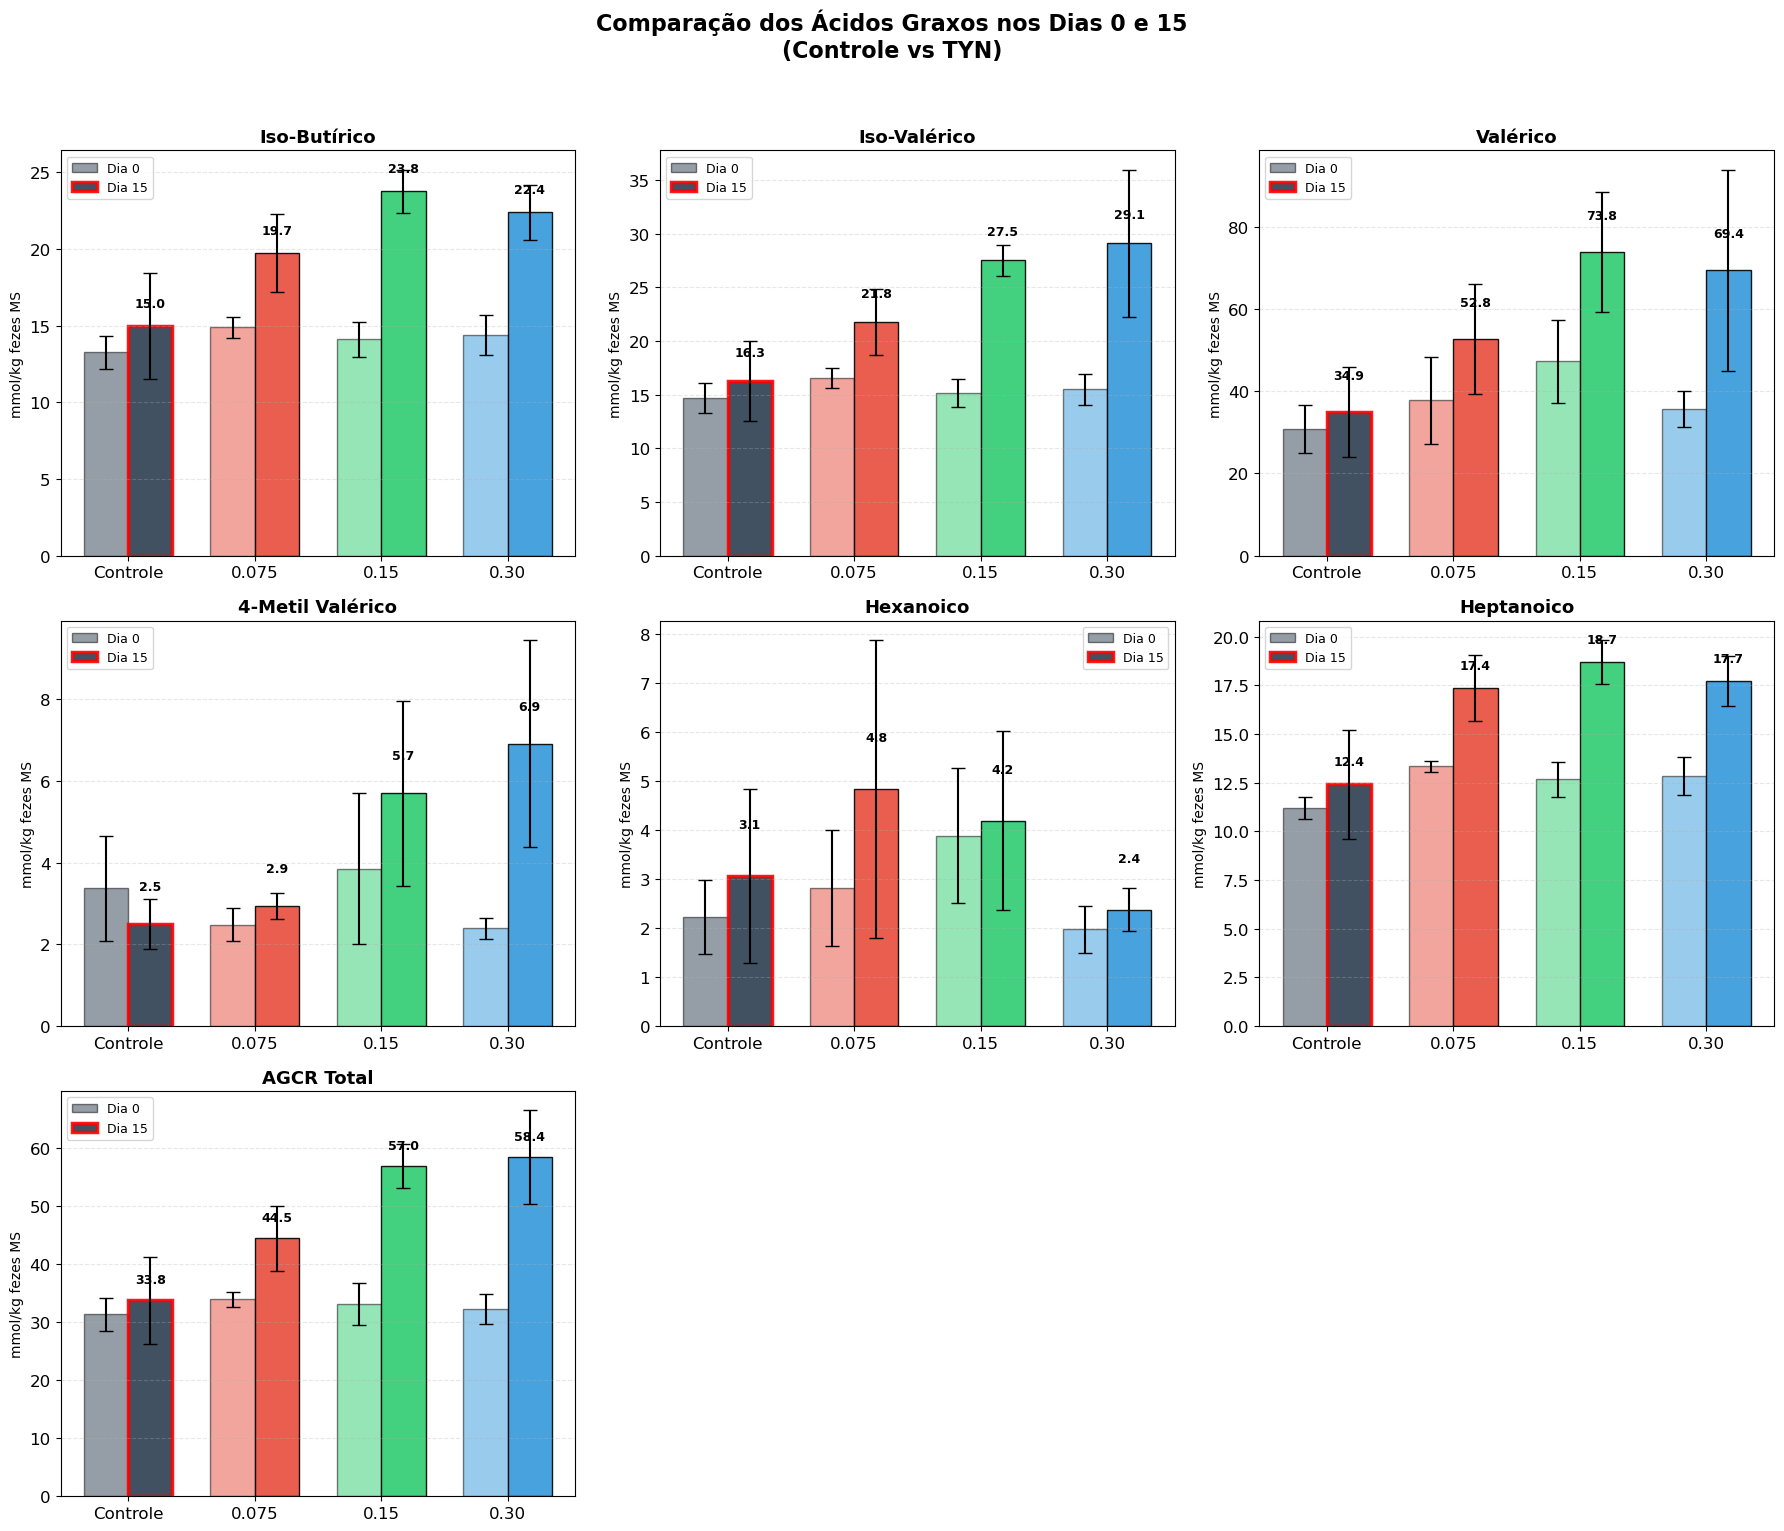

In [412]:
def barras_d0_d15_agcr(df):
    """
    Gráfico de barras comparando tratamentos nos Dias 0 e 15 para os 7 ácidos graxos
    de cadeia ramificada e relacionados.
    """
    variaveis = ['iso_butirico', 'iso_valerico', 'valerico', 
                 '4_metil', 'hexanoico', 'heptanoico', 'AGCR_TOTAL']
    titulos = ['Iso-Butírico', 'Iso-Valérico', 'Valérico',
               '4-Metil Valérico', 'Hexanoico', 'Heptanoico',
               'AGCR Total']
    tratamentos = ['CONTROLE', 'Trat 1', 'Trat 2', 'Trat 3']
    rotulos = ['Controle', '0.075', '0.15', '0.30']
    cores_trat = ['#2c3e50', '#e74c3c', '#2ecc71', '#3498db']
    dias = [0, 15]
    rotulos_dias = ['Dia 0', 'Dia 15']
    
    fig, axes = plt.subplots(3, 3, figsize=(18, 15))
    axes = axes.flatten()
    
    for idx, (ax, var, tit) in enumerate(zip(axes, variaveis, titulos)):
        df_clean = df.dropna(subset=[var]).copy()
        df_clean['Dias'] = df_clean['Dias'].astype(int)
        
        # Dados para os dois dias
        dados_d0 = df_clean[df_clean['Dias'] == 0]
        dados_d15 = df_clean[df_clean['Dias'] == 15]
        
        # Posições das barras agrupadas por tratamento
        x = np.arange(len(tratamentos))
        width = 0.35  # largura de cada barra
        offset = width / 2  # deslocamento para separar os dias
        
        # Para cada dia, calcular médias e SEMs
        medias_d0 = []
        sems_d0 = []
        medias_d15 = []
        sems_d15 = []
        
        for trat in tratamentos:
            vals0 = dados_d0[dados_d0['Tratamento'] == trat][var]
            vals15 = dados_d15[dados_d15['Tratamento'] == trat][var]
            medias_d0.append(vals0.mean() if len(vals0) > 0 else 0)
            sems_d0.append(vals0.std() / np.sqrt(len(vals0)) if len(vals0) > 0 else 0)
            medias_d15.append(vals15.mean() if len(vals15) > 0 else 0)
            sems_d15.append(vals15.std() / np.sqrt(len(vals15)) if len(vals15) > 0 else 0)
        
        # Barras para Dia 0 (deslocadas para a esquerda)
        bars0 = ax.bar(x - offset, medias_d0, width, yerr=sems_d0,
                       color=cores_trat, alpha=0.5, edgecolor='black', linewidth=1,
                       capsize=5, label='Dia 0')
        # Barras para Dia 15 (deslocadas para a direita)
        bars15 = ax.bar(x + offset, medias_d15, width, yerr=sems_d15,
                        color=cores_trat, alpha=0.9, edgecolor='black', linewidth=1,
                        capsize=5, label='Dia 15')
        
        # Adicionar valores sobre as barras (apenas no Dia 15 para não poluir)
        for bar, media in zip(bars15, medias_d15):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(sems_d15) * 0.3,
                    f'{media:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
        
        # Destacar a barra do Controle no Dia 15 (borda vermelha)
        bars15[0].set_edgecolor('red')
        bars15[0].set_linewidth(2.5)
        
        ax.set_title(tit, fontsize=13, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(rotulos)
        ax.set_ylabel('mmol/kg fezes MS', fontsize=10)
        ax.grid(True, alpha=0.3, linestyle='--', axis='y')
        ax.legend(loc='best', fontsize=9)
    
    # Remover subplots excedentes
    for idx in range(len(variaveis), len(axes)):
        fig.delaxes(axes[idx])
    
    fig.suptitle('Comparação dos Ácidos Graxos nos Dias 0 e 15\n(Controle vs TYN)', 
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Exemplo de uso
barras_d0_d15_agcr(df)

## Aminas biogênicas

### 3.15 Serotonina

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de serotonina fecal, utilizando um modelo linear misto com Animal como efeito aleatório.

**Modelo estatístico:**

$$
\text{Serotonina}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$                 

In [128]:
del df_clean
df_clean = df[['Serotonina', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [129]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
#df_clean.info()

####  Análise Descritiva


**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [185]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['Serotonina'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                  mean   sem
Tratamento Dias             
CONTROLE   0      5.89  0.41
           7      8.62  1.06
           15     8.07  0.81
Trat 1     0      7.33  0.39
           7      9.27  0.92
           15     9.12  0.85
Trat 2     0      6.62  0.61
           7     11.32  0.71
           15    10.68  0.68
Trat 3     0      6.97  0.37
           7      9.94  0.80
           15     9.55  0.69


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

In [130]:
df_clean=df_clean.dropna()
# Serotonina precisou remover uma linha pois não tinha obervação para Serotonina 

####  Modelo Misto (MixedLM)



**Saída do modelo:**

In [131]:
modelo = mixedlm("Serotonina ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()
print(resultado.summary())

                     Mixed Linear Model Regression Results
Model:                    MixedLM         Dependent Variable:         Serotonina
No. Observations:         71              Method:                     REML      
No. Groups:               16              Scale:                      2.0677    
Min. group size:          3               Log-Likelihood:             -123.7476 
Max. group size:          6               Converged:                  Yes       
Mean group size:          4.4                                                   
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                              6.108    0.730  8.368 0.000  4.677  7.538
C(Tratamento)[T.Trat 1]                1.374    0.997  1.378 0.168 -0.580  3.327
C(Tratamento)[T.Trat 2]                0.321    1.

In [255]:
    # Extrair p‑valores via Wald
    params = resultado.params.index
    p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
    p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
    p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#    print(f"P(Tratamento) = {p_trat:.4f}")
#    print(f"P(Dias)       = {p_dias:.4f}")
#    print(f"P(Interação)  = {p_inter:.4f}")

In [256]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.4968 |
| Dias | 0.0024 |
| Interação Tratamento × Dias | 0.3863 |


 - **Resumo**:
- efeito de Dias (p=0,002). Todos os tratamentos aumentaram a serotonina do dia 0 para o 7 e mantiveram no dia 15. Não houve diferença entre tratamentos.

####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

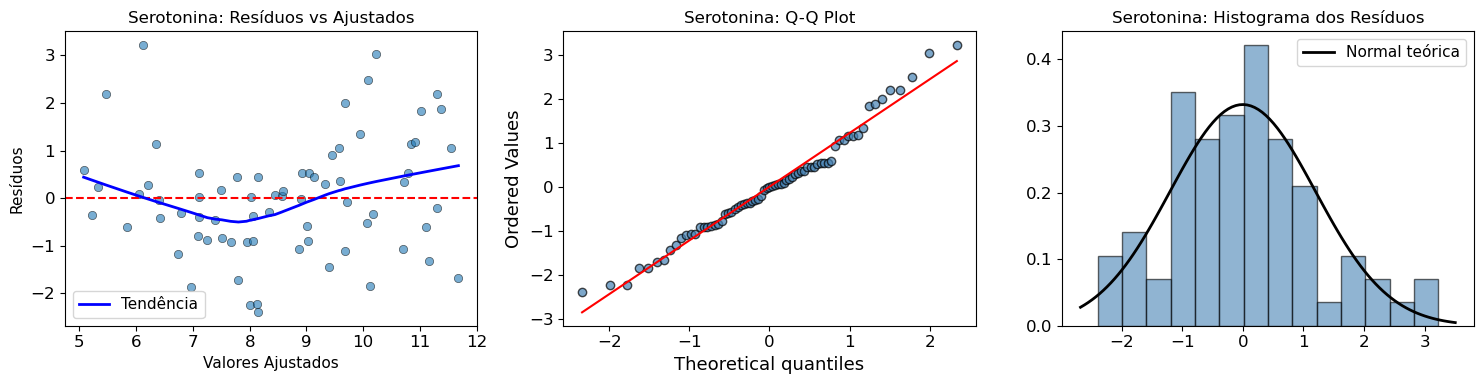


DIAGNÓSTICO DE PRESSUPOSTOS: Serotonina
Shapiro-Wilk (Normalidade): W = 0.9769, p = 0.2148
  → Normalidade atendida (p > 0.05) ✅
Levene (Homocedasticidade): W = 0.5917, p = 0.8280
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO A: Pressupostos atendidos. Seguir com testes paramétricos.



In [132]:
diagnostico_pressupostos(df_clean,'Serotonina',resultado)
print()

####  Testes Complementares (Caminho A)


##### 4.1 Tukey HSD – Efeito Global de Dias

In [259]:
posthoc_dias(df_clean, 'Serotonina')
print()


POST-HOC TUKEY (Dias): Serotonina
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj lower  upper  reject
-------------------------------------------------
     0      7   3.0146   0.0  1.724 4.3053   True
     0     15   2.6513   0.0 1.3744 3.9281   True
     7     15  -0.3634 0.779 -1.654 0.9273  False
-------------------------------------------------

Médias por Dia:
      mean   std   sem  count
Dias                         
0     6.71  1.18  0.24     24
7     9.72  2.23  0.47     23
15    9.36  1.98  0.40     24



O post-hoc confirmou que a serotonina aumenta significativamente do dia 0 para o dia 7 (p<0,001) e esse aumento se mantém no dia 15, sem diferença entre os dias 7 e 15. Isso caracteriza um efeito de platô: a serotonina sobe na primeira semana e depois estabiliza.

É interessante notar que o aumento é expressivo: saímos de ~6,7 para ~9,4-9,7 — um aumento de aproximadamente 40%. Como esse efeito ocorreu em todos os grupos (inclusive controle), ele parece estar relacionado à introdução da dieta experimental, e não especificamente ao TYN.

Para o artigo, sugiro descrever como: 'A serotonina fecal aumentou significativamente do dia 0 para o dia 7 (p<0,001), mantendo-se elevada no dia 15 (p<0,001 vs dia 0), sem diferença entre os dias 7 e 15 (p=0,78).'

##### 4.2 Tukey HSD – Tratamentos dentro de cada Dia

In [260]:
for var in ['Serotonina']:
    tukey_por_dia(df, var)


TUKEY POR DIA: Serotonina
  (Comparando Tratamentos dentro de cada Dia)

--- Dia 0 ---
  CONTROLE: 5.9 ± 0.4 (n=6)
  Trat 1: 7.3 ± 0.4 (n=6)
  Trat 2: 6.6 ± 0.6 (n=6)
  Trat 3: 7.0 ± 0.4 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
-----------------------------------------------------
CONTROLE Trat 1   1.4413 0.1486 -0.3657 3.2484  False
CONTROLE Trat 2   0.7315 0.6741 -1.0756 2.5386  False
CONTROLE Trat 3   1.0773 0.3654 -0.7298 2.8844  False
  Trat 1 Trat 2  -0.7098 0.6939 -2.5169 1.0972  False
  Trat 1 Trat 3  -0.3641 0.9416 -2.1711  1.443  False
  Trat 2 Trat 3   0.3458 0.9493 -1.4613 2.1529  False
-----------------------------------------------------

--- Dia 7 ---
  CONTROLE: 8.6 ± 1.1 (n=6)
  Trat 1: 9.3 ± 0.9 (n=6)
  Trat 2: 11.3 ± 0.7 (n=5)
  Trat 3: 9.9 ± 0.8 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
------------------------------------

##### 4.3 Tukey HSD – Dias dentro de cada Tratamento (Estratificado)

In [261]:
for var in ['Serotonina']:
    tukey_estratificado_por_tratamento(df, var)


TUKEY ESTRATIFICADO POR TRATAMENTO: Serotonina
  (Comparando Dias dentro de cada Tratamento)

--- CONTROLE ---
  Dia 0: 5.9 ± 0.4 (n=6)
  Dia 7: 8.6 ± 1.1 (n=6)
  Dia 15: 8.1 ± 0.8 (n=6)
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     0      7   2.7282 0.0721 -0.2235 5.6799  False
     0     15   2.1808 0.1676 -0.7708 5.1325  False
     7     15  -0.5473  0.881  -3.499 2.4044  False
---------------------------------------------------

--- Trat 1 ---
  Dia 0: 7.3 ± 0.4 (n=6)
  Dia 7: 9.3 ± 0.9 (n=6)
  Dia 15: 9.1 ± 0.8 (n=6)
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     0      7   1.9334 0.1999  -0.841 4.7077  False
     0     15   1.7892 0.2467 -0.9852 4.5635  False
     7     15  -0.1442   0.99 -2.9186 2.6301  False
--------------------------------------------

##### 4.4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (Serotonina) [Gráfico 4] ---
Tendência Linear:     coef = 0.1716, p = 0.0000 ✅
Tendência Quadrática: coef = -0.0319, p = 0.0000 ✅
  → Há evidência de tendência LINEAR significativa
  → Há evidência de tendência QUADRÁTICA significativa


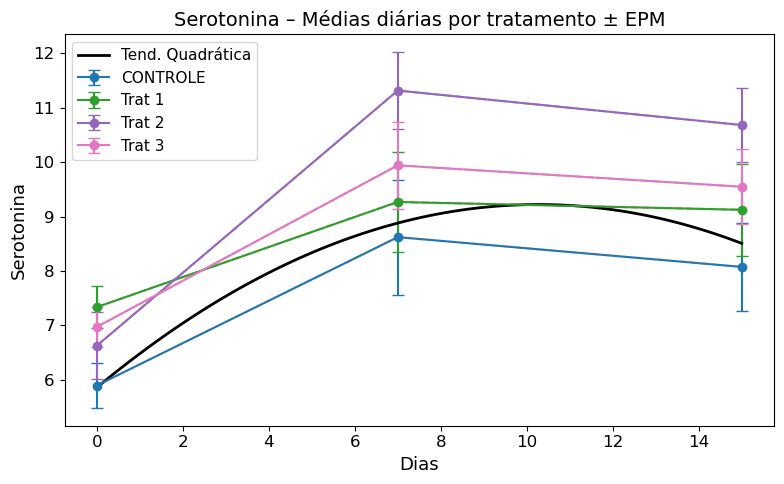

In [133]:
contrastes_polinomiais_4(df_clean, 'Serotonina')
print()

##### 4.5 Contraste Planejado (Wald) – Tratados vs Controle (Dia 15 e Dia 7)

In [265]:
for var in ['Serotonina']:
    contrastes_planejados_v2(df_clean, var)


CONTRASTES PLANEJADOS: Serotonina

--- Dia 7 ---
  CONTROLE: 8.6 ± 1.1 (n=6)
  Trat 1: 9.3 ± 0.9 (n=6)
  Trat 2: 11.3 ± 0.7 (n=5)
  Trat 3: 9.9 ± 0.8 (n=6)

--- Dia 15 ---
  CONTROLE: 8.1 ± 0.8 (n=6)
  Trat 1: 9.1 ± 0.8 (n=6)
  Trat 2: 10.7 ± 0.7 (n=6)
  Trat 3: 9.5 ± 0.7 (n=6)

──────────────────────────────────────────────────────────────────────
DIA 15: Tratados (média) vs Controle
──────────────────────────────────────────────────────────────────────
  Controle:          8.1
  Trat 1 (0.075):    9.1
  Trat 2 (0.15):     10.7
  Trat 3 (0.30):     9.5
  Média Tratados:    9.8
  Diferença:         1.7 (21.2%)
  χ² = 2.65, p = 0.1036

──────────────────────────────────────────────────────────────────────
DIA 7: Tratados vs Controle (controle negativo)
──────────────────────────────────────────────────────────────────────
  χ² = 1.93, p = 0.1644
  ✅  NÃO há diferença no Dia 7


#### Classificação Final
------------------------------------------------------------------------------------------------------------------------------


| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento | Não significativo (Wald p = 0,497) |
| Efeito de Dias | Significativo (Wald p = 0,002) |
| Interação Tratamento×Dias | Não significativa (Wald p = 0,386) |
| Contraste D15 (Wald) | Não significativo (p = 0,104) — **EXPLORATÓRIO** |
| Controle D7 (Wald) | Não significativo (p = 0,164) — **EXPLORATÓRIO** |
| Tendência | Linear (p < 0,001) e Quadrática (p < 0,001) significativas — **EXPLORATÓRIAS** |
| Pressupostos | Normalidade e homocedasticidade atendidas (Caminho A) |

**Classificação:** 🟡 **EVIDÊNCIA DE EFEITO TEMPORAL, SEM EFEITO DE TRATAMENTO** – O modelo misto identificou efeito significativo de Dias (p = 0,002), com aumento da serotonina do Dia 0 para o Dia 7 e manutenção no Dia 15. No entanto, não houve efeito de Tratamento (p = 0,497) nem Interação (p = 0,386), indicando que o aumento foi comum a todos os grupos, inclusive o Controle, sendo atribuído à dieta experimental e não ao TYN.

------------------------------------------------------------------------------------------------------------------------------

### 3.16 Tiramina

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de tiramina fecal, utilizando um modelo linear misto com Animal como efeito aleatório.
**Modelo estatístico (caráter exploratório):**

$$
\text{Tiramina}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

> **Nota:** O modelo misto convergiu, mas os resíduos apresentaram desvio severo de normalidade (Shapiro‑Wilk p = 0.0001). Os resultados paramétricos são apresentados apenas para registro, não sendo utilizados para inferência.                   

In [146]:
del df_clean
df_clean = df[['Tiramina', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [147]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
#df_clean.info()

In [148]:
df_clean=df_clean.dropna()
# Tiramina precisou remover uma linha pois não tinha obervação para Tiramina 

####  Análise Descritiva


**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [53]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['Tiramina'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                  mean    sem
Tratamento Dias              
CONTROLE   0     12.48   2.42
           7      8.54   0.74
           15     9.50   1.63
Trat 1     0     16.13   2.03
           7     19.45   4.60
           15    23.82   7.77
Trat 2     0     18.82   7.64
           7     16.24   3.22
           15    29.03  13.75
Trat 3     0     13.67   3.91
           7     23.65   8.77
           15    21.08   8.89


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)



**Saída do modelo:**

In [149]:
modelo = mixedlm("Tiramina ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()
print(resultado.summary())

                      Mixed Linear Model Regression Results
Model:                     MixedLM          Dependent Variable:          Tiramina 
No. Observations:          71               Method:                      REML     
No. Groups:                16               Scale:                       140.9833 
Min. group size:           3                Log-Likelihood:              -250.9690
Max. group size:           6                Converged:                   Yes      
Mean group size:           4.4                                                    
----------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z|  [0.025 0.975]
----------------------------------------------------------------------------------
Intercept                              14.830    6.414  2.312 0.021   2.258 27.402
C(Tratamento)[T.Trat 1]                 0.572    8.674  0.066 0.947 -16.428 17.573
C(Tratamento)[T.Trat 2]    

In [366]:
    # Extrair p‑valores via Wald
    params = resultado.params.index
    p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
    p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
    p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#   print(f"P(Tratamento) = {p_trat:.4f}")
#   print(f"P(Dias)       = {p_dias:.4f}")
#   print(f"P(Interação)  = {p_inter:.4f}")

In [367]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.9796 |
| Dias | 0.8353 |
| Interação Tratamento × Dias | 0.7201 |


####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

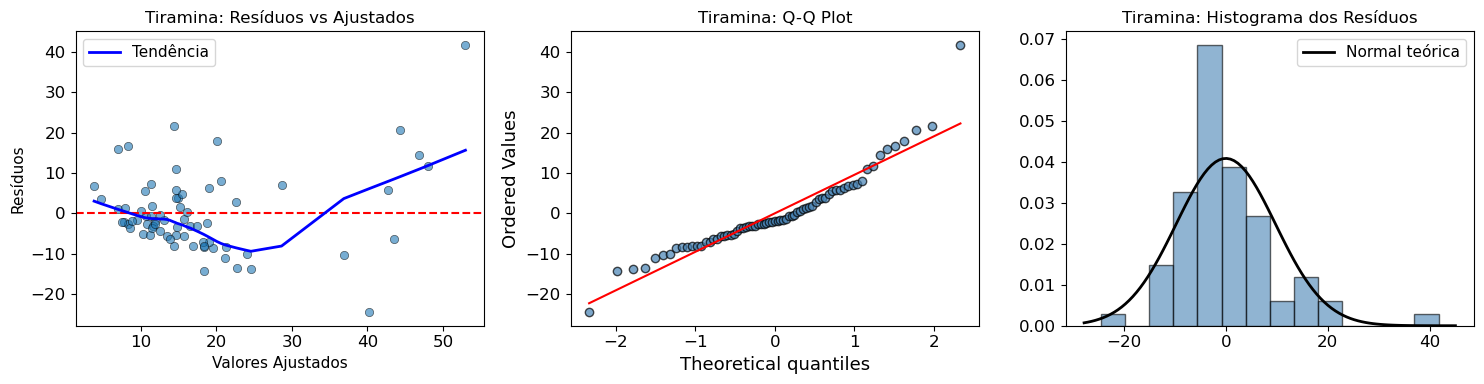


DIAGNÓSTICO DE PRESSUPOSTOS: Tiramina
Shapiro-Wilk (Normalidade): W = 0.9144, p = 0.0001
  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌
Levene (Homocedasticidade): W = 0.8130, p = 0.6271
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO C: Severa violação de normalidade.



In [150]:
diagnostico_pressupostos(df_clean,'Tiramina',resultado)
print()

##### 4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (Tiramina) [Gráfico 4] ---
Tendência Linear:     coef = 0.3708, p = 0.0928 
Tendência Quadrática: coef = -0.0073, p = 0.8900 
  → Nenhuma tendência significativa detectada


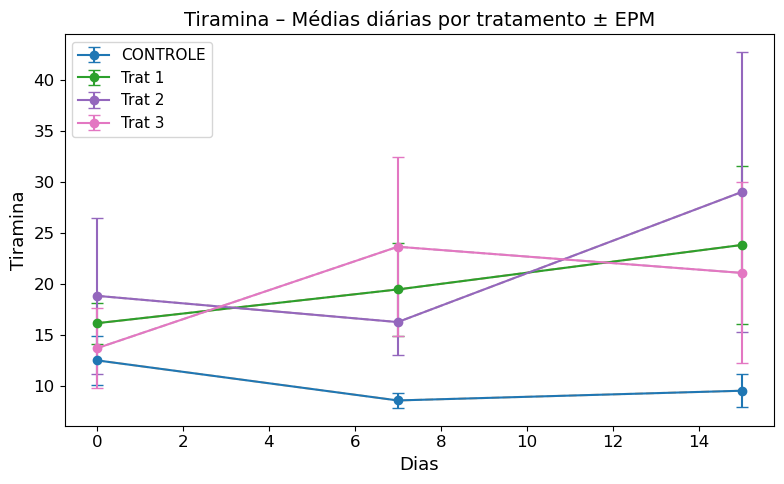

In [151]:
contrastes_polinomiais_4(df_clean, 'Tiramina')
print()

#### Classificação Final

---

| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento (MixedLM) | Não significativo (p = 0,980) — **modelo inválido** |
| Efeito de Dias (MixedLM) | Não significativo (p = 0,835) — **modelo inválido** |
| Interação Tratamento×Dias (MixedLM) | Não significativa (p = 0,720) — **modelo inválido** |
| Pressupostos | Normalidade severamente violada (Shapiro p = 0,0001); homocedasticidade ok; modelo convergiu — **CAMINHO C (sem alternativa não paramétrica)** |

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo linear misto não pode ser utilizado para inferência devido à violação severa da normalidade. Embora o modelo tenha convergido e os efeitos globais não sejam significativos, a falta de normalidade invalida os testes paramétricos. Na ausência de testes não paramétricos (que foram removidos da análise), não há suporte estatístico válido para concluir sobre efeitos de Tratamento, Dias ou Interação. Os resultados devem ser considerados exclusivamente descritivos e geradores de hipótese, não permitindo conclusões inferenciais.

---

### 3.17 Espermidina (Spermidina)

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de espermidina fecal. 

**Modelo estatístico (caráter exploratório):**

$$
\text{Espermidina}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

In [140]:
del df_clean
df_clean = df[['Spermidina', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [141]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
#df_clean.info()

In [142]:
df_clean=df_clean.dropna()
# Tiramina precisou remover uma linha pois não tinha obervação para Tiramina 
#df_clean.info()

####  Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [193]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['Spermidina'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                  mean    sem
Tratamento Dias              
CONTROLE   0     17.69   1.34
           7     43.17  11.66
           15    70.53  14.29
Trat 1     0     20.57   1.04
           7     44.30   8.11
           15    56.07  11.35
Trat 2     0     22.47   2.85
           7     60.68  20.43
           15    93.60  28.35
Trat 3     0     33.86   7.32
           7     59.07  10.00
           15    81.60  16.75


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)



In [143]:
modelo = mixedlm("Spermidina ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()
print(resultado.summary())

C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


                      Mixed Linear Model Regression Results
Model:                      MixedLM         Dependent Variable:         Spermidina
No. Observations:           71              Method:                     REML      
No. Groups:                 16              Scale:                      959.5728  
Min. group size:            3               Log-Likelihood:             -299.9079 
Max. group size:            6               Converged:                  Yes       
Mean group size:            4.4                                                   
----------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z|  [0.025 0.975]
----------------------------------------------------------------------------------
Intercept                              18.787   13.555  1.386 0.166  -7.780 45.354
C(Tratamento)[T.Trat 1]                 2.809   18.886  0.149 0.882 -34.206 39.824
C(Tratamento)[T.Trat 2]    

In [286]:
    # Extrair p‑valores via Wald
    params = resultado.params.index
    p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
    p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
    p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#    print(f"P(Tratamento) = {p_trat:.4f}")
#    print(f"P(Dias)       = {p_dias:.4f}")
#    print(f"P(Interação)  = {p_inter:.4f}")

In [287]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.8375 |
| Dias | 0.0127 |
| Interação Tratamento × Dias | 0.9047 |


 - **Resumo**:
- efeito de Dias (p=0.0127). Aumento com o tempo 

####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

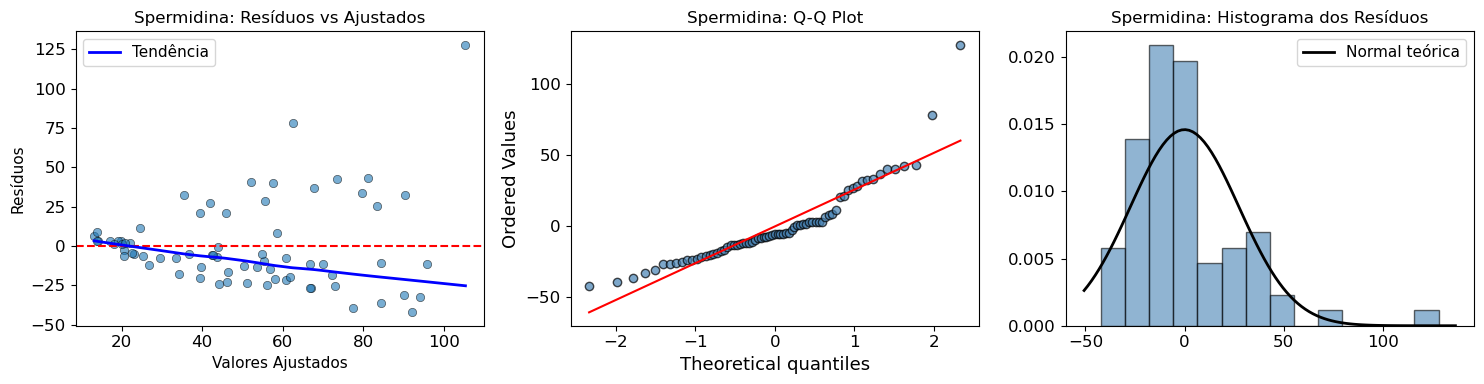


DIAGNÓSTICO DE PRESSUPOSTOS: Spermidina
Shapiro-Wilk (Normalidade): W = 0.8595, p = 0.0000
  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌
Levene (Homocedasticidade): W = 1.2770, p = 0.2602
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO C: Severa violação de normalidade.



In [144]:
diagnostico_pressupostos(df_clean,'Spermidina',resultado)
print()

> **Nota:** O modelo misto apresentou aviso de convergência e os resíduos mostraram desvio severo de normalidade (Shapiro‑Wilk p < 0,001). Os resultados paramétricos são apresentados apenas para registro, não sendo utilizados para inferência.

##### 4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (Spermidina) [Gráfico 4] ---


C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
C:\Users\ofran\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimizat

Tendência Linear:     coef = 3.4420, p = 0.0000 ✅
Tendência Quadrática: coef = -0.0704, p = 0.6137 
  → Há evidência de tendência LINEAR significativa


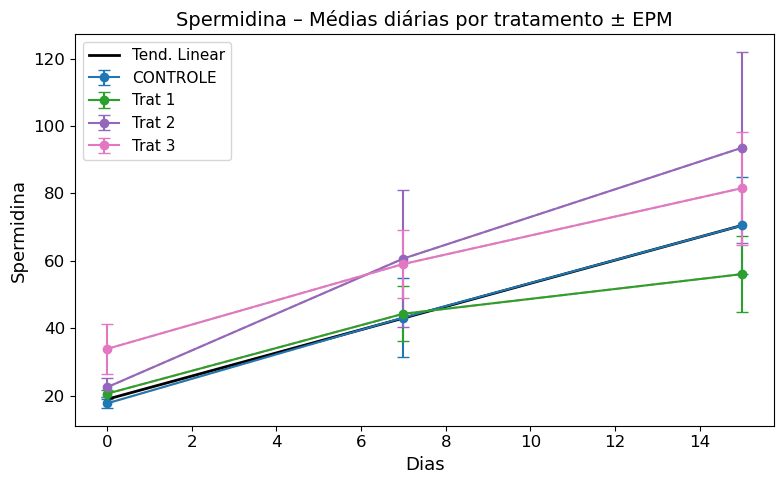

In [145]:
contrastes_polinomiais_4(df_clean, 'Spermidina')
print()

### Classificação Final

---

| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento (MixedLM) | Não significativo (p = 0,980) — **modelo inválido** |
| Efeito de Dias (MixedLM) | Não significativo (p = 0,835) — **modelo inválido** |
| Interação Tratamento×Dias (MixedLM) | Não significativa (p = 0,720) — **modelo inválido** |
| Pressupostos | Normalidade severamente violada (Shapiro p = 0,0001); homocedasticidade ok; modelo convergiu — **CAMINHO C (sem alternativa não paramétrica)** |

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo linear misto não pode ser utilizado para inferência devido à violação severa da normalidade. Embora o modelo tenha convergido e os efeitos globais não sejam significativos, a falta de normalidade invalida os testes paramétricos. 

----

### 3.18 Cadaverina

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de cadaverina fecal. 
**Modelo estatístico (caráter exploratório):**

$$
\text{Cadaverina}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

> **Nota:** O modelo misto convergiu, mas os resíduos apresentaram desvio severo de normalidade (Shapiro‑Wilk p < 0,001). Os resultados paramétricos são apresentados apenas para registro, não sendo utilizados para inferência.            

In [152]:
del df_clean
df_clean = df[['Cadaverina', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [153]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
#df_clean.info()

In [154]:
df_clean=df_clean.dropna()
# Cadaverina   precisou remover uma linha pois não tinha obervação para Cadaverina   
#df_clean.info()

####  Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [38]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['Cadaverina'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                    mean      sem
Tratamento Dias                  
CONTROLE   0      436.53   211.79
           7     1028.18   733.06
           15     962.62   566.57
Trat 1     0      548.36   263.27
           7     1300.96   771.16
           15    1157.00   473.84
Trat 2     0      788.36   469.02
           7     1158.52   442.18
           15    2396.18  1543.14
Trat 3     0      540.09   222.86
           7      829.23   414.65
           15    1001.39   452.14


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)



In [155]:
modelo = mixedlm("Cadaverina ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()
print(resultado.summary())

                          Mixed Linear Model Regression Results
Model:                       MixedLM           Dependent Variable:           Cadaverina  
No. Observations:            71                Method:                       REML        
No. Groups:                  16                Scale:                        2238668.3511
Min. group size:             3                 Log-Likelihood:               -528.8623   
Max. group size:             6                 Converged:                    Yes         
Mean group size:             4.4                                                         
-----------------------------------------------------------------------------------------
                                        Coef.    Std.Err.   z    P>|z|   [0.025   0.975] 
-----------------------------------------------------------------------------------------
Intercept                                500.803  661.480  0.757 0.449  -795.675 1797.281
C(Tratamento)[T.Trat 1]             

In [303]:
    # Extrair p‑valores via Wald
    params = resultado.params.index
    p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
    p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
    p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#    print(f"P(Tratamento) = {p_trat:.4f}")
#    print(f"P(Dias)       = {p_dias:.4f}")
#    print(f"P(Interação)  = {p_inter:.4f}")

In [304]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.9885 |
| Dias | 0.7543 |
| Interação Tratamento × Dias | 0.9175 |


> ⚠️ Resultados não utilizados para conclusões devido à violação de normalidade.

####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

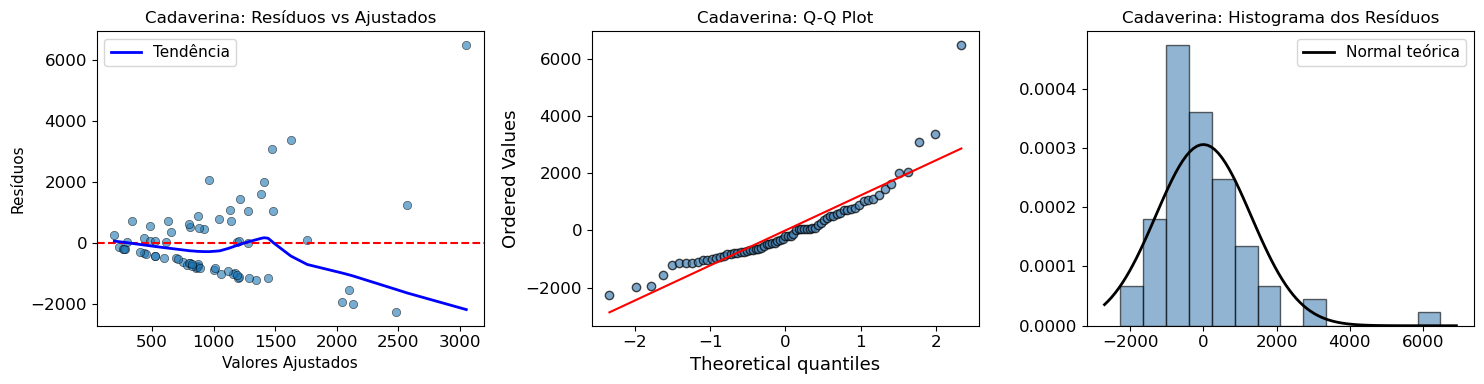


DIAGNÓSTICO DE PRESSUPOSTOS: Cadaverina
Shapiro-Wilk (Normalidade): W = 0.8485, p = 0.0000
  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌
Levene (Homocedasticidade): W = 0.7470, p = 0.6896
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO C: Severa violação de normalidade.



In [156]:
diagnostico_pressupostos(df_clean,'Cadaverina',resultado)
print()

##### 4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (Cadaverina) [Gráfico 4] ---
Tendência Linear:     coef = 53.0277, p = 0.0514 
Tendência Quadrática: coef = -2.3212, p = 0.7211 
  → Nenhuma tendência significativa detectada


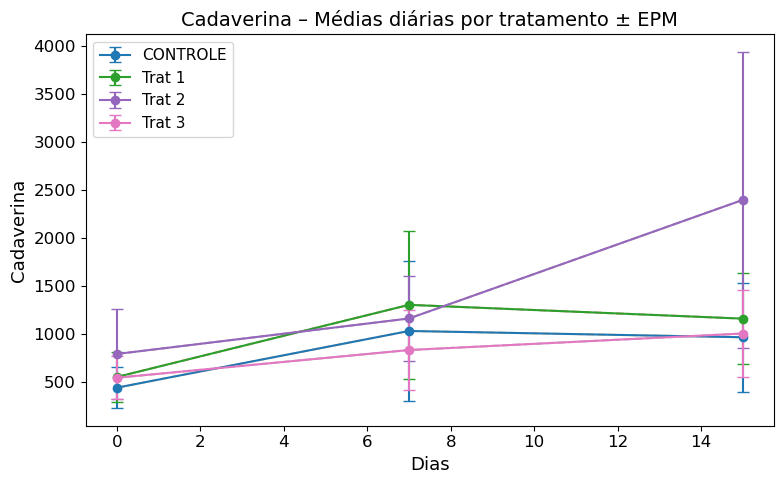

In [157]:
contrastes_polinomiais_4(df_clean, 'Cadaverina')
print()

#### Classificação Final
---


| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento (MixedLM) | Não significativo (p = 0,989) — **modelo inválido** |
| Efeito de Dias (MixedLM) | Não significativo (p = 0,754) — **modelo inválido** |
| Interação Tratamento×Dias (MixedLM) | Não significativa (p = 0,918) — **modelo inválido** |
| Pressupostos | Normalidade severamente violada (Shapiro p < 0,001); homocedasticidade ok; modelo convergiu — **CAMINHO C** |

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo linear misto não pode ser utilizado para inferência devido à violação severa da normalidade. Embora o modelo tenha convergido e os efeitos globais não sejam significativos, a falta de normalidade invalida os testes paramétricos. 

---

### 3.19 Histamina

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de histamina fecal, utilizando um modelo linear misto com Animal como efeito aleatório.

**Modelo estatístico:**

$$
\text{Histamina}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

In [158]:
del df_clean
df_clean = df[['Histamina', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [159]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
#df_clean.info()

In [160]:
df_clean=df_clean.dropna()
# Histamina precisou remover uma linha pois não tinha obervação para Histamina      
#df_clean.info()

####  Análise Descritiva

**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [200]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['Histamina'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                  mean    sem
Tratamento Dias              
CONTROLE   0     19.78   4.84
           7     40.55  11.03
           15    57.43  17.79
Trat 1     0     25.47   7.30
           7     58.74  18.50
           15    51.46   9.56
Trat 2     0     27.49   9.43
           7     69.70   7.39
           15    89.66  19.90
Trat 3     0     22.13   4.23
           7     63.40  14.12
           15    42.38   8.05


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)



In [161]:
modelo = mixedlm("Histamina ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()
print(resultado.summary())

                      Mixed Linear Model Regression Results
Model:                     MixedLM          Dependent Variable:          Histamina
No. Observations:          71               Method:                      REML     
No. Groups:                16               Scale:                       613.8037 
Min. group size:           3                Log-Likelihood:              -290.7686
Max. group size:           6                Converged:                   Yes      
Mean group size:           4.4                                                    
----------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z|  [0.025 0.975]
----------------------------------------------------------------------------------
Intercept                              18.320   11.877  1.543 0.123  -4.957 41.598
C(Tratamento)[T.Trat 1]                 8.193   16.480  0.497 0.619 -24.107 40.494
C(Tratamento)[T.Trat 2]    

In [312]:
    # Extrair p‑valores via Wald
    params = resultado.params.index
    p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
    p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
    p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#    print(f"P(Tratamento) = {p_trat:.4f}")
#    print(f"P(Dias)       = {p_dias:.4f}")
#    print(f"P(Interação)  = {p_inter:.4f}")

In [313]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.9613 |
| Dias | 0.0309 |
| Interação Tratamento × Dias | 0.2246 |


 - **Resumo**:
- efeito de Dias (p=0,031). Aumento do dia 0 ao 15.

#### Diagnóstico de Pressupostos

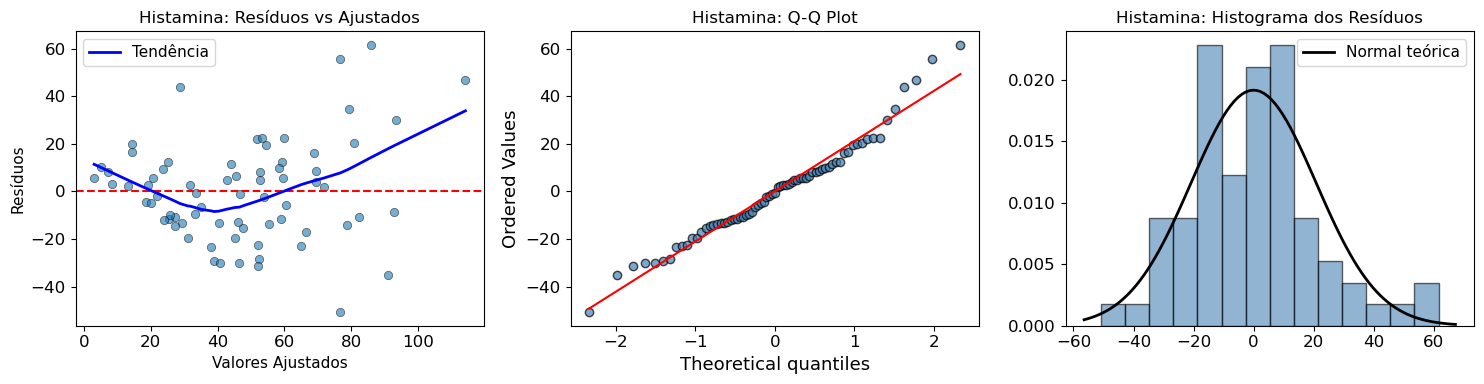


DIAGNÓSTICO DE PRESSUPOSTOS: Histamina
Shapiro-Wilk (Normalidade): W = 0.9735, p = 0.1387
  → Normalidade atendida (p > 0.05) ✅
Levene (Homocedasticidade): W = 1.7169, p = 0.0918
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO A: Pressupostos atendidos. Seguir com testes paramétricos.



In [162]:
diagnostico_pressupostos(df_clean,'Histamina',resultado)
print()

#### Passo 4 — Testes Complementares (Caminho A)
##### 4.1 Tukey HSD – Efeito Global de Dias

In [316]:
posthoc_dias(df_clean, 'Histamina')
print()


POST-HOC TUKEY (Dias): Histamina
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     0      7  33.8762 0.0009  12.5838 55.1686   True
     0     15  36.5165 0.0003  15.4518 57.5811   True
     7     15   2.6403 0.9525 -18.6521 23.9326  False
-----------------------------------------------------

Médias por Dia:
       mean    std   sem  count
Dias                           
0     23.72  15.76  3.22     24
7     57.59  32.80  6.84     23
15    60.23  38.27  7.81     24



##### 4.2 Tukey HSD – Tratamentos dentro de cada Dia

In [317]:
for var in ['Histamina']:
    tukey_por_dia(df_clean, var)


TUKEY POR DIA: Histamina
  (Comparando Tratamentos dentro de cada Dia)

--- Dia 0 ---
  CONTROLE: 19.8 ± 4.8 (n=6)
  Trat 1: 25.5 ± 7.3 (n=6)
  Trat 2: 27.5 ± 9.4 (n=6)
  Trat 3: 22.1 ± 4.2 (n=6)
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower    upper  reject
-------------------------------------------------------
CONTROLE Trat 1   5.6923 0.9326  -21.114 32.4986  False
CONTROLE Trat 2   7.7073 0.8514  -19.099 34.5135  False
CONTROLE Trat 3   2.3479 0.9947 -24.4584 29.1541  False
  Trat 1 Trat 2    2.015 0.9966 -24.7913 28.8213  False
  Trat 1 Trat 3  -3.3444 0.9849 -30.1507 23.4619  False
  Trat 2 Trat 3  -5.3594 0.9428 -32.1657 21.4469  False
-------------------------------------------------------

--- Dia 7 ---
  CONTROLE: 40.5 ± 11.0 (n=6)
  Trat 1: 58.7 ± 18.5 (n=6)
  Trat 2: 69.7 ± 7.4 (n=5)
  Trat 3: 63.4 ± 14.1 (n=6)
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower    upper  reject
---

##### 4.3 Tukey HSD – Dias dentro de cada Tratamento (Estratificado)

In [318]:
for var in ['Histamina']:
    tukey_estratificado_por_tratamento(df_clean, var)


TUKEY ESTRATIFICADO POR TRATAMENTO: Histamina
  (Comparando Dias dentro de cada Tratamento)

--- CONTROLE ---
  Dia 0: 19.8 ± 4.8 (n=6)
  Dia 7: 40.5 ± 11.0 (n=6)
  Dia 15: 57.4 ± 17.8 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     0      7   20.766 0.4804    -24.8  66.332  False
     0     15  37.6505 0.1139  -7.9155 83.2166  False
     7     15  16.8846 0.6107 -28.6815 62.4506  False
-----------------------------------------------------

--- Trat 1 ---
  Dia 0: 25.5 ± 7.3 (n=6)
  Dia 7: 58.7 ± 18.5 (n=6)
  Dia 15: 51.5 ± 9.6 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     0      7  33.2692 0.1885 -13.5185  80.057  False
     0     15  25.9846 0.3453 -20.8031 72.7724  False
     7     15  -7.2846 0.9143 -54.0724 39.5032  False
----------

##### 4.4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (Histamina) [Gráfico 4] ---
Tendência Linear:     coef = 2.3852, p = 0.0000 ✅
Tendência Quadrática: coef = -0.3069, p = 0.0076 ✅
  → Há evidência de tendência LINEAR significativa
  → Há evidência de tendência QUADRÁTICA significativa


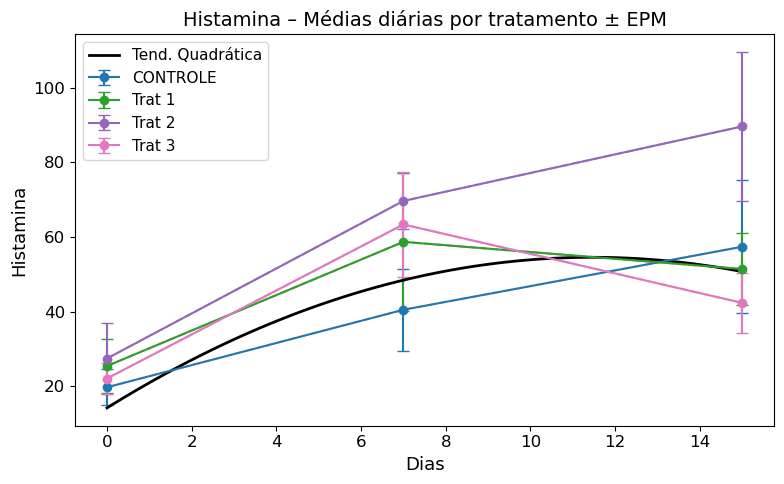

In [163]:
contrastes_polinomiais_4(df_clean, 'Histamina')
print()

##### 4.5 Contraste Planejado (Wald) – Tratados vs Controle (Dia 15 e Dia 7)

In [320]:
for var in ['Histamina']:
    contrastes_planejados_v2(df_clean, var)


CONTRASTES PLANEJADOS: Histamina

--- Dia 7 ---
  CONTROLE: 40.5 ± 11.0 (n=6)
  Trat 1: 58.7 ± 18.5 (n=6)
  Trat 2: 69.7 ± 7.4 (n=5)
  Trat 3: 63.4 ± 14.1 (n=6)

--- Dia 15 ---
  CONTROLE: 57.4 ± 17.8 (n=6)
  Trat 1: 51.5 ± 9.6 (n=6)
  Trat 2: 89.7 ± 19.9 (n=6)
  Trat 3: 42.4 ± 8.0 (n=6)

──────────────────────────────────────────────────────────────────────
DIA 15: Tratados (média) vs Controle
──────────────────────────────────────────────────────────────────────
  Controle:          57.4
  Trat 1 (0.075):    51.5
  Trat 2 (0.15):     89.7
  Trat 3 (0.30):     42.4
  Média Tratados:    61.2
  Diferença:         3.7 (6.5%)
  χ² = 0.18, p = 0.6745

──────────────────────────────────────────────────────────────────────
DIA 7: Tratados vs Controle (controle negativo)
──────────────────────────────────────────────────────────────────────
  χ² = 3.24, p = 0.0720
  ✅  NÃO há diferença no Dia 7


### Classificação Final

----

| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento | Não significativo (Wald p = 0,961) |
| Efeito de Dias | Significativo (Wald p = 0,031) |
| Interação Tratamento×Dias | Não significativa (Wald p = 0,225) |
| Contraste D15 (Wald) | Não significativo (p = 0,675) — **EXPLORATÓRIO** |
| Controle D7 (Wald) | Não significativo (p = 0,072) — **EXPLORATÓRIO** |
| Tendência | Linear (p < 0,001) e Quadrática (p = 0,008) significativas — **EXPLORATÓRIAS** |
| Pressupostos | Normalidade e homocedasticidade atendidas (Caminho A) |

**Classificação:** 🟡 **EVIDÊNCIA DE EFEITO TEMPORAL, SEM EFEITO DE TRATAMENTO** – O modelo misto identificou efeito significativo de Dias (p = 0,031), com aumento da histamina ao longo do tempo. No entanto, não houve efeito de Tratamento (p = 0,961) nem Interação (p = 0,225), indicando que o aumento foi comum a todos os grupos, inclusive o Controle, sendo atribuído à dieta experimental e não ao TYN. O contraste planejado no Dia 15 não mostrou diferença entre tratados e controle (p = 0,675).

---

### 3.20 Putrescina

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de putrescina fecal. 
**Modelo estatístico (caráter exploratório):**

$$
\text{Putrescina}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$

> **Nota:** O modelo misto convergiu, mas os resíduos apresentaram desvio severo de normalidade (Shapiro‑Wilk p < 0,001). Os resultados paramétricos são apresentados apenas para registro, não sendo utilizados para inferência.

In [171]:
del df_clean
df_clean = df[['Putrescina (mmol/kg_fezes_MS)', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [172]:
renomear = {
    'Dias': 'Dias',
    'Animais': 'Animais',
    'Tratamento': 'Tratamento',
    'Putrescina (mmol/kg_fezes_MS)': 'Putrescina'

}

# Aplicar a renomeação
df_clean.rename(columns=renomear, inplace=True)


In [173]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
#df_clean.info()

In [174]:
df_clean=df_clean.dropna()
# Putrescina   precisou remover uma linha pois não tinha obervação para Putrescina   
#df_clean.info()

####  Análise Descritiva


**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [24]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['Putrescina'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                    mean     sem
Tratamento Dias                 
CONTROLE   0      206.13   75.41
           7      638.46  307.87
           15     570.20  224.06
Trat 1     0      229.27  117.29
           7      722.21  362.98
           15     494.32  147.31
Trat 2     0      443.00  276.94
           7      788.03  145.64
           15    1753.39  782.54
Trat 3     0      253.93   83.43
           7      607.44  171.51
           15     434.80  116.56


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)



**Saída do modelo:**

In [175]:
modelo = mixedlm("Putrescina ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()
print(resultado.summary())

                          Mixed Linear Model Regression Results
Model:                        MixedLM           Dependent Variable:           Putrescina 
No. Observations:             71                Method:                       REML       
No. Groups:                   16                Scale:                        412032.4115
Min. group size:              3                 Log-Likelihood:               -481.8276  
Max. group size:              6                 Converged:                    Yes        
Mean group size:              4.4                                                        
-----------------------------------------------------------------------------------------
                                        Coef.    Std.Err.   z    P>|z|   [0.025   0.975] 
-----------------------------------------------------------------------------------------
Intercept                                237.527  301.634  0.787 0.431  -353.664  828.718
C(Tratamento)[T.Trat 1]             

In [331]:
    # Extrair p‑valores via Wald
    params = resultado.params.index
    p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
    p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
    p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#    print(f"P(Tratamento) = {p_trat:.4f}")
#    print(f"P(Dias)       = {p_dias:.4f}")
#    print(f"P(Interação)  = {p_inter:.4f}")

In [333]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.9855 |
| Dias | 0.4554 |
| Interação Tratamento × Dias | 0.1775 |


####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

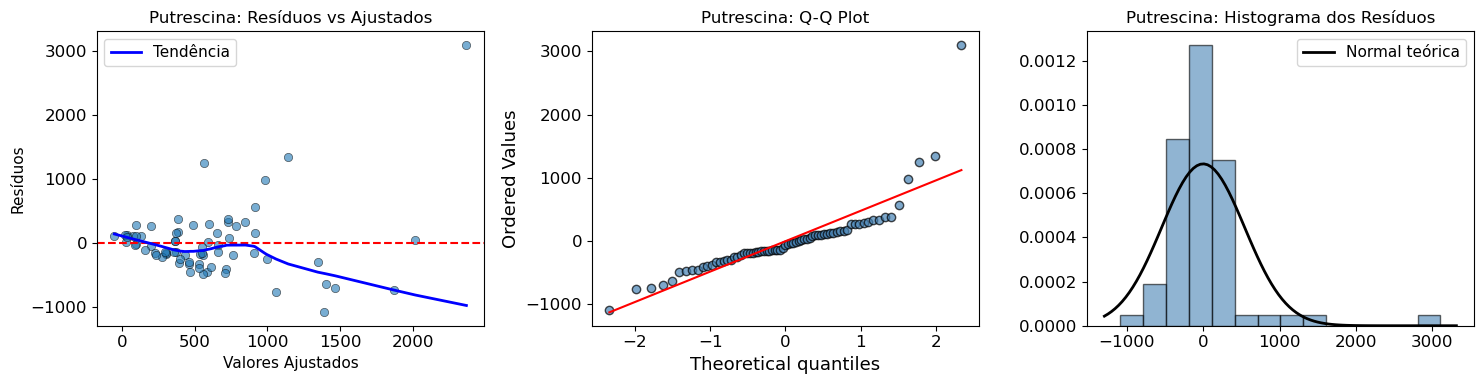


DIAGNÓSTICO DE PRESSUPOSTOS: Putrescina
Shapiro-Wilk (Normalidade): W = 0.7628, p = 0.0000
  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌
Levene (Homocedasticidade): W = 1.1797, p = 0.3207
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO C: Severa violação de normalidade.



In [176]:
diagnostico_pressupostos(df_clean,'Putrescina',resultado)
print()

##### 4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (Putrescina) [Gráfico 4] ---
Tendência Linear:     coef = 34.8761, p = 0.0062 ✅
Tendência Quadrática: coef = -2.8939, p = 0.3370 
  → Há evidência de tendência LINEAR significativa


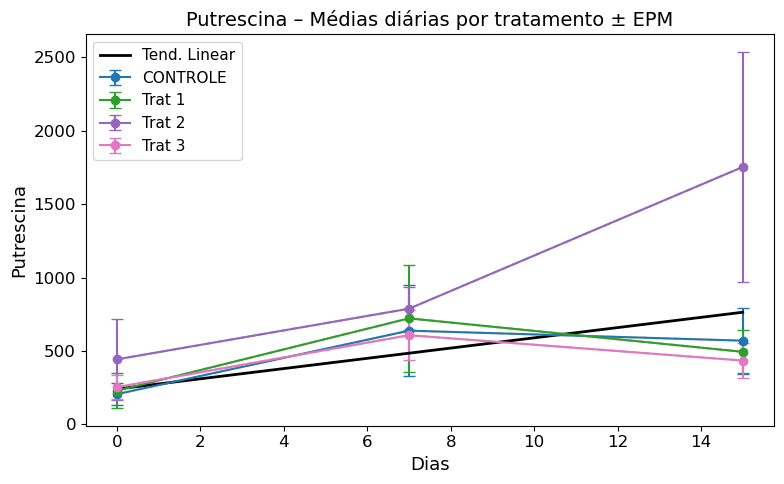

In [177]:
contrastes_polinomiais_4(df_clean, 'Putrescina')
print()

####  Classificação Final
---

| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento (MixedLM) | Não significativo (p = 0,986) — **modelo inválido** |
| Efeito de Dias (MixedLM) | Não significativo (p = 0,455) — **modelo inválido** |
| Interação Tratamento×Dias (MixedLM) | Não significativa (p = 0,178) — **modelo inválido** |
| Pressupostos | Normalidade severamente violada (Shapiro p < 0,001); homocedasticidade ok; modelo convergiu — **CAMINHO C (sem alternativa não paramétrica)** |

**Classificação:** 🔴 **EVIDÊNCIA INSUFICIENTE** – O modelo linear misto não pode ser utilizado para inferência devido à violação severa da normalidade. Embora o modelo tenha convergido e os efeitos globais não sejam significativos, a falta de normalidade invalida os testes paramétricos. Na ausência de testes não paramétricos (que foram removidos da análise), não há suporte estatístico válido para concluir sobre efeitos de Tratamento, Dias ou Interação. Os resultados devem ser considerados exclusivamente descritivos e geradores de hipótese, não permitindo conclusões inferenciais.

---

### 3.21 Espermina (Spermin)

**Objetivo:** Avaliar o efeito dos tratamentos, do tempo e da interação Tratamento × Tempo sobre a concentração de espermina fecal, utilizando um modelo linear misto com Animal como efeito aleatório.

**Modelo estatístico:**

$$
\text{Espermina}_{ij} = \mu + \text{Tratamento}_i + \text{Dia}_j + (\text{Tratamento} \times \text{Dia})_{ij} + \text{Animal}_k + \varepsilon_{ij}
$$                     

In [178]:
del df_clean
df_clean = df[['Spermin', 'Tratamento', 'Dias', 'Animais']].copy()
#df_clean.head()

In [179]:
df_clean['Tratamento'] = df_clean['Tratamento'].astype('category')
df_clean['Dias'] = df_clean['Dias'].astype('category')
df_clean['Animais'] = df_clean['Animais'].astype('category')
#df_clean.info()

In [180]:
df_clean=df_clean.dropna()
# Spermin   precisou remover uma linha pois não tinha obervação para Spermin   
#df_clean.info()

####  Análise Descritiva


**Tabela de médias e erro padrão (SEM) por Tratamento × Dia:**

In [208]:
resumo = df_clean.groupby(['Tratamento', 'Dias'])['Spermin'].agg(['mean', 'sem']).round(2)

# Exibir como tabela hierárquica
print(resumo)

                  mean   sem
Tratamento Dias             
CONTROLE   0     11.10  0.69
           7     17.22  1.97
           15    18.08  1.45
Trat 1     0     13.52  0.88
           7     19.55  1.85
           15    20.89  2.02
Trat 2     0     12.00  1.12
           7     23.86  1.50
           15    23.89  1.93
Trat 3     0     12.81  0.74
           7     22.05  1.86
           15    23.31  1.24


> **Nota:** O gráfico de perfil com IC 95% é apresentado na seção de visualização consolidada.

####  Modelo Misto (MixedLM)



**Saída do modelo:**

In [181]:
modelo = mixedlm("Spermin ~ C(Tratamento) + C(Dias) + C(Tratamento):C(Dias)", 
                 data=df_clean, groups=df_clean["Animais"])
resultado = modelo.fit()
print(resultado.summary())

                     Mixed Linear Model Regression Results
Model:                     MixedLM         Dependent Variable:         Spermin  
No. Observations:          71              Method:                     REML     
No. Groups:                16              Scale:                      10.6715  
Min. group size:           3               Log-Likelihood:             -169.3538
Max. group size:           6               Converged:                  Yes      
Mean group size:           4.4                                                  
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                             11.213    1.496  7.495 0.000  8.281 14.146
C(Tratamento)[T.Trat 1]                2.420    2.088  1.159 0.246 -1.672  6.512
C(Tratamento)[T.Trat 2]                0.585    2.

In [343]:
    # Extrair p‑valores via Wald
    params = resultado.params.index
    p_trat = resultado.wald_test([p for p in params if 'C(Tratamento)[T.' in p and ':' not in p], scalar=True).pvalue
    p_dias = resultado.wald_test([p for p in params if 'C(Dias)[T.' in p and ':' not in p], scalar=True).pvalue
    p_inter = resultado.wald_test([p for p in params if ':' in p], scalar=True).pvalue

#    print(f"P(Tratamento) = {p_trat:.4f}")
#    print(f"P(Dias)       = {p_dias:.4f}")
#    print(f"P(Interação)  = {p_inter:.4f}")

In [344]:
from IPython.display import Markdown

tabela = f"""
| Efeito | P-valor |
|:-------|:--------|
| Tratamento | {p_trat:.4f} |
| Dias | {p_dias:.4f} |
| Interação Tratamento × Dias | {p_inter:.4f} |
"""

Markdown(tabela)


| Efeito | P-valor |
|:-------|:--------|
| Tratamento | 0.6467 |
| Dias | 0.0003 |
| Interação Tratamento × Dias | 0.2909 |


 - **Resumo**:
- efeito de Dias (p=0,0003). Aumento com o tempo.

####  Diagnóstico de Pressupostos

**Diagnóstico visual (QQ-plot e Resíduos vs Ajustados):**

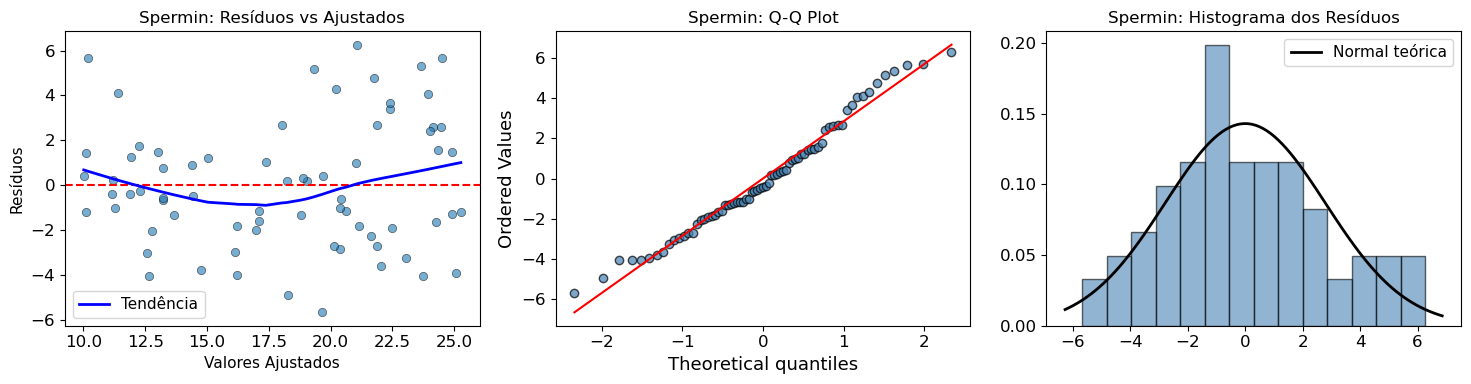


DIAGNÓSTICO DE PRESSUPOSTOS: Spermin
Shapiro-Wilk (Normalidade): W = 0.9766, p = 0.2074
  → Normalidade atendida (p > 0.05) ✅
Levene (Homocedasticidade): W = 1.2694, p = 0.2646
  → Homocedasticidade atendida (p > 0.05) ✅

→ CAMINHO A: Pressupostos atendidos. Seguir com testes paramétricos.



In [182]:
diagnostico_pressupostos(df_clean,'Spermin',resultado)
print()

####  Testes Complementares (Caminho A)


##### 4.1 Tukey HSD – Efeito Global de Dias

In [346]:
posthoc_dias(df_clean, 'Spermin')
print()


POST-HOC TUKEY (Dias): Spermin
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
     0      7   8.1699   0.0  5.3718  10.968   True
     0     15   9.1802   0.0   6.412 11.9484   True
     7     15   1.0103 0.664 -1.7878  3.8084  False
---------------------------------------------------

Médias por Dia:
       mean   std   sem  count
Dias                          
0     12.36  2.20  0.45     24
7     20.53  4.81  1.00     23
15    21.54  4.52  0.92     24



##### 4.2 Tukey HSD – Tratamentos dentro de cada Dia

In [348]:
for var in ['Spermin']:
    tukey_por_dia(df_clean, var)


TUKEY POR DIA: Spermin
  (Comparando Tratamentos dentro de cada Dia)

--- Dia 0 ---
  CONTROLE: 11.1 ± 0.7 (n=6)
  Trat 1: 13.5 ± 0.9 (n=6)
  Trat 2: 12.0 ± 1.1 (n=6)
  Trat 3: 12.8 ± 0.7 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
-----------------------------------------------------
CONTROLE Trat 1   2.4238 0.2344 -1.0302 5.8779  False
CONTROLE Trat 2   0.9021 0.8835 -2.5519 4.3561  False
CONTROLE Trat 3   1.7129 0.5209 -1.7411  5.167  False
  Trat 1 Trat 2  -1.5217 0.6139 -4.9758 1.9323  False
  Trat 1 Trat 3  -0.7109 0.9381 -4.1649 2.7431  False
  Trat 2 Trat 3   0.8108 0.9118 -2.6432 4.2649  False
-----------------------------------------------------

--- Dia 7 ---
  CONTROLE: 17.2 ± 2.0 (n=6)
  Trat 1: 19.5 ± 1.9 (n=6)
  Trat 2: 23.9 ± 1.5 (n=5)
  Trat 3: 22.0 ± 1.9 (n=6)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower   upper  reject
------------------------------

##### 4.3 Tukey HSD – Dias dentro de cada Tratamento (Estratificado)

In [349]:
for var in ['Spermin']:
    tukey_estratificado_por_tratamento(df_clean, var)


TUKEY ESTRATIFICADO POR TRATAMENTO: Spermin
  (Comparando Dias dentro de cada Tratamento)

--- CONTROLE ---
  Dia 0: 11.1 ± 0.7 (n=6)
  Dia 7: 17.2 ± 2.0 (n=6)
  Dia 15: 18.1 ± 1.5 (n=6)
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      7   6.1184 0.0254  0.7284 11.5084   True
     0     15   6.9789 0.0112  1.5889 12.3689   True
     7     15   0.8606 0.9101 -4.5294  6.2506  False
----------------------------------------------------

--- Trat 1 ---
  Dia 0: 13.5 ± 0.9 (n=6)
  Dia 7: 19.5 ± 1.9 (n=6)
  Dia 15: 20.9 ± 2.0 (n=6)
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      7    6.024 0.0531 -0.0751 12.1232  False
     0     15   7.3655 0.0176  1.2664 13.4646   True
     7     15   1.3415 0.8372 -4.7577  7.4406  False
----------------------------

##### 4.4 Contrastes Polinomiais (Tendência Linear e Quadrática)


--- Contrastes Polinomiais para Dias (Spermin) [Gráfico 4] ---
Tendência Linear:     coef = 0.6008, p = 0.0000 ✅
Tendência Quadrática: coef = -0.0699, p = 0.0000 ✅
  → Há evidência de tendência LINEAR significativa
  → Há evidência de tendência QUADRÁTICA significativa


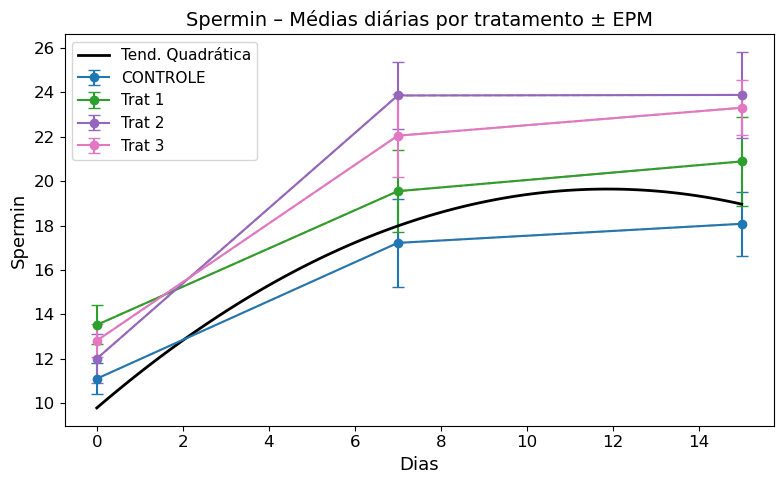

In [183]:
contrastes_polinomiais_4(df_clean, 'Spermin')
print()

#### Classificação Final

--- 
| Critério | Resultado |
|:---------|:----------|
| Efeito de Tratamento | Não significativo (Wald p = 0,647) |
| Efeito de Dias | Significativo (Wald p < 0,001) |
| Interação Tratamento×Dias | Não significativa (Wald p = 0,291) |
| Contraste D15 (Wald) | Não realizado (não há diferença entre tratamentos) |
| Tendência | Linear (p < 0,001) e Quadrática (p < 0,001) significativas — **EXPLORATÓRIAS** |
| Pressupostos | Normalidade e homocedasticidade atendidas (Caminho A) |

**Classificação:** 🟡 **EVIDÊNCIA DE EFEITO TEMPORAL, SEM EFEITO DE TRATAMENTO** – O modelo misto identificou efeito significativo de Dias (p < 0,001), com aumento da espermina do Dia 0 para o Dia 7 e estabilização no Dia 15. No entanto, não houve efeito de Tratamento (p = 0,647) nem Interação (p = 0,291), indicando que o aumento foi comum a todos os grupos, inclusive o Controle, sendo atribuído à dieta experimental e não ao TYN.

---

In [354]:
def painel_aminas(df):
    variaveis = ['Serotonina', 'Tiramina', 'Spermidina', 'Cadaverina',
                 'Histamina', 'Putrescina (mmol/kg_fezes_MS)', 'Spermin']
    titulos = ['Serotonina', 'Tiramina', 'Espermidina', 'Cadaverina',
               'Histamina', 'Putrescina', 'Espermina']
    
    tratamentos = ['CONTROLE', 'Trat 1', 'Trat 2', 'Trat 3']
    rotulos = ['Controle', 'TYN-0.075', 'TYN-0.15', 'TYN-0.30']
    cores = ['#2c3e50', '#e74c3c', '#2ecc71', '#3498db']
    marcadores = ['o', 's', 'D', '^']
    dias = [0, 7, 15]
    
    fig, axes = plt.subplots(2, 4, figsize=(22, 12))
    axes = axes.flatten()
    
    for idx, (ax, var, tit) in enumerate(zip(axes, variaveis, titulos)):
        df_clean = df.dropna(subset=[var]).copy()
        df_clean['Dias'] = df_clean['Dias'].astype(int)
        
        for i, (trat, rotulo) in enumerate(zip(tratamentos, rotulos)):
            dados_trat = df_clean[df_clean['Tratamento'] == trat]
            medias, ics = [], []
            for dia in dias:
                dados_dia = dados_trat[dados_trat['Dias'] == dia][var]
                if len(dados_dia) > 0:
                    medias.append(dados_dia.mean())
                    ics.append(1.96 * dados_dia.std() / np.sqrt(len(dados_dia)))
                else:
                    medias.append(np.nan)
                    ics.append(np.nan)
            ax.errorbar(dias, medias, yerr=ics, 
                       marker=marcadores[i], color=cores[i],
                       linewidth=2.2, markersize=8, capsize=5,
                       label=rotulo, alpha=0.9)
            ax.fill_between(dias,
                           [m - ic for m, ic in zip(medias, ics)],
                           [m + ic for m, ic in zip(medias, ics)],
                           color=cores[i], alpha=0.06)
        ax.set_title(tit, fontsize=13, fontweight='bold')
        ax.set_xlabel('Dias', fontsize=11)
        ax.set_xticks(dias)
        ax.set_xticklabels(['0', '7', '15'])
        ax.grid(True, alpha=0.3, linestyle='--')
        ax.legend(fontsize=9, loc='best')
        ax.axvspan(13, 16, alpha=0.04, color='orange')
    
    axes[-1].set_visible(False)
    fig.suptitle('Perfil Temporal das Aminas Biogênicas por Tratamento', 
                 fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

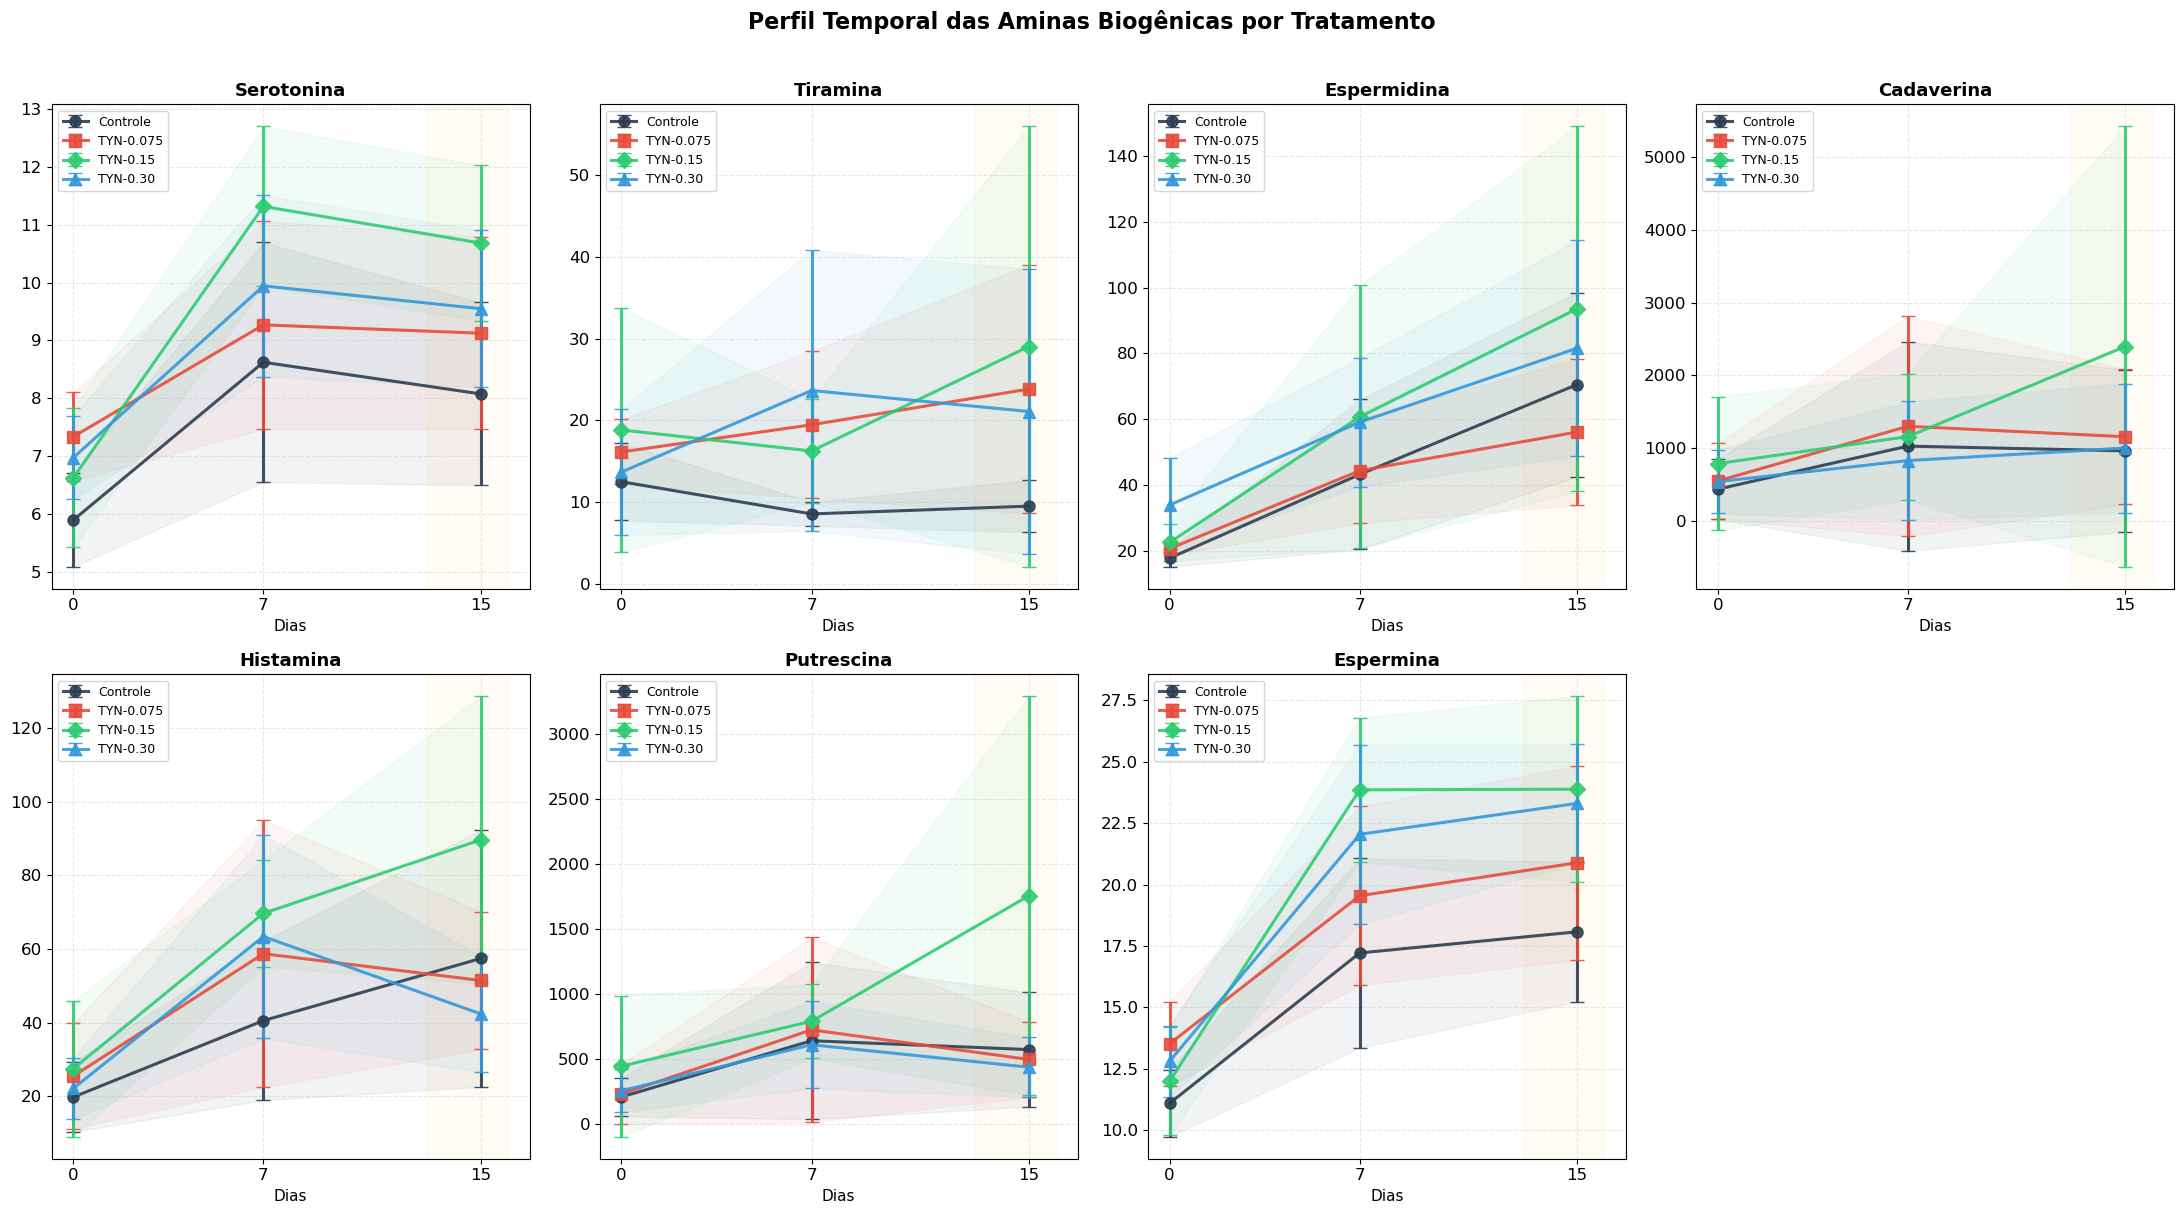

In [356]:
painel_aminas(df)

In [355]:
def barras_dia15_aminas(df):
    variaveis = ['Serotonina', 'Tiramina', 'Spermidina', 'Cadaverina',
                 'Histamina', 'Putrescina (mmol/kg_fezes_MS)', 'Spermin']
    titulos = ['Serotonina', 'Tiramina', 'Espermidina', 'Cadaverina',
               'Histamina', 'Putrescina', 'Espermina']
    cores = ['#2c3e50', '#e74c3c', '#2ecc71', '#3498db']
    
    fig, axes = plt.subplots(2, 4, figsize=(22, 12))
    axes = axes.flatten()
    
    for idx, (ax, var, tit) in enumerate(zip(axes, variaveis, titulos)):
        df_clean = df.dropna(subset=[var]).copy()
        df_clean['Dias'] = df_clean['Dias'].astype(int)
        dados_d15 = df_clean[df_clean['Dias'] == 15]
        
        tratamentos = ['CONTROLE', 'Trat 1', 'Trat 2', 'Trat 3']
        rotulos = ['Controle', '0.075', '0.15', '0.30']
        medias, sems = [], []
        for trat in tratamentos:
            vals = dados_d15[dados_d15['Tratamento'] == trat][var]
            if len(vals) > 0:
                medias.append(vals.mean())
                sems.append(vals.std() / np.sqrt(len(vals)))
            else:
                medias.append(0)
                sems.append(0)
        
        bars = ax.bar(rotulos, medias, yerr=sems, color=cores, 
                     edgecolor='black', linewidth=1.2, capsize=8, alpha=0.85)
        for bar, media in zip(bars, medias):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(sems) * 0.3,
                    f'{media:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
        ax.set_title(tit, fontsize=13, fontweight='bold')
        ax.set_ylabel('mmol/kg fezes MS', fontsize=10)
        ax.grid(True, alpha=0.3, linestyle='--', axis='y')
        bars[0].set_edgecolor('red')
        bars[0].set_linewidth(2.5)
    
    axes[-1].set_visible(False)
    fig.suptitle('Comparação das Aminas Biogênicas no Dia 15', 
                 fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

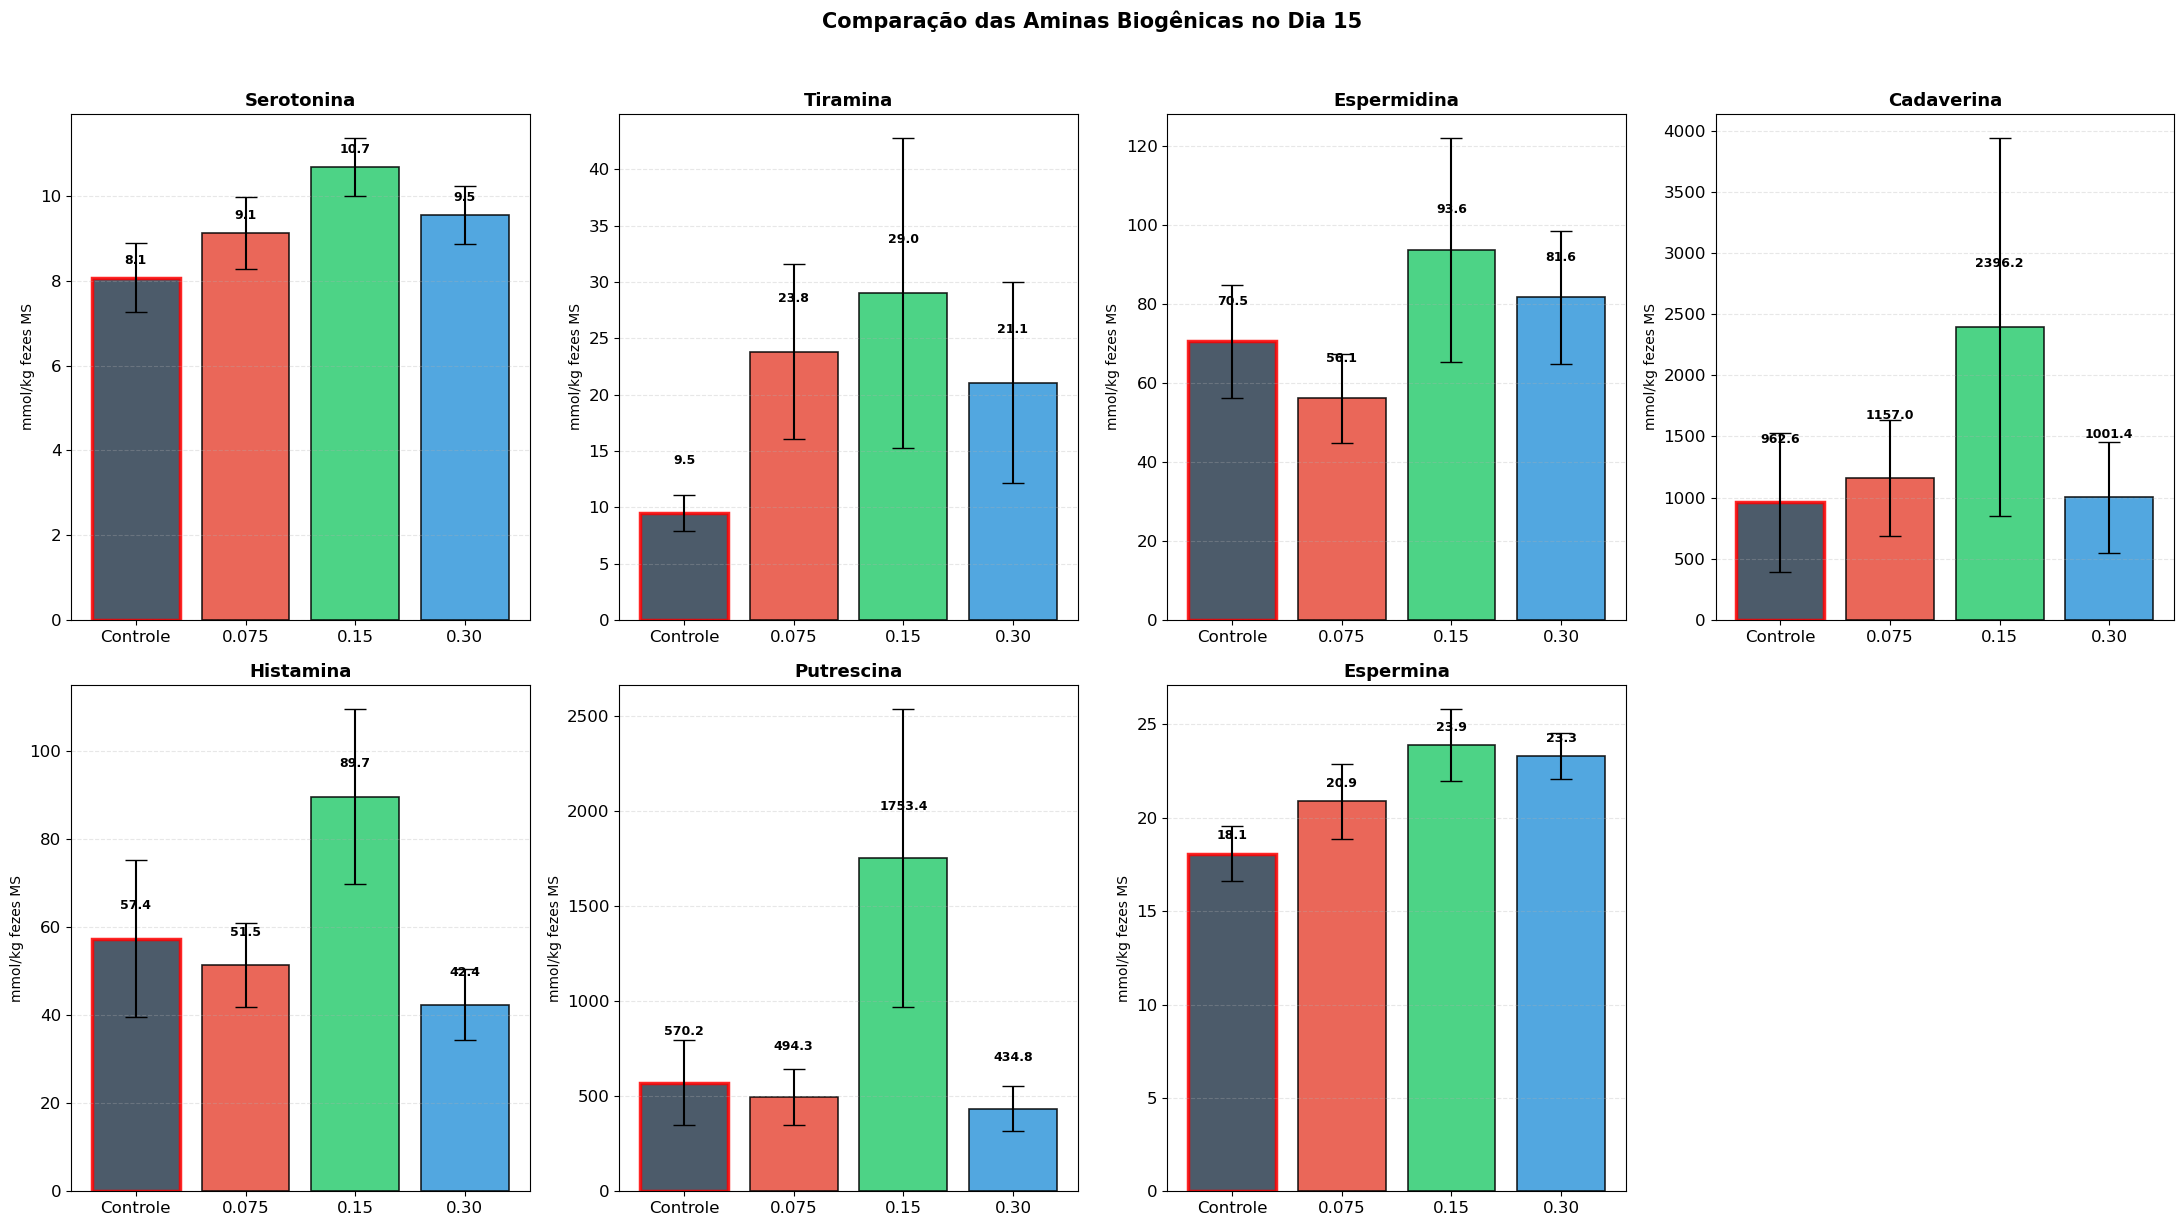

In [357]:
barras_dia15_aminas(df)

### Conclusão Integrada — Aminas Biogênicas

---
As sete aminas biogênicas analisadas (serotonina, tiramina, espermidina, cadaverina, histamina, putrescina e espermina) foram avaliadas sob o mesmo protocolo padronizado. Diferentemente das cadeias anteriores (AGCC e AGCR), esta cadeia caracterizou‑se por **efeitos temporais em algumas variáveis e ausência de efeito consistente do TYN**, com várias variáveis comprometidas por violação de pressupostos.

| Variável | Caminho | Efeito de Dias (MixedLM) | Efeito de Tratamento (MixedLM) | Decisão |
|:---------|:-------:|:------------------------:|:------------------------------:|:---------|
| Serotonina | A | Significativo (p = 0,002) | Não significativo (p = 0,497) | 🟡 Efeito temporal, sem efeito de tratamento |
| Tiramina | C | Modelo inválido (p = 0,835) | Modelo inválido (p = 0,980) | 🔴 Evidência insuficiente |
| Espermidina | C | Modelo inválido (p = 0,013)* | Modelo inválido (p = 0,838) | 🔴 Evidência insuficiente |
| Cadaverina | C | Modelo inválido (p = 0,754) | Modelo inválido (p = 0,989) | 🔴 Evidência insuficiente |
| Histamina | A | Significativo (p = 0,031) | Não significativo (p = 0,961) | 🟡 Efeito temporal, sem efeito de tratamento |
| Putrescina | C | Modelo inválido (p = 0,455) | Modelo inválido (p = 0,986) | 🔴 Evidência insuficiente |
| Espermina | A | Significativo (p < 0,001) | Não significativo (p = 0,647) | 🟡 Efeito temporal, sem efeito de tratamento |

*Modelo com aviso de convergência e normalidade violada.

**Interpretação geral:**

- **Efeito temporal em variáveis com modelo válido:** Serotonina, histamina e espermina apresentaram aumento significativo ao longo do tempo, com padrão de elevação na primeira semana e estabilização no Dia 15. Esse comportamento foi comum a todos os grupos, inclusive o Controle, indicando uma **adaptação fisiológica à dieta experimental**, e não um efeito do TYN.

- **Variáveis com modelo inválido (Caminho C):** Tiramina, espermidina, cadaverina e putrescina não puderam ser avaliadas inferencialmente devido à violação severa de normalidade. Na ausência de testes não paramétricos (removidos da análise), não há suporte estatístico válido para concluir sobre efeitos nessas variáveis. Os resultados observados são meramente descritivos.

- **Ausência de efeito do TYN:** Nenhuma das variáveis com modelo válido apresentou efeito de Tratamento ou Interação significativos. Os sinais isolados observados em análises complementares (como possíveis diferenças no Dia 15) são exploratórios e não corroborados pelos testes globais, não permitindo conclusão sobre eficácia do TYN.

**Comparação com as demais cadeias:**

Enquanto os **AGCC** e os **AGCR** apresentaram efeitos robustos do TYN (especialmente na dose 0,15), as **aminas biogênicas** mostraram‑se majoritariamente insensíveis ao produto. Isso sugere que o TYN atua preferencialmente sobre as vias fermentativas sacarolítica e proteolítica (refletidas nos AGCC e AGCR), sem alterar de forma consistente o metabolismo das aminas.

**Recomendação para o pesquisador:**

- As aminas biogênicas **não devem ser utilizadas como desfechos primários** para avaliação do TYN, uma vez que os efeitos observados foram explicados pelo tempo (dieta) e não pelo tratamento, ou foram inviabilizados por violação de pressupostos.
- Os sinais isolados observados em análises complementares (principalmente para a dose 0,15) são insuficientes para qualquer conclusão definitiva e requerem replicação em estudos futuros com maior poder amostral.
- A ausência de efeito sobre as aminas não diminui os achados positivos nas cadeias de AGCC e AGCR; ao contrário, reforça a especificidade de ação do TYN sobre as vias fermentativas, sem impacto consistente sobre o metabolismo das aminas biogênicas.

---

### Medias Gerais

In [358]:
import pandas as pd
import numpy as np

# Colunas que NÃO são variáveis
cols_excluir = ['Animais', 'Tratamento', 'Dias']

# Detecta automaticamente todas as variáveis numéricas
variaveis = [
    c for c in df.columns
    if c not in cols_excluir
    and pd.api.types.is_numeric_dtype(df[c])
]

tabelas = {}

for var in variaveis:

    # Média e SEM por Tratamento x Dia
    resumo = (
        df.groupby(['Dias', 'Tratamento'])[var]
        .agg(['mean', 'sem'])
        .reset_index()
    )

    # Tabela das médias
    medias = resumo.pivot(
        index='Dias',
        columns='Tratamento',
        values='mean'
    )

    # Tabela dos SEM
    erros = resumo.pivot(
        index='Dias',
        columns='Tratamento',
        values='sem'
    )

    # Junta média ± SEM
    tabela = medias.round(2).astype(str) + ' ± ' + erros.round(2).astype(str)

    #################################################
    # Média geral por DIA
    #################################################

    media_dia = (
        df.groupby('Dias')[var]
        .mean()
        .round(2)
    )

    sem_dia = (
        df.groupby('Dias')[var]
        .sem()
        .round(2)
    )

    tabela['Mean'] = (
        media_dia.astype(str)
        + ' ± '
        + sem_dia.astype(str)
    )

    #################################################
    # Média geral por TRATAMENTO
    #################################################

    media_trat = (
        df.groupby('Tratamento')[var]
        .mean()
        .round(2)
    )

    sem_trat = (
        df.groupby('Tratamento')[var]
        .sem()
        .round(2)
    )

    linha_media = (
        media_trat.astype(str)
        + ' ± '
        + sem_trat.astype(str)
    )

    linha_media['Mean'] = (
        str(round(df[var].mean(), 2))
        + ' ± '
        + str(round(df[var].sem(), 2))
    )

    tabela.loc['Mean'] = linha_media

    tabelas[var] = tabela

In [360]:
print(tabela)

Tratamento         CONTROLE           Trat 1            Trat 2  \
Dias                                                             
0            206.13 ± 75.41  229.27 ± 117.29    443.0 ± 276.94   
7           638.46 ± 307.87  722.21 ± 362.98   788.03 ± 145.64   
15           570.2 ± 224.06  494.32 ± 147.31  1753.39 ± 782.54   
Mean         471.6 ± 129.96  481.93 ± 137.04  1006.97 ± 312.64   

Tratamento           Trat 3             Mean  
Dias                                          
0            253.93 ± 83.43   283.08 ± 77.37  
7           607.44 ± 171.51   684.73 ± 127.4  
15           434.8 ± 116.56  813.18 ± 225.47  
Mean         432.06 ± 78.25   592.38 ± 93.28  


In [361]:
from IPython.display import display

for var, tabela in tabelas.items():
    print(f'\n{"="*80}')
    print(var)
    print(f'{"="*80}')
    display(tabela)


Bloco


Tratamento,CONTROLE,Trat 1,Trat 2,Trat 3,Mean
Dias,,,,,
0,1.5 ± 0.22,1.5 ± 0.22,1.5 ± 0.22,1.5 ± 0.22,1.5 ± 0.1
7,1.5 ± 0.22,1.5 ± 0.22,1.5 ± 0.22,1.5 ± 0.22,1.5 ± 0.1
15,1.5 ± 0.22,1.5 ± 0.22,1.5 ± 0.22,1.5 ± 0.22,1.5 ± 0.1
Mean,1.5 ± 0.12,1.5 ± 0.12,1.5 ± 0.12,1.5 ± 0.12,1.5 ± 0.06



PH


Tratamento,CONTROLE,Trat 1,Trat 2,Trat 3,Mean
Dias,,,,,
0,6.08 ± 0.2,6.04 ± 0.17,5.83 ± 0.2,6.04 ± 0.16,5.99 ± 0.09
7,6.01 ± 0.21,5.86 ± 0.14,5.96 ± 0.17,5.95 ± 0.07,5.94 ± 0.07
15,6.08 ± 0.19,6.22 ± 0.21,5.68 ± 0.11,6.06 ± 0.15,6.01 ± 0.09
Mean,6.06 ± 0.11,6.04 ± 0.1,5.82 ± 0.09,6.02 ± 0.07,5.98 ± 0.05



escore_fecal


...


Total_aminas


Tratamento,CONTROLE,Trat 1,Trat 2,Trat 3,Mean
Dias,,,,,
0,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
7,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
15,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
Mean,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan


Tratamento,CONTROLE,Trat 1,Trat 2,Trat 3,Mean
Dias,,,,,
0,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
7,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
15,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
Mean,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan



 .1


Tratamento,CONTROLE,Trat 1,Trat 2,Trat 3,Mean
Dias,,,,,
0,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
7,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
15,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
Mean,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan


In [219]:
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np
import pandas as pd
from statsmodels.formula.api import mixedlm, ols
from statsmodels.stats.anova import anova_lm

def diagnostico_completo(df, variavel, modelo_misto, dias_col='Dias', trat_col='Tratamento'):
    """
    Gera diagnósticos completos para uma variável:
    - QQ-plot, Resíduos vs Ajustados, Histograma
    - Teste de Shapiro-Wilk
    - Teste de Levene (homocedasticidade)
    - Contrastes polinomiais (linear/quadrática) se Dias for significativo
    """
    
    residuos = modelo_misto.resid
    fitted = modelo_misto.fittedvalues
    
    # ========== GRÁFICOS ==========
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # 1. Resíduos vs Ajustados
    axes[0].scatter(fitted, residuos, alpha=0.6, edgecolors='k', linewidth=0.5)
    axes[0].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
    axes[0].set_xlabel('Valores Ajustados', fontsize=11)
    axes[0].set_ylabel('Resíduos', fontsize=11)
    axes[0].set_title(f'{variavel}: Resíduos vs Ajustados', fontsize=12)
    # Adiciona linha de suavização LOWESS (se disponível)
    try:
        from statsmodels.nonparametric.smoothers_lowess import lowess
        lowess_fit = lowess(residuos, fitted)
        axes[0].plot(lowess_fit[:, 0], lowess_fit[:, 1], color='blue', linewidth=2, label='Tendência')
        axes[0].legend()
    except:
        pass
    
    # 2. QQ-plot
    stats.probplot(residuos, dist="norm", plot=axes[1])
    axes[1].get_lines()[0].set_markerfacecolor('steelblue')
    axes[1].get_lines()[0].set_markeredgecolor('black')
    axes[1].get_lines()[0].set_alpha(0.7)
    axes[1].set_title(f'{variavel}: Q-Q Plot', fontsize=12)
    
    # 3. Histograma + curva normal
    axes[2].hist(residuos, bins=min(15, len(residuos)//5), density=True, 
                 alpha=0.6, edgecolor='black', color='steelblue')
    xmin, xmax = axes[2].get_xlim()
    x = np.linspace(xmin, xmax, 100)
    p = stats.norm.pdf(x, np.mean(residuos), np.std(residuos))
    axes[2].plot(x, p, 'k', linewidth=2, label='Normal teórica')
    axes[2].set_title(f'{variavel}: Histograma dos Resíduos', fontsize=12)
    axes[2].legend()
    
    plt.tight_layout()
    plt.show()
    
    # ========== TESTES ESTATÍSTICOS ==========
    print(f"\n{'='*60}")
    print(f"DIAGNÓSTICO: {variavel}")
    print(f"{'='*60}")
    
    # Shapiro-Wilk (Normalidade)
    if len(residuos) >= 3 and len(residuos) <= 5000:
        shapiro_stat, shapiro_p = stats.shapiro(residuos)
        print(f"Shapiro-Wilk (Normalidade): W = {shapiro_stat:.4f}, p = {shapiro_p:.4f}")
        if shapiro_p > 0.05:
            print("  → Resíduos NÃO diferem significativamente da normal (p > 0.05)")
        else:
            print("  → ATENÇÃO: Resíduos diferem da normal (p < 0.05)")
    
    # Levene (Homocedasticidade) - por combinação Tratamento×Dia
    df_clean = df.dropna(subset=[variavel])
    df_clean['grupo'] = df_clean[trat_col].astype(str) + '_' + df_clean[dias_col].astype(str)
    grupos = [df_clean.loc[df_clean['grupo'] == g, variavel].values 
              for g in df_clean['grupo'].unique() if len(df_clean.loc[df_clean['grupo'] == g]) > 1]
    if len(grupos) > 1:
        levene_stat, levene_p = stats.levene(*grupos)
        print(f"Levene (Homocedasticidade): W = {levene_stat:.4f}, p = {levene_p:.4f}")
        if levene_p > 0.05:
            print("  → Variâncias homogêneas entre grupos (p > 0.05)")
        else:
            print("  → ATENÇÃO: Variâncias heterogêneas (p < 0.05)")
    
    # ========== CONTRASTES POLINOMIAIS (Tendência Linear/Quadrática) ==========
    print(f"\n--- Contrastes Polinomiais para Dias ---")
    
    df_clean[dias_col] = pd.to_numeric(df_clean[dias_col])
    
    # Ajusta modelo com Dias como variável numérica (linear + quadrática)
    try:
        # Modelo linear
        modelo_linear = mixedlm(f"{variavel} ~ C({trat_col}) + {dias_col}", 
                                data=df_clean, groups=df_clean["Animais"])
        result_linear = modelo_linear.fit()
        
        # Modelo quadrático
        df_clean[f'{dias_col}_quad'] = df_clean[dias_col] ** 2
        modelo_quad = mixedlm(f"{variavel} ~ C({trat_col}) + {dias_col} + {dias_col}_quad", 
                              data=df_clean, groups=df_clean["Animais"])
        result_quad = modelo_quad.fit()
        
        # Extrair p-valores dos coeficientes de Dias
        linear_coef = result_linear.params.get(dias_col, None)
        linear_p = result_linear.pvalues.get(dias_col, None)
        
        quad_coef = result_quad.params.get(f'{dias_col}_quad', None)
        quad_p = result_quad.pvalues.get(f'{dias_col}_quad', None)
        
        print(f"Tendência Linear:  coef = {linear_coef:.4f}, p = {linear_p:.4f}" if linear_coef else "Tendência Linear: não calculada")
        print(f"Tendência Quadrática: coef = {quad_coef:.4f}, p = {quad_p:.4f}" if quad_coef else "Tendência Quadrática: não calculada")
        
        # Interpretação
        if linear_p and linear_p < 0.05:
            print("  → Há evidência de tendência LINEAR significativa ao longo dos dias")
        if quad_p and quad_p < 0.05:
            print("  → Há evidência de tendência QUADRÁTICA significativa ao longo dos dias")
        if (linear_p and linear_p > 0.05) and (quad_p and quad_p > 0.05):
            print("  → Não há evidência de tendência linear nem quadrática")
            
    except Exception as e:
        print(f"  Erro nos contrastes polinomiais: {e}")
    
    return residuos, fitted

# ===== EXEMPLO DE USO =====
# Para cada variável, chame:
# residuos, fitted = diagnostico_completo(df_clean_serotonina, 'Serotonina', resultado_serotonina)

In [105]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import pandas as pd

def posthoc_dias(df, variavel, trat_col='Tratamento', dias_col='Dias'):
    """
    Post-hoc para efeito de Dias (colapsando tratamentos).
    Usa Tukey HSD para comparar os 3 dias (0, 7, 15).
    """
    df_clean = df.dropna(subset=[variavel])
    
    print(f"\n{'='*60}")
    print(f"POST-HOC TUKEY (Dias): {variavel}")
    print(f"{'='*60}")
    
    # Tukey HSD
    tukey = pairwise_tukeyhsd(df_clean[variavel], df_clean[dias_col], alpha=0.05)
    print(tukey)
    
    # Médias por dia
    medias_dias = df_clean.groupby(dias_col)[variavel].agg(['mean', 'std', 'sem', 'count'])
    print("\nMédias por Dia:")
    print(medias_dias.round(2))
    
    return tukey

# Exemplo:
# posthoc_dias(df_clean_serotonina, 'Serotonina')

In [220]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import pandas as pd

def posthoc_dias(df, variavel, trat_col='Tratamento', dias_col='Dias'):
    """
    Post-hoc para efeito de Dias (colapsando tratamentos).
    Usa Tukey HSD para comparar os 3 dias (0, 7, 15).
    """
    df_clean = df.dropna(subset=[variavel])
    
    print(f"\n{'='*60}")
    print(f"POST-HOC TUKEY (Dias): {variavel}")
    print(f"{'='*60}")
    
    # Tukey HSD
    tukey = pairwise_tukeyhsd(df_clean[variavel], df_clean[dias_col], alpha=0.05)
    print(tukey)
    
    # Médias por dia
    medias_dias = df_clean.groupby(dias_col)[variavel].agg(['mean', 'std', 'sem', 'count'])
    print("\nMédias por Dia:")
    print(medias_dias.round(2))
    
    return tukey

# Exemplo:
# posthoc_dias(df_clean_serotonina, 'Serotonina')

In [11]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import numpy as np

def diagnostico_pressupostos(df_clean, variavel, resultado):
    """
    Passo 3 – Diagnóstico de pressupostos do modelo misto.
    df_clean: DataFrame já com categorias definidas e sem missing.
    variavel: nome da coluna da variável resposta (string).
    resultado: objeto resultado do MixedLM já ajustado.
    """
    residuos = resultado.resid
    fitted = resultado.fittedvalues

    # ========== GRÁFICOS ==========
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # 1. Resíduos vs Ajustados
    axes[0].scatter(fitted, residuos, alpha=0.6, edgecolors='k', linewidth=0.5)
    axes[0].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
    axes[0].set_xlabel('Valores Ajustados', fontsize=11)
    axes[0].set_ylabel('Resíduos', fontsize=11)
    axes[0].set_title(f'{variavel}: Resíduos vs Ajustados', fontsize=12)
    try:
        from statsmodels.nonparametric.smoothers_lowess import lowess
        lowess_fit = lowess(residuos, fitted)
        axes[0].plot(lowess_fit[:, 0], lowess_fit[:, 1], color='blue', linewidth=2, label='Tendência')
        axes[0].legend()
    except:
        pass

    # 2. QQ-plot
    stats.probplot(residuos, dist="norm", plot=axes[1])
    axes[1].get_lines()[0].set_markerfacecolor('steelblue')
    axes[1].get_lines()[0].set_markeredgecolor('black')
    axes[1].get_lines()[0].set_alpha(0.7)
    axes[1].set_title(f'{variavel}: Q-Q Plot', fontsize=12)

    # 3. Histograma + curva normal
    axes[2].hist(residuos, bins=min(15, len(residuos)//5), density=True,
                 alpha=0.6, edgecolor='black', color='steelblue')
    xmin, xmax = axes[2].get_xlim()
    x = np.linspace(xmin, xmax, 100)
    p = stats.norm.pdf(x, np.mean(residuos), np.std(residuos))
    axes[2].plot(x, p, 'k', linewidth=2, label='Normal teórica')
    axes[2].set_title(f'{variavel}: Histograma dos Resíduos', fontsize=12)
    axes[2].legend()

    plt.tight_layout()
    plt.show()

    # ========== TESTES ESTATÍSTICOS ==========
    print(f"\n{'='*60}")
    print(f"DIAGNÓSTICO DE PRESSUPOSTOS: {variavel}")
    print(f"{'='*60}")

    # Shapiro-Wilk
    if 3 <= len(residuos) <= 5000:
        shapiro_stat, shapiro_p = stats.shapiro(residuos)
        print(f"Shapiro-Wilk (Normalidade): W = {shapiro_stat:.4f}, p = {shapiro_p:.4f}")
        if shapiro_p > 0.05:
            print("  → Normalidade atendida (p > 0.05) ✅")
        else:
            print("  → ATENÇÃO: Resíduos não normais (p < 0.05) ❌")

    # Levene
    df_clean['grupo'] = df_clean['Tratamento'].astype(str) + '_D' + df_clean['Dias'].astype(str)
    grupos = [df_clean.loc[df_clean['grupo'] == g, variavel].values
              for g in df_clean['grupo'].unique()
              if len(df_clean.loc[df_clean['grupo'] == g]) > 1]
    if len(grupos) > 1:
        levene_stat, levene_p = stats.levene(*grupos)
        print(f"Levene (Homocedasticidade): W = {levene_stat:.4f}, p = {levene_p:.4f}")
        if levene_p > 0.05:
            print("  → Homocedasticidade atendida (p > 0.05) ✅")
        else:
            print("  → ATENÇÃO: Variâncias heterogêneas (p < 0.05) ❌")
    else:
        levene_p = np.nan
        print("Levene: não calculado (grupos insuficientes)")

    # Decisão
    if shapiro_p > 0.05 and levene_p > 0.05:
        print("\n→ CAMINHO A: Pressupostos atendidos. Seguir com testes paramétricos.")
    elif shapiro_p < 0.001:
        print("\n→ CAMINHO C: Severa violação de normalidade.")
    else:
        print("\n→ CAMINHO B: Violação moderada. Testes paramétricos com ressalva ")

    return residuos, fitted

# ===== USO =====
# residuos, fitted = diagnostico_pressupostos(df_clean, 'acetico', resultado)

In [12]:
from statsmodels.formula.api import mixedlm
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def contrastes_polinomiais(df_clean, variavel):
    """
    Passo 4.4 – Contrastes polinomiais (Linear e Quadrático).
    Utiliza Dias como variável numérica contínua.
    df_clean: DataFrame com colunas 'Tratamento', 'Dias' (categórico ou numérico), 'Animais'.
    variavel: nome da coluna resposta.
    """
    df_temp = df_clean.copy()
    df_temp['Dias_num'] = pd.to_numeric(df_temp['Dias'])

    print(f"\n--- Contrastes Polinomiais para Dias ({variavel}) ---")

    try:
        # Modelo linear
        mod_lin = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num",
                          data=df_temp, groups="Animais")
        res_lin = mod_lin.fit()
        coef_lin = res_lin.params.get('Dias_num', None)
        p_lin = res_lin.pvalues.get('Dias_num', None)

        # Modelo quadrático
        df_temp['Dias_num2'] = df_temp['Dias_num'] ** 2
        mod_quad = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num + Dias_num2",
                           data=df_temp, groups="Animais")
        res_quad = mod_quad.fit()
        coef_quad = res_quad.params.get('Dias_num2', None)
        p_quad = res_quad.pvalues.get('Dias_num2', None)

        # Exibição
        if coef_lin is not None:
            print(f"Tendência Linear:     coef = {coef_lin:.4f}, p = {p_lin:.4f}", 
                  "✅" if p_lin < 0.05 else "")
        else:
            print("Tendência Linear: não calculada")

        if coef_quad is not None:
            print(f"Tendência Quadrática: coef = {coef_quad:.4f}, p = {p_quad:.4f}", 
                  "✅" if p_quad < 0.05 else "")
        else:
            print("Tendência Quadrática: não calculada")

        if p_lin and p_lin < 0.05:
            print("  → Há evidência de tendência LINEAR significativa")
        if p_quad and p_quad < 0.05:
            print("  → Há evidência de tendência QUADRÁTICA significativa")
        if (p_lin and p_lin > 0.05) and (p_quad and p_quad > 0.05):
            print("  → Nenhuma tendência significativa detectada")

        # ========== GRÁFICO ==========
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=df_temp, x='Dias_num', y=variavel,
                        hue='Tratamento', style='Tratamento', s=60, alpha=0.8)

        # Determinar qual modelo usar para a curva
        if p_quad is not None and p_quad < 0.05:      # quadrática significativa
            intercept = res_quad.params.get('Intercept', 0)
            b1 = res_quad.params.get('Dias_num', 0)
            b2 = res_quad.params.get('Dias_num2', 0)
            x_grid = np.linspace(df_temp['Dias_num'].min(), df_temp['Dias_num'].max(), 100)
            y_pred = intercept + b1 * x_grid + b2 * x_grid**2
            plt.plot(x_grid, y_pred, 'k-', linewidth=2.5, label='Tend. Quadrática (ref.)')
        elif p_lin is not None and p_lin < 0.05:      # linear significativa
            intercept = res_lin.params.get('Intercept', 0)
            b1 = res_lin.params.get('Dias_num', 0)
            x_grid = np.linspace(df_temp['Dias_num'].min(), df_temp['Dias_num'].max(), 100)
            y_pred = intercept + b1 * x_grid
            plt.plot(x_grid, y_pred, 'k-', linewidth=2.5, label='Tend. Linear (ref.)')
        # se nenhuma for significativa, não traça linha

        plt.title(f"{variavel} – Tendência ao longo dos dias")
        plt.xlabel("Dias (numérico)")
        plt.ylabel(variavel)
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

        return res_lin, res_quad

    except Exception as e:
        print(f"  Erro nos contrastes polinomiais: {e}")
        return None, None

In [37]:
import pandas as pd
from statsmodels.formula.api import mixedlm

def contrastes_polinomiais(df_clean, variavel):
    """
    Passo 4.4 – Contrastes polinomiais (Linear e Quadrático).
    Utiliza Dias como variável numérica contínua.
    df_clean: DataFrame com colunas 'Tratamento', 'Dias' (categórico ou numérico), 'Animais'.
    variavel: nome da coluna resposta.
    """
    df_temp = df_clean.copy()
    df_temp['Dias_num'] = pd.to_numeric(df_temp['Dias'])

    print(f"\n--- Contrastes Polinomiais para Dias ({variavel}) ---")

    try:
        # Modelo linear
        mod_lin = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num",
                          data=df_temp, groups="Animais")
        res_lin = mod_lin.fit()
        coef_lin = res_lin.params.get('Dias_num', None)
        p_lin = res_lin.pvalues.get('Dias_num', None)

        # Modelo quadrático
        df_temp['Dias_num2'] = df_temp['Dias_num'] ** 2
        mod_quad = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num + Dias_num2",
                           data=df_temp, groups="Animais")
        res_quad = mod_quad.fit()
        coef_quad = res_quad.params.get('Dias_num2', None)
        p_quad = res_quad.pvalues.get('Dias_num2', None)

        # Exibição
        if coef_lin is not None:
            print(f"Tendência Linear:     coef = {coef_lin:.4f}, p = {p_lin:.4f}", 
                  "✅" if p_lin < 0.05 else "")
        else:
            print("Tendência Linear: não calculada")

        if coef_quad is not None:
            print(f"Tendência Quadrática: coef = {coef_quad:.4f}, p = {p_quad:.4f}", 
                  "✅" if p_quad < 0.05 else "")
        else:
            print("Tendência Quadrática: não calculada")

        if p_lin and p_lin < 0.05:
            print("  → Há evidência de tendência LINEAR significativa")
        if p_quad and p_quad < 0.05:
            print("  → Há evidência de tendência QUADRÁTICA significativa")
        if (p_lin and p_lin > 0.05) and (p_quad and p_quad > 0.05):
            print("  → Nenhuma tendência significativa detectada")

        return res_lin, res_quad

    except Exception as e:
        print(f"  Erro nos contrastes polinomiais: {e}")
        return None, None

# ===== USO =====
# res_lin, res_quad = contrastes_polinomiais(df_clean, 'acetico')

In [3]:
from statsmodels.formula.api import mixedlm
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def contrastes_polinomiais(df_clean, variavel):
    """
    Passo 4.4 – Contrastes polinomiais (Linear e Quadrático).
    Utiliza Dias como variável numérica contínua.
    df_clean: DataFrame com colunas 'Tratamento', 'Dias' (categórico ou numérico), 'Animais'.
    variavel: nome da coluna resposta.
    """
    df_temp = df_clean.copy()
    df_temp['Dias_num'] = pd.to_numeric(df_temp['Dias'])

    print(f"\n--- Contrastes Polinomiais para Dias ({variavel}) ---")

    try:
        # Modelo linear
        mod_lin = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num",
                          data=df_temp, groups="Animais")
        res_lin = mod_lin.fit()
        coef_lin = res_lin.params.get('Dias_num', None)
        p_lin = res_lin.pvalues.get('Dias_num', None)

        # Modelo quadrático
        df_temp['Dias_num2'] = df_temp['Dias_num'] ** 2
        mod_quad = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num + Dias_num2",
                           data=df_temp, groups="Animais")
        res_quad = mod_quad.fit()
        coef_quad = res_quad.params.get('Dias_num2', None)
        p_quad = res_quad.pvalues.get('Dias_num2', None)

        # Exibição
        if coef_lin is not None:
            print(f"Tendência Linear:     coef = {coef_lin:.4f}, p = {p_lin:.4f}", 
                  "✅" if p_lin < 0.05 else "")
        else:
            print("Tendência Linear: não calculada")

        if coef_quad is not None:
            print(f"Tendência Quadrática: coef = {coef_quad:.4f}, p = {p_quad:.4f}", 
                  "✅" if p_quad < 0.05 else "")
        else:
            print("Tendência Quadrática: não calculada")

        if p_lin and p_lin < 0.05:
            print("  → Há evidência de tendência LINEAR significativa")
        if p_quad and p_quad < 0.05:
            print("  → Há evidência de tendência QUADRÁTICA significativa")
        if (p_lin and p_lin > 0.05) and (p_quad and p_quad > 0.05):
            print("  → Nenhuma tendência significativa detectada")

        # ========== GRÁFICO ==========
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=df_temp, x='Dias_num', y=variavel,
                        hue='Tratamento', style='Tratamento', s=60, alpha=0.8)

        # Determinar qual modelo usar para a curva
        if p_quad is not None and p_quad < 0.05:      # quadrática significativa
            intercept = res_quad.params.get('Intercept', 0)
            b1 = res_quad.params.get('Dias_num', 0)
            b2 = res_quad.params.get('Dias_num2', 0)
            x_grid = np.linspace(df_temp['Dias_num'].min(), df_temp['Dias_num'].max(), 100)
            y_pred = intercept + b1 * x_grid + b2 * x_grid**2
            plt.plot(x_grid, y_pred, 'k-', linewidth=2.5, label='Tend. Quadrática (ref.)')
        elif p_lin is not None and p_lin < 0.05:      # linear significativa
            intercept = res_lin.params.get('Intercept', 0)
            b1 = res_lin.params.get('Dias_num', 0)
            x_grid = np.linspace(df_temp['Dias_num'].min(), df_temp['Dias_num'].max(), 100)
            y_pred = intercept + b1 * x_grid
            plt.plot(x_grid, y_pred, 'k-', linewidth=2.5, label='Tend. Linear (ref.)')
        # se nenhuma for significativa, não traça linha

        plt.title(f"{variavel} – Tendência ao longo dos dias")
        plt.xlabel("Dias (numérico)")
        plt.ylabel(variavel)
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

        return res_lin, res_quad

    except Exception as e:
        print(f"  Erro nos contrastes polinomiais: {e}")
        return None, None

In [171]:
def posthoc_interacao(df, variavel, trat_col='Tratamento', dias_col='Dias'):
    """
    Post-hoc para interação significativa.
    Estratégia: comparar tratamentos DENTRO de cada dia (Dunnett vs Controle)
    e comparar dias DENTRO de cada tratamento (Tukey).
    """
    df_clean = df.dropna(subset=[variavel])
    df_clean['Trat_Dia'] = df_clean[trat_col].astype(str) + '_D' + df_clean[dias_col].astype(str)
    
    print(f"\n{'='*60}")
    print(f"POST-HOC INTERAÇÃO: {variavel}")
    print(f"{'='*60}")
    
    # 1. Comparar tratamentos vs Controle DENTRO de cada dia
    for dia in sorted(df_clean[dias_col].unique()):
        dados_dia = df_clean[df_clean[dias_col] == dia]
        controle_valores = dados_dia[dados_dia[trat_col] == 'CONTROLE'][variavel].values
        
        print(f"\n--- Dia {dia}: Comparações vs Controle (Teste t com correção Bonferroni) ---")
        
        for trat in ['Trat 1', 'Trat 2', 'Trat 3']:
            trat_valores = dados_dia[dados_dia[trat_col] == trat][variavel].values
            if len(trat_valores) > 0 and len(controle_valores) > 0:
                t_stat, p_val = stats.ttest_ind(trat_valores, controle_valores)
                p_corrigido = min(p_val * 3, 1.0)  # Bonferroni: 3 comparações por dia
                
                media_trat = np.mean(trat_valores)
                media_cont = np.mean(controle_valores)
                diff = media_trat - media_cont
                
                sig = "*" if p_corrigido < 0.05 else "ns"
                print(f"  {trat} vs Controle: dif = {diff:.2f}, p_raw = {p_val:.4f}, p_corr = {p_corrigido:.4f} {sig}")
    
    # 2. Comparar dias DENTRO de cada tratamento
    print(f"\n--- Comparações entre Dias (Tukey HSD) para cada Tratamento ---")
    for trat in sorted(df_clean[trat_col].unique()):
        dados_trat = df_clean[df_clean[trat_col] == trat]
        if len(dados_trat[dias_col].unique()) > 1:
            tukey = pairwise_tukeyhsd(dados_trat[variavel], dados_trat[dias_col], alpha=0.05)
            print(f"\n{trat}:")
            print(tukey)

# Exemplo:
# posthoc_interacao(df_clean_agcr, 'AGCR_TOTAL')

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import mixedlm, ols

# ============================================================
# Versão 1: Curva de tendência + intervalo de confiança (aproximado via OLS)
# ============================================================
def contrastes_polinomiais_1(df_clean, variavel):
    """
    Gráfico com curva de tendência e faixa de confiança (OLS auxiliar).
    """
    df_temp = df_clean.copy()
    df_temp['Dias_num'] = pd.to_numeric(df_temp['Dias'])

    print(f"\n--- Contrastes Polinomiais para Dias ({variavel}) [Gráfico 1] ---")

    try:
        # Modelo linear (misto)
        mod_lin = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num",
                          data=df_temp, groups="Animais")
        res_lin = mod_lin.fit()
        coef_lin = res_lin.params.get('Dias_num', None)
        p_lin = res_lin.pvalues.get('Dias_num', None)

        # Modelo quadrático (misto)
        df_temp['Dias_num2'] = df_temp['Dias_num'] ** 2
        mod_quad = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num + Dias_num2",
                           data=df_temp, groups="Animais")
        res_quad = mod_quad.fit()
        coef_quad = res_quad.params.get('Dias_num2', None)
        p_quad = res_quad.pvalues.get('Dias_num2', None)

        # Exibição
        if coef_lin is not None:
            print(f"Tendência Linear:     coef = {coef_lin:.4f}, p = {p_lin:.4f}", 
                  "✅" if p_lin < 0.05 else "")
        if coef_quad is not None:
            print(f"Tendência Quadrática: coef = {coef_quad:.4f}, p = {p_quad:.4f}", 
                  "✅" if p_quad < 0.05 else "")
        if p_lin and p_lin < 0.05:
            print("  → Há evidência de tendência LINEAR significativa")
        if p_quad and p_quad < 0.05:
            print("  → Há evidência de tendência QUADRÁTICA significativa")
        if (p_lin and p_lin > 0.05) and (p_quad and p_quad > 0.05):
            print("  → Nenhuma tendência significativa detectada")

        # ---------- GRÁFICO 1: curva + IC (via OLS) ----------
        plt.figure(figsize=(8,5))
        if p_quad is not None and p_quad < 0.05:
            # Quadrática com IC
            sns.regplot(data=df_temp, x='Dias_num', y=variavel, order=2,
                        scatter=True, ci=95, line_kws={'color':'black','lw':2},
                        label='Quadrática (IC 95%)')
        elif p_lin is not None and p_lin < 0.05:
            sns.regplot(data=df_temp, x='Dias_num', y=variavel, order=1,
                        scatter=True, ci=95, line_kws={'color':'black','lw':2},
                        label='Linear (IC 95%)')
        else:
            # Apenas pontos, sem linha
            sns.scatterplot(data=df_temp, x='Dias_num', y=variavel, 
                            hue='Tratamento', style='Tratamento', s=60)
        plt.title(f"{variavel} – Tendência com IC 95%")
        plt.xlabel("Dias")
        plt.ylabel(variavel)
        plt.legend()
        plt.tight_layout()
        plt.show()

        return res_lin, res_quad

    except Exception as e:
        print(f"  Erro nos contrastes polinomiais: {e}")
        return None, None

# ============================================================
# Versão 2: Facetas por tratamento com a mesma curva de tendência
# ============================================================
def contrastes_polinomiais_2(df_clean, variavel):
    """
    Gráfico com facets (painéis) por tratamento e curva única de tendência.
    """
    df_temp = df_clean.copy()
    df_temp['Dias_num'] = pd.to_numeric(df_temp['Dias'])

    print(f"\n--- Contrastes Polinomiais para Dias ({variavel}) [Gráfico 2] ---")

    try:
        mod_lin = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num",
                          data=df_temp, groups="Animais")
        res_lin = mod_lin.fit()
        coef_lin = res_lin.params.get('Dias_num', None)
        p_lin = res_lin.pvalues.get('Dias_num', None)

        df_temp['Dias_num2'] = df_temp['Dias_num'] ** 2
        mod_quad = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num + Dias_num2",
                           data=df_temp, groups="Animais")
        res_quad = mod_quad.fit()
        coef_quad = res_quad.params.get('Dias_num2', None)
        p_quad = res_quad.pvalues.get('Dias_num2', None)

        if coef_lin is not None:
            print(f"Tendência Linear:     coef = {coef_lin:.4f}, p = {p_lin:.4f}", 
                  "✅" if p_lin < 0.05 else "")
        if coef_quad is not None:
            print(f"Tendência Quadrática: coef = {coef_quad:.4f}, p = {p_quad:.4f}", 
                  "✅" if p_quad < 0.05 else "")
        if p_lin and p_lin < 0.05:
            print("  → Há evidência de tendência LINEAR significativa")
        if p_quad and p_quad < 0.05:
            print("  → Há evidência de tendência QUADRÁTICA significativa")
        if (p_lin and p_lin > 0.05) and (p_quad and p_quad > 0.05):
            print("  → Nenhuma tendência significativa detectada")

        # ---------- GRÁFICO 2: facets ----------
        g = sns.FacetGrid(df_temp, col='Tratamento', col_wrap=2, height=3.5, sharey=True)
        g.map(sns.scatterplot, 'Dias_num', variavel, s=50, alpha=0.8)

        # Adicionar curva de tendência em cada painel (usando os coeficientes do modelo misto)
        if p_quad is not None and p_quad < 0.05:   # quadrática
            x_grid = np.linspace(df_temp['Dias_num'].min(), df_temp['Dias_num'].max(), 100)
            intercept = res_quad.params.get('Intercept', 0)
            b1 = res_quad.params.get('Dias_num', 0)
            b2 = res_quad.params.get('Dias_num2', 0)
            y_pred = intercept + b1*x_grid + b2*x_grid**2
            for ax in g.axes.flat:
                ax.plot(x_grid, y_pred, 'k-', lw=2)
        elif p_lin is not None and p_lin < 0.05:   # linear
            x_grid = np.linspace(df_temp['Dias_num'].min(), df_temp['Dias_num'].max(), 100)
            intercept = res_lin.params.get('Intercept', 0)
            b1 = res_lin.params.get('Dias_num', 0)
            y_pred = intercept + b1*x_grid
            for ax in g.axes.flat:
                ax.plot(x_grid, y_pred, 'k-', lw=2)

        g.set_axis_labels("Dias", variavel)
        g.set_titles(col_template='{col_name}')
        plt.subplots_adjust(top=0.9)
        g.fig.suptitle(f"{variavel} – Tendência (curva do tratamento ref.)")
        plt.show()

        return res_lin, res_quad

    except Exception as e:
        print(f"  Erro nos contrastes polinomiais: {e}")
        return None, None

# ============================================================
# Versão 3: Perfis individuais (por animal) + tendência geral
# ============================================================
def contrastes_polinomiais_3(df_clean, variavel):
    """
    Gráfico com linhas individuais de cada animal (em cinza) e a tendência geral sobreposta.
    """
    df_temp = df_clean.copy()
    df_temp['Dias_num'] = pd.to_numeric(df_temp['Dias'])

    print(f"\n--- Contrastes Polinomiais para Dias ({variavel}) [Gráfico 3] ---")

    try:
        mod_lin = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num",
                          data=df_temp, groups="Animais")
        res_lin = mod_lin.fit()
        coef_lin = res_lin.params.get('Dias_num', None)
        p_lin = res_lin.pvalues.get('Dias_num', None)

        df_temp['Dias_num2'] = df_temp['Dias_num'] ** 2
        mod_quad = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num + Dias_num2",
                           data=df_temp, groups="Animais")
        res_quad = mod_quad.fit()
        coef_quad = res_quad.params.get('Dias_num2', None)
        p_quad = res_quad.pvalues.get('Dias_num2', None)

        if coef_lin is not None:
            print(f"Tendência Linear:     coef = {coef_lin:.4f}, p = {p_lin:.4f}", 
                  "✅" if p_lin < 0.05 else "")
        if coef_quad is not None:
            print(f"Tendência Quadrática: coef = {coef_quad:.4f}, p = {p_quad:.4f}", 
                  "✅" if p_quad < 0.05 else "")
        if p_lin and p_lin < 0.05:
            print("  → Há evidência de tendência LINEAR significativa")
        if p_quad and p_quad < 0.05:
            print("  → Há evidência de tendência QUADRÁTICA significativa")
        if (p_lin and p_lin > 0.05) and (p_quad and p_quad > 0.05):
            print("  → Nenhuma tendência significativa detectada")

        # ---------- GRÁFICO 3: perfis individuais ----------
        plt.figure(figsize=(10,6))
        sns.lineplot(data=df_temp, x='Dias_num', y=variavel, hue='Animais',
                     alpha=0.4, linewidth=0.8, legend=False)
        if p_quad is not None and p_quad < 0.05:
            x_grid = np.linspace(df_temp['Dias_num'].min(), df_temp['Dias_num'].max(), 100)
            intercept = res_quad.params.get('Intercept', 0)
            b1 = res_quad.params.get('Dias_num', 0)
            b2 = res_quad.params.get('Dias_num2', 0)
            y_pred = intercept + b1*x_grid + b2*x_grid**2
            plt.plot(x_grid, y_pred, 'k-', lw=3, label='Tend. Quadrática')
        elif p_lin is not None and p_lin < 0.05:
            x_grid = np.linspace(df_temp['Dias_num'].min(), df_temp['Dias_num'].max(), 100)
            intercept = res_lin.params.get('Intercept', 0)
            b1 = res_lin.params.get('Dias_num', 0)
            y_pred = intercept + b1*x_grid
            plt.plot(x_grid, y_pred, 'k-', lw=3, label='Tend. Linear')
        plt.title(f"{variavel} – Perfis individuais + tendência geral")
        plt.xlabel("Dias")
        plt.ylabel(variavel)
        if p_quad < 0.05 or p_lin < 0.05:
            plt.legend()
        plt.tight_layout()
        plt.show()

        return res_lin, res_quad

    except Exception as e:
        print(f"  Erro nos contrastes polinomiais: {e}")
        return None, None

# ============================================================
# Versão 4: Médias diárias por tratamento ± erro padrão + curva
# ============================================================
def contrastes_polinomiais_4(df_clean, variavel):
    """
    Gráfico com médias de cada tratamento em cada dia, barras de erro padrão,
    conectadas por linhas, e a tendência do modelo sobreposta.
    """
    df_temp = df_clean.copy()
    df_temp['Dias_num'] = pd.to_numeric(df_temp['Dias'])

    print(f"\n--- Contrastes Polinomiais para Dias ({variavel}) [Gráfico 4] ---")

    try:
        mod_lin = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num",
                          data=df_temp, groups="Animais")
        res_lin = mod_lin.fit()
        coef_lin = res_lin.params.get('Dias_num', None)
        p_lin = res_lin.pvalues.get('Dias_num', None)

        df_temp['Dias_num2'] = df_temp['Dias_num'] ** 2
        mod_quad = mixedlm(f"{variavel} ~ C(Tratamento) + Dias_num + Dias_num2",
                           data=df_temp, groups="Animais")
        res_quad = mod_quad.fit()
        coef_quad = res_quad.params.get('Dias_num2', None)
        p_quad = res_quad.pvalues.get('Dias_num2', None)

        if coef_lin is not None:
            print(f"Tendência Linear:     coef = {coef_lin:.4f}, p = {p_lin:.4f}", 
                  "✅" if p_lin < 0.05 else "")
        if coef_quad is not None:
            print(f"Tendência Quadrática: coef = {coef_quad:.4f}, p = {p_quad:.4f}", 
                  "✅" if p_quad < 0.05 else "")
        if p_lin and p_lin < 0.05:
            print("  → Há evidência de tendência LINEAR significativa")
        if p_quad and p_quad < 0.05:
            print("  → Há evidência de tendência QUADRÁTICA significativa")
        if (p_lin and p_lin > 0.05) and (p_quad and p_quad > 0.05):
            print("  → Nenhuma tendência significativa detectada")

        # ---------- GRÁFICO 4: médias ± epm ----------
        resumo = df_temp.groupby(['Tratamento', 'Dias_num'])[variavel].agg(['mean', 'sem']).reset_index()
        plt.figure(figsize=(8,5))
        tratamentos = resumo['Tratamento'].unique()
        for trat in tratamentos:
            sub = resumo[resumo['Tratamento']==trat]
            plt.errorbar(sub['Dias_num'], sub['mean'], yerr=sub['sem'],
                         marker='o', capsize=4, label=trat)
            plt.plot(sub['Dias_num'], sub['mean'], linestyle='--', alpha=0.5)  # conecta médias
        if p_quad is not None and p_quad < 0.05:
            x_grid = np.linspace(df_temp['Dias_num'].min(), df_temp['Dias_num'].max(), 100)
            intercept = res_quad.params.get('Intercept', 0)
            b1 = res_quad.params.get('Dias_num', 0)
            b2 = res_quad.params.get('Dias_num2', 0)
            y_pred = intercept + b1*x_grid + b2*x_grid**2
            plt.plot(x_grid, y_pred, 'k-', lw=2, label='Tend. Quadrática')
        elif p_lin is not None and p_lin < 0.05:
            x_grid = np.linspace(df_temp['Dias_num'].min(), df_temp['Dias_num'].max(), 100)
            intercept = res_lin.params.get('Intercept', 0)
            b1 = res_lin.params.get('Dias_num', 0)
            y_pred = intercept + b1*x_grid
            plt.plot(x_grid, y_pred, 'k-', lw=2, label='Tend. Linear')
        plt.xlabel("Dias")
        plt.ylabel(variavel)
        plt.title(f"{variavel} – Médias diárias por tratamento ± EPM")
        plt.legend()
        plt.tight_layout()
        plt.show()

        return res_lin, res_quad

    except Exception as e:
        print(f"  Erro nos contrastes polinomiais: {e}")
        return None, None